# Experiment 1 — Log-Mel Only

Baseline: log-mel spectrogram (64 mel bands) as single-channel input.

**In-channels (segmentation & classification):** `1` / `1`

## Cell 0 — Install & Imports

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!pip install librosa soundfile scikit-learn tqdm -q

import os, glob, random, pickle, warnings
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (classification_report, accuracy_score,
                              f1_score, precision_score, recall_score)
from tqdm import tqdm
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

warnings.filterwarnings('ignore')
matplotlib.rcParams['figure.dpi'] = 110


## Cell 1 — Constants & Paths

In [3]:
# ── Audio constants ────────────────────────────────────────────────────────
SWARAS          = ['sa', 're', 'ga', 'ma', 'pa', 'dha', 'ni']
SR              = 22050
N_MELS          = 64
HOP_LENGTH      = 512
N_FFT           = 2048
FIXED_FRAMES    = 128          # frames per isolated-swara clip
MAX_LEN_FRAMES  = 500          # frames per melody clip (segmentation)
SEMITONE_BINS   = 84           # C1–B7  (MIDI 24–107)
MIDI_MIN        = 24

EXPERIMENT      = "E1"
IN_CHANNELS     = 1     # channels into CNN classifier
IN_CHANNELS_SEG = 1     # channels into segmentation CRNN
FEATURES        = ['logmel']

# ── Paths (Google Colab / Drive) ───────────────────────────────────────────
ISOLATED_DIR    = "/content/drive/MyDrive/recording for paper"
MELODY_CSV      = "/content/drive/MyDrive/train_synthetic_melody/all_melodies_metadata.csv"
MELODY_AUDIO    = "/content/drive/MyDrive/train_synthetic_melody"
SAVE_DIR        = "/content"    # all checkpoints & results saved here

os.makedirs(SAVE_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}  |  Experiment: {EXPERIMENT}  |  Features: {FEATURES}")


Device: cuda  |  Experiment: E1  |  Features: ['logmel']


## Cell 2 — Feature Extractors

In [4]:
def get_log_mel(audio, fixed_frames=None):
    """Log-mel spectrogram [N_MELS, T], optionally padded/truncated."""
    mel  = librosa.feature.melspectrogram(y=audio, sr=SR, n_fft=N_FFT,
                                          hop_length=HOP_LENGTH, n_mels=N_MELS)
    lmel = librosa.power_to_db(mel, ref=np.max)          # [N_MELS, T]
    if fixed_frames is not None:
        if lmel.shape[1] < fixed_frames:
            lmel = np.pad(lmel, ((0,0),(0, fixed_frames-lmel.shape[1])), mode='constant')
        else:
            lmel = lmel[:, :fixed_frames]
    return lmel                                           # [N_MELS, T]


def get_pitch_bins(audio, fixed_frames=None):
    """
    Pitch as semitone-bin spectrogram [SEMITONE_BINS, T].
    Uses librosa.yin → Hz → MIDI note → one-hot semitone bin.
    Resized to N_MELS rows so it can stack with log-mel.
    """
    f0 = librosa.yin(audio, fmin=librosa.midi_to_hz(MIDI_MIN),
                     fmax=librosa.midi_to_hz(MIDI_MIN + SEMITONE_BINS - 1),
                     sr=SR, hop_length=HOP_LENGTH)       # [T]
    T  = len(f0)
    bins = np.zeros((SEMITONE_BINS, T), dtype=np.float32)
    for t, hz in enumerate(f0):
        if hz > 0:
            midi = int(round(librosa.hz_to_midi(hz))) - MIDI_MIN
            midi = np.clip(midi, 0, SEMITONE_BINS - 1)
            bins[midi, t] = 1.0
    # resize frequency axis from SEMITONE_BINS → N_MELS to allow stacking
    bins_resized = np.array([
        np.interp(np.linspace(0, SEMITONE_BINS-1, N_MELS),
                  np.arange(SEMITONE_BINS), bins[:, t])
        for t in range(T)
    ]).T                                                  # [N_MELS, T]
    if fixed_frames is not None:
        if bins_resized.shape[1] < fixed_frames:
            bins_resized = np.pad(bins_resized,
                                  ((0,0),(0, fixed_frames-bins_resized.shape[1])),
                                  mode='constant')
        else:
            bins_resized = bins_resized[:, :fixed_frames]
    return bins_resized                                   # [N_MELS, T]


def get_rms_map(audio, fixed_frames=None):
    """
    RMS energy [N_MELS, T] — single row replicated to N_MELS rows
    so it can stack with log-mel and pitch.
    """
    rms = librosa.feature.rms(y=audio, frame_length=N_FFT,
                               hop_length=HOP_LENGTH)[0]  # [T]
    rms = librosa.power_to_db(rms[np.newaxis, :] ** 2,
                               ref=np.max)                 # [1, T]
    rms_map = np.repeat(rms, N_MELS, axis=0)              # [N_MELS, T]
    if fixed_frames is not None:
        if rms_map.shape[1] < fixed_frames:
            rms_map = np.pad(rms_map,
                             ((0,0),(0, fixed_frames-rms_map.shape[1])),
                             mode='constant')
        else:
            rms_map = rms_map[:, :fixed_frames]
    return rms_map                                         # [N_MELS, T]


def build_feature_tensor(audio, features=FEATURES, fixed_frames=None):
    """
    Stack requested features → numpy [C, N_MELS, T].
    C = len(features).
    """
    channels = []
    for f in features:
        if f == 'logmel':
            channels.append(get_log_mel(audio, fixed_frames))
        elif f == 'pitch':
            channels.append(get_pitch_bins(audio, fixed_frames))
        elif f == 'rms':
            channels.append(get_rms_map(audio, fixed_frames))
        else:
            raise ValueError(f"Unknown feature: {f}")
    return np.stack(channels, axis=0)                     # [C, N_MELS, T]


def get_rfc_features(tensor):
    """
    Flat feature vector from a [C, N_MELS, T] tensor.
    For each channel: mean, std, max per mel-row  →  3 * N_MELS * C dims.
    Also appends first-order delta (mean, std) → total: 5 * N_MELS * C.
    """
    parts = []
    for c in range(tensor.shape[0]):
        ch = tensor[c]                                     # [N_MELS, T]
        delta = np.diff(ch, axis=1, prepend=ch[:, :1])
        parts.extend([ch.mean(1), ch.std(1), ch.max(1),
                      delta.mean(1), delta.std(1)])
    return np.concatenate(parts)


print("Feature extractors ready.")


Feature extractors ready.


## Cell 3 — Datasets

In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# 3a  Isolated-swara classification dataset
# ═══════════════════════════════════════════════════════════════════════════
class SwaraDataset(Dataset):
    """
    Loads isolated swara WAVs.
    label_encoder must be pre-fit on SWARAS before passing in.
    """
    def __init__(self, data_dir, swaras, label_encoder, features=FEATURES):
        self.le      = label_encoder
        self.X       = []
        self.rfc_X   = []
        self.y       = []

        file_list, label_list = [], []
        for s in swaras:
            for f in glob.glob(os.path.join(data_dir, s, "*.wav")) +                      glob.glob(os.path.join(data_dir, s, "*.WAV")):
                file_list.append(f)
                label_list.append(s)

        for f, lbl in tqdm(zip(file_list, label_list),
                           total=len(file_list), desc=f"Loading isolated swaras"):
            try:
                audio, _ = librosa.load(f, sr=SR)
                tensor   = build_feature_tensor(audio, features,
                                                fixed_frames=FIXED_FRAMES)  # [C, N_MELS, T]
                self.X.append(tensor)
                self.rfc_X.append(get_rfc_features(tensor))
                self.y.append(self.le.transform([lbl])[0])
            except Exception as e:
                print(f"  Skip {{f}}: {{e}}")

    def __len__(self):  return len(self.X)
    def __getitem__(self, idx):
        x = torch.tensor(self.X[idx], dtype=torch.float32)   # [C, N_MELS, T]
        y = torch.tensor(self.y[idx], dtype=torch.long)
        return x, y


# ═══════════════════════════════════════════════════════════════════════════
# 3b  Melody segmentation dataset
# ═══════════════════════════════════════════════════════════════════════════
class FluteSegmentationDataset(Dataset):
    def __init__(self, csv_path, audio_dir,
                 features=FEATURES,
                 max_len_frames=MAX_LEN_FRAMES):
        self.df           = pd.read_csv(csv_path)
        self.audio_dir    = audio_dir
        self.features     = features
        self.max_len      = max_len_frames
        self.melody_files = self.df['melody_file'].unique()

    def __len__(self): return len(self.melody_files)

    def __getitem__(self, idx):
        filename   = self.melody_files[idx]
        audio_path = os.path.join(self.audio_dir, filename)

        audio, _   = librosa.load(audio_path, sr=SR)
        T_total    = 1 + (len(audio) - N_FFT) // HOP_LENGTH   # actual frame count

        # ── Build feature tensor (variable length) ─────────────────────────
        tensor     = build_feature_tensor(audio, self.features)  # [C, N_MELS, T_total]
        T_total    = tensor.shape[2]

        # ── Build boundary target ──────────────────────────────────────────
        target     = np.zeros(T_total, dtype=np.float32)
        fd         = HOP_LENGTH / SR
        notes      = self.df[self.df['melody_file'] == filename].sort_values('note_sequence_idx')
        for _, row in notes.iterrows():
            if row['note_sequence_idx'] > 0:
                cf = int(round(row['start_time'] / fd))
                if cf < T_total:
                    s = max(0, cf - 1)
                    e = min(T_total, cf + 2)
                    target[s:e] = 1.0

        # ── Pad / truncate to max_len ──────────────────────────────────────
        T = T_total
        if T < self.max_len:
            pad = self.max_len - T
            tensor = np.pad(tensor, ((0,0),(0,0),(0,pad)), mode='constant')
            target = np.pad(target, (0, pad), mode='constant')
            mask   = np.concatenate([np.ones(T), np.zeros(pad)]).astype(np.float32)
        else:
            tensor = tensor[:, :, :self.max_len]
            target = target[:self.max_len]
            mask   = np.ones(self.max_len, dtype=np.float32)

        # shape for CNN: [C, N_MELS, T] → model expects [B, C, T, N_MELS]
        # we permute in forward(), so return [C, N_MELS, T] here
        return (torch.tensor(tensor, dtype=torch.float32),
                torch.tensor(target, dtype=torch.float32),
                torch.tensor(mask,   dtype=torch.float32))


print("Dataset classes ready.")


Dataset classes ready.


## Cell 4 — Models (all with Attention)

In [6]:
# ═══════════════════════════════════════════════════════════════════════════
# Shared Attention module
# ═══════════════════════════════════════════════════════════════════════════
class TemporalAttention(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.w = nn.Linear(dim, 1)

    def forward(self, x):           # x: [B, T, dim]
        a = torch.softmax(self.w(x), dim=1)   # [B, T, 1]
        return (x * a).sum(dim=1)             # [B, dim]


# ═══════════════════════════════════════════════════════════════════════════
# Classification model  CNN + Attention
# ═══════════════════════════════════════════════════════════════════════════
class CNNAttentionClassifier(nn.Module):
    def __init__(self, in_channels=IN_CHANNELS, num_classes=7):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(in_channels, 32, 3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d((2, 2)),                          # [32, 32, 64]
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d((2, 2)),                          # [64, 16, 32]
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, None)),               # [128, 1, T']
        )
        self.attn       = TemporalAttention(128)
        self.classifier = nn.Sequential(
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):           # x: [B, C, N_MELS, T]
        out = self.cnn(x)           # [B, 128, 1, T']
        out = out.squeeze(2).permute(0, 2, 1)   # [B, T', 128]
        out = self.attn(out)        # [B, 128]
        return self.classifier(out) # [B, num_classes]


# ═══════════════════════════════════════════════════════════════════════════
# Segmentation model  CRNN + Attention  (logits output — no Sigmoid)
# ═══════════════════════════════════════════════════════════════════════════
class FluteSegmentationCRNN(nn.Module):
    def __init__(self, in_channels=IN_CHANNELS_SEG, hidden_size=128, num_layers=2):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(in_channels, 16, (3,3), padding=(1,1)),
            nn.BatchNorm2d(16), nn.ReLU(),
            nn.MaxPool2d((1, 2)),                          # freq /2
            nn.Conv2d(16, 32, (3,3), padding=(1,1)),
            nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d((1, 2)),                          # freq /4
        )
        rnn_input = 32 * (N_MELS // 4)
        self.bilstm = nn.LSTM(rnn_input, hidden_size, num_layers,
                              batch_first=True, bidirectional=True)
        self.frame_attn = nn.Sequential(
            nn.Linear(hidden_size * 2, 64), nn.Tanh(),
            nn.Linear(64, 1)
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size * 2, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, 1)   # raw logit — sigmoid applied at inference
        )

    def forward(self, x):
        # x: [B, C, N_MELS, T]  →  reshape to [B, C, T, N_MELS] for CNN
        x   = x.permute(0, 1, 3, 2)           # [B, C, T, N_MELS]
        b, c, t, f = x.size()
        out = self.cnn(x)                      # [B, 32, T, N_MELS//4]
        out = out.permute(0, 2, 1, 3).contiguous()   # [B, T, 32, N_MELS//4]
        out = out.view(b, t, -1)               # [B, T, rnn_input]
        lstm_out, _ = self.bilstm(out)         # [B, T, H*2]
        # frame-level attention weight (used to weight LSTM context, not pool)
        attn_w = torch.softmax(self.frame_attn(lstm_out), dim=1)  # [B, T, 1]
        lstm_out = lstm_out + attn_w * lstm_out  # residual attention
        preds = self.classifier(lstm_out).squeeze(-1)  # [B, T]  — logits
        return preds


print("Models ready.")
print(f"  CNNAttentionClassifier  in_channels={IN_CHANNELS}")
print(f"  FluteSegmentationCRNN   in_channels={IN_CHANNELS_SEG}")


Models ready.
  CNNAttentionClassifier  in_channels=1
  FluteSegmentationCRNN   in_channels=1


## Cell 5 — Training Utilities

In [7]:
# ═══════════════════════════════════════════════════════════════════════════
# 5a  Classification trainer
# ═══════════════════════════════════════════════════════════════════════════
def train_classifier(model, tr_loader, va_loader, epochs=25, lr=1e-3):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

    history = {'train_loss':[], 'val_loss':[], 'val_acc':[], 'val_f1':[]}

    for epoch in tqdm(range(epochs), desc="Classification training"):
        model.train()
        total_loss = 0.0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        model.eval()
        val_loss = 0.0
        all_preds, all_true = [], []
        with torch.no_grad():
            for xb, yb in va_loader:
                out  = model(xb.to(DEVICE))
                val_loss += criterion(out, yb.to(DEVICE)).item()
                preds = out.argmax(1).cpu().numpy()
                all_preds.extend(preds)
                all_true.extend(yb.numpy())

        t_loss = total_loss / len(tr_loader)
        v_loss = val_loss  / len(va_loader)
        v_acc  = accuracy_score(all_true, all_preds)
        v_f1   = f1_score(all_true, all_preds, average='macro', zero_division=0)

        history['train_loss'].append(t_loss)
        history['val_loss'].append(v_loss)
        history['val_acc'].append(v_acc)
        history['val_f1'].append(v_f1)
        scheduler.step(v_loss)

        if (epoch+1) % 5 == 0 or epoch == 0:
            tqdm.write(f"  Epoch {epoch+1:02d}/{epochs}  "
                       f"train_loss={t_loss:.4f}  val_loss={v_loss:.4f}  "
                       f"val_acc={v_acc:.3f}  val_f1={v_f1:.3f}")

    return history


# ═══════════════════════════════════════════════════════════════════════════
# 5b  Segmentation trainer  (BCEWithLogitsLoss + pos_weight fix)
# ═══════════════════════════════════════════════════════════════════════════
def compute_frame_metrics(logits, targets, masks, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs >= threshold).float()
    preds  = (preds  * masks).cpu().numpy().flatten()
    targets_np = (targets * masks).cpu().numpy().flatten()
    valid = masks.cpu().numpy().flatten().astype(bool)
    preds, targets_np = preds[valid], targets_np[valid]
    f1  = f1_score(targets_np, preds, zero_division=0)
    pr  = precision_score(targets_np, preds, zero_division=0)
    rc  = recall_score(targets_np, preds, zero_division=0)
    return f1, pr, rc


def train_segmentation(model, tr_loader, va_loader, epochs=20, lr=1e-3, pos_weight=15.0):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    pw        = torch.tensor([pos_weight], device=DEVICE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw, reduction='none')
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=3, factor=0.5)

    history = {'train_loss':[], 'val_loss':[], 'val_f1':[], 'val_precision':[], 'val_recall':[]}

    for epoch in tqdm(range(epochs), desc="Segmentation training"):
        model.train()
        total_loss = 0.0
        for specs, targets, masks in tr_loader:
            specs, targets, masks = specs.to(DEVICE), targets.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            logits = model(specs)
            loss   = criterion(logits, targets)
            masked = (loss * masks).sum() / masks.sum()
            masked.backward()
            optimizer.step()
            total_loss += masked.item()

        model.eval()
        val_loss, all_logits, all_targets, all_masks = 0.0, [], [], []
        with torch.no_grad():
            for specs, targets, masks in va_loader:
                specs, targets, masks = specs.to(DEVICE), targets.to(DEVICE), masks.to(DEVICE)
                logits = model(specs)
                loss   = criterion(logits, targets)
                val_loss += ((loss * masks).sum() / masks.sum()).item()
                all_logits.append(logits)
                all_targets.append(targets)
                all_masks.append(masks)

        t_loss = total_loss / len(tr_loader)
        v_loss = val_loss  / len(va_loader)
        f1, pr, rc = compute_frame_metrics(
            torch.cat(all_logits), torch.cat(all_targets), torch.cat(all_masks)
        )
        history['train_loss'].append(t_loss)
        history['val_loss'].append(v_loss)
        history['val_f1'].append(f1)
        history['val_precision'].append(pr)
        history['val_recall'].append(rc)
        scheduler.step(v_loss)

        if (epoch+1) % 5 == 0 or epoch == 0:
            tqdm.write(f"  Epoch {epoch+1:02d}/{epochs}  "
                       f"train_loss={t_loss:.4f}  val_loss={v_loss:.4f}  "
                       f"val_f1={f1:.3f}  prec={pr:.3f}  rec={rc:.3f}")

    return history


print("Training utilities ready.")


Training utilities ready.


## Cell 6 — Plot Utilities

In [8]:
def plot_cls_history(history, title="Classification Training"):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    e = range(1, len(history['train_loss'])+1)
    axes[0].plot(e, history['train_loss'], label='Train Loss', color='steelblue')
    axes[0].plot(e, history['val_loss'],   label='Val Loss',   color='tomato')
    axes[0].set_title(f"{title} — Loss"); axes[0].legend(); axes[0].set_xlabel("Epoch")
    axes[1].plot(e, history['val_acc'], label='Val Accuracy', color='seagreen')
    axes[1].plot(e, history['val_f1'],  label='Val Macro F1', color='darkorange')
    axes[1].set_title(f"{title} — Accuracy / F1")
    axes[1].set_ylim(0, 1); axes[1].legend(); axes[1].set_xlabel("Epoch")
    plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, f"{EXPERIMENT}_cls_curves.png"), dpi=110)
    plt.show()

def plot_seg_history(history, title="Segmentation Training"):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    e = range(1, len(history['train_loss'])+1)
    axes[0].plot(e, history['train_loss'], label='Train Loss', color='steelblue')
    axes[0].plot(e, history['val_loss'],   label='Val Loss',   color='tomato')
    axes[0].set_title(f"{title} — Loss"); axes[0].legend(); axes[0].set_xlabel("Epoch")
    axes[1].plot(e, history['val_f1'],        label='Val F1',        color='seagreen')
    axes[1].plot(e, history['val_precision'], label='Val Precision', color='darkorange')
    axes[1].plot(e, history['val_recall'],    label='Val Recall',    color='mediumpurple')
    axes[1].set_title(f"{title} — Boundary Detection Metrics")
    axes[1].set_ylim(0, 1); axes[1].legend(); axes[1].set_xlabel("Epoch")
    plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, f"{EXPERIMENT}_seg_curves.png"), dpi=110)
    plt.show()

print("Plot utilities ready.")


Plot utilities ready.


## Cell 7 — Build Classification Dataset & Train/Val Split

In [9]:
# ── Label encoder fit ONLY on known swaras (no leakage) ───────────────────
le = LabelEncoder()
le.fit(SWARAS)
print("Classes:", le.classes_)

# ── Load dataset ───────────────────────────────────────────────────────────
full_dataset = SwaraDataset(ISOLATED_DIR, SWARAS, le, features=FEATURES)
print(f"\nTotal isolated swara clips loaded: {len(full_dataset)}")

# ── Train / Val split 80 / 20 (AFTER loading, no leakage) ─────────────────
n      = len(full_dataset)
idx    = list(range(n))
random.seed(42)
random.shuffle(idx)
split  = int(0.8 * n)
tr_idx, va_idx = idx[:split], idx[split:]

tr_set = Subset(full_dataset, tr_idx)
va_set = Subset(full_dataset, va_idx)

tr_loader_cls = DataLoader(tr_set, batch_size=16, shuffle=True,  num_workers=0, pin_memory=True)
va_loader_cls = DataLoader(va_set, batch_size=16, shuffle=False, num_workers=0, pin_memory=True)
print(f"Train: {len(tr_set)} | Val: {len(va_set)}")


Classes: ['dha' 'ga' 'ma' 'ni' 'pa' 're' 'sa']


Loading isolated swaras: 100%|██████████| 748/748 [05:24<00:00,  2.31it/s]


Total isolated swara clips loaded: 748
Train: 598 | Val: 150


## Cell 8 — Train CNN+Attention Classifier

Parameters: 101960


Classification training:   3%|▎         | 1/30 [00:03<01:42,  3.54s/it]

  Epoch 01/30  train_loss=1.9392  val_loss=1.9260  val_acc=0.160  val_f1=0.093


Classification training:  17%|█▋        | 5/30 [00:06<00:23,  1.05it/s]

  Epoch 05/30  train_loss=1.5409  val_loss=1.6594  val_acc=0.267  val_f1=0.230


Classification training:  33%|███▎      | 10/30 [00:09<00:11,  1.73it/s]

... (5 outputs left out)

Classification training:  83%|████████▎ | 25/30 [00:16<00:01,  2.93it/s]

  Epoch 25/30  train_loss=0.4288  val_loss=0.9020  val_acc=0.720  val_f1=0.750


Classification training: 100%|██████████| 30/30 [00:17<00:00,  1.70it/s]


  Epoch 30/30  train_loss=0.2469  val_loss=0.3739  val_acc=0.853  val_f1=0.871

Saved → /content/E1_cnn_attention.pth


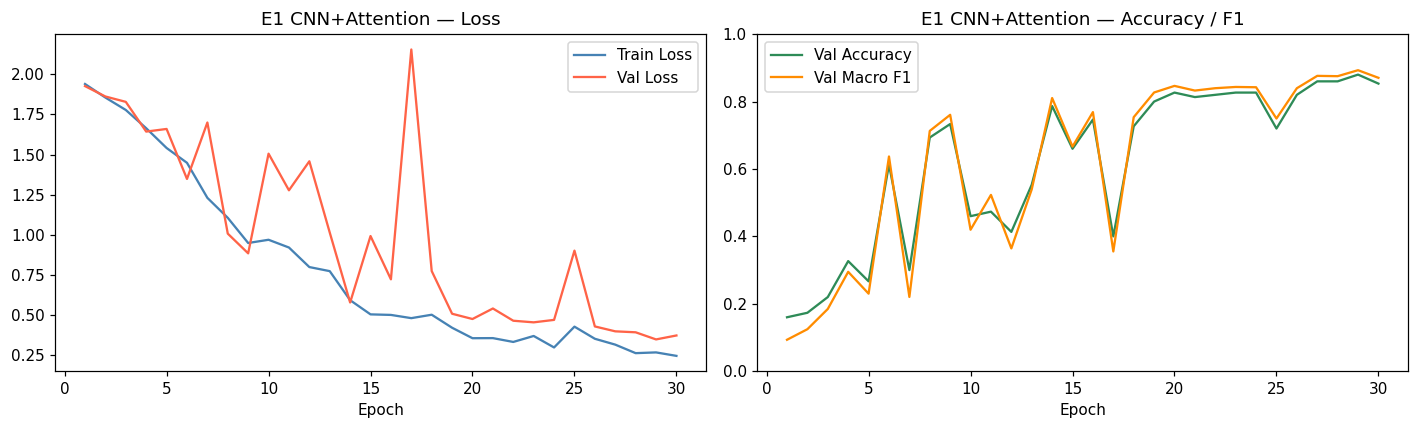

Best val acc : 0.880
Best val F1  : 0.893


In [10]:
cnn_model = CNNAttentionClassifier(in_channels=1, num_classes=len(SWARAS)).to(DEVICE)
print("Parameters:", sum(p.numel() for p in cnn_model.parameters() if p.requires_grad))

cls_history = train_classifier(cnn_model, tr_loader_cls, va_loader_cls, epochs=30, lr=1e-3)

# ── Save ───────────────────────────────────────────────────────────────────
cnn_path = os.path.join(SAVE_DIR, f"{EXPERIMENT}_cnn_attention.pth")
torch.save(cnn_model.state_dict(), cnn_path)
print(f"\nSaved → {cnn_path}")

plot_cls_history(cls_history, title=f"{EXPERIMENT} CNN+Attention")
print(f"Best val acc : {max(cls_history['val_acc']):.3f}")
print(f"Best val F1  : {max(cls_history['val_f1']):.3f}")


## Cell 9 — Classification Report: CNN+Attention

In [11]:
cnn_model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for xb, yb in tqdm(va_loader_cls, desc="Evaluating CNN"):
        preds = cnn_model(xb.to(DEVICE)).argmax(1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(yb.numpy())

print("\n── CNN+Attention Classification Report ──")
print(classification_report(all_true, all_preds, target_names=le.classes_))


Evaluating CNN: 100%|██████████| 10/10 [00:00<00:00, 272.53it/s]


── CNN+Attention Classification Report ──
              precision    recall  f1-score   support

         dha       0.65      0.95      0.77        21
          ga       0.83      0.83      0.83        24
          ma       0.78      0.95      0.86        19
          ni       0.95      0.59      0.73        32
          pa       1.00      1.00      1.00        14
          re       0.94      1.00      0.97        16
          sa       1.00      0.88      0.93        24

    accuracy                           0.85       150
   macro avg       0.88      0.89      0.87       150
weighted avg       0.88      0.85      0.85       150



## Cell 10 — Train RFC Baseline

In [12]:
# ── Collect flat RFC features ──────────────────────────────────────────────
rfc_X = np.array(full_dataset.rfc_X)
rfc_y = np.array([full_dataset.y[i] for i in range(len(full_dataset))])

tr_Xr, va_Xr = rfc_X[tr_idx], rfc_X[va_idx]
tr_yr, va_yr = rfc_y[tr_idx], rfc_y[va_idx]

print(f"RFC feature vector size: {rfc_X.shape[1]}")

rfc = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)
for _ in tqdm([1], desc="Fitting RFC"):
    rfc.fit(tr_Xr, tr_yr)

rfc_preds = rfc.predict(va_Xr)
print(f"RFC val accuracy: {accuracy_score(va_yr, rfc_preds):.3f}")
print(f"RFC val macro F1: {f1_score(va_yr, rfc_preds, average='macro'):.3f}")
print()
print("── RFC Classification Report ──")
print(classification_report(va_yr, rfc_preds, target_names=le.classes_))

rfc_path = os.path.join(SAVE_DIR, f"{EXPERIMENT}_rfc.pkl")
le_path  = os.path.join(SAVE_DIR, f"{EXPERIMENT}_label_encoder.pkl")
with open(rfc_path, "wb") as f: pickle.dump(rfc, f)
with open(le_path,  "wb") as f: pickle.dump(le,  f)
print(f"Saved → {rfc_path}")


RFC feature vector size: 320


Fitting RFC: 100%|██████████| 1/1 [00:02<00:00,  2.85s/it]

RFC val accuracy: 0.947
RFC val macro F1: 0.946

── RFC Classification Report ──
              precision    recall  f1-score   support

         dha       0.95      0.95      0.95        21
          ga       1.00      0.88      0.93        24
          ma       0.86      1.00      0.93        19
          ni       1.00      0.94      0.97        32
          pa       0.88      1.00      0.93        14
          re       0.94      1.00      0.97        16
          sa       0.96      0.92      0.94        24

    accuracy                           0.95       150
   macro avg       0.94      0.95      0.95       150
weighted avg       0.95      0.95      0.95       150

Saved → /content/E1_rfc.pkl


## Cell 11 — Build Segmentation Dataset

In [13]:
seg_dataset = FluteSegmentationDataset(MELODY_CSV, MELODY_AUDIO,
                                        features=FEATURES,
                                        max_len_frames=MAX_LEN_FRAMES)
print(f"Total melody files: {len(seg_dataset)}")

n_seg   = len(seg_dataset)
s_idx   = list(range(n_seg))
random.seed(42)
random.shuffle(s_idx)
s_split = int(0.8 * n_seg)
tr_si, va_si = s_idx[:s_split], s_idx[s_split:]

tr_seg_loader = DataLoader(Subset(seg_dataset, tr_si), batch_size=8, shuffle=True,  num_workers=0)
va_seg_loader = DataLoader(Subset(seg_dataset, va_si), batch_size=8, shuffle=False, num_workers=0)
print(f"Seg train: {len(tr_si)} | Seg val: {len(va_si)}")


Total melody files: 1000
Seg train: 800 | Seg val: 200


## Cell 12 — Train Segmentation CRNN+Attention

Seg model parameters: 1090594


Segmentation training:   4%|▍         | 1/25 [06:48<2:43:30, 408.78s/it]

  Epoch 01/25  train_loss=0.3667  val_loss=0.1381  val_f1=0.791  prec=0.664  rec=0.977


Segmentation training:  20%|██        | 5/25 [09:28<24:02, 72.11s/it]

  Epoch 05/25  train_loss=0.0647  val_loss=0.0833  val_f1=0.857  prec=0.758  rec=0.987


Segmentation training:  40%|████      | 10/25 [12:48<11:07, 44.49s/it]

... (3 outputs left out)

Segmentation training:  80%|████████  | 20/25 [19:34<03:24, 40.82s/it]

  Epoch 20/25  train_loss=0.0019  val_loss=0.1930  val_f1=0.947  prec=0.938  rec=0.956


Segmentation training: 100%|██████████| 25/25 [23:02<00:00, 55.29s/it]


  Epoch 25/25  train_loss=0.0006  val_loss=0.2245  val_f1=0.948  prec=0.943  rec=0.953

Saved → /content/E1_seg_crnn.pth


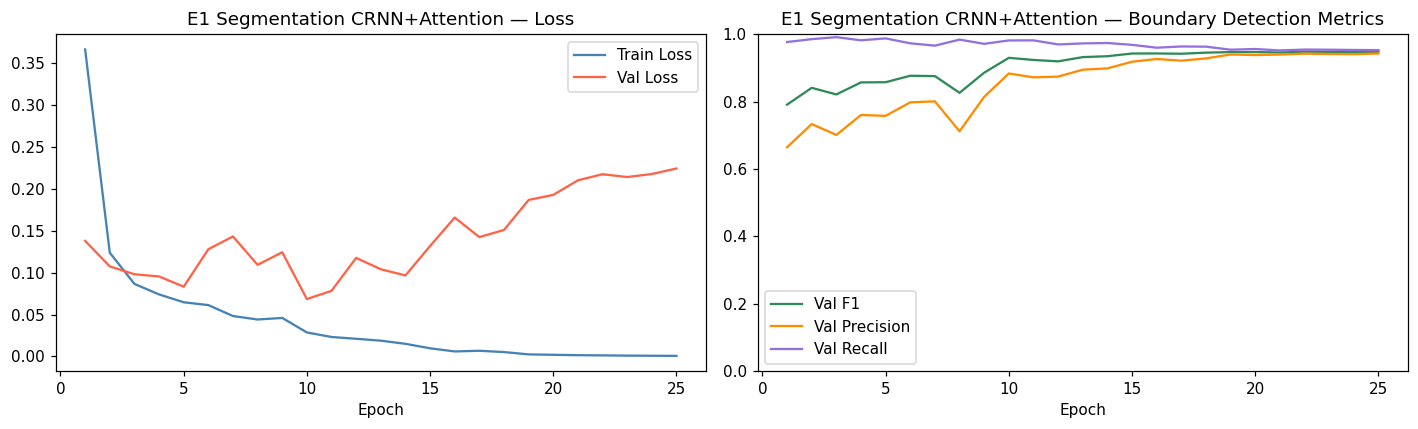

Best val F1        : 0.948
Best val Precision : 0.943
Best val Recall    : 0.991


In [14]:
seg_model = FluteSegmentationCRNN(in_channels=1).to(DEVICE)
print("Seg model parameters:", sum(p.numel() for p in seg_model.parameters() if p.requires_grad))

seg_history = train_segmentation(seg_model, tr_seg_loader, va_seg_loader,
                                  epochs=25, lr=1e-3, pos_weight=15.0)

seg_path = os.path.join(SAVE_DIR, f"{EXPERIMENT}_seg_crnn.pth")
torch.save(seg_model.state_dict(), seg_path)
print(f"\nSaved → {seg_path}")

plot_seg_history(seg_history, title=f"{EXPERIMENT} Segmentation CRNN+Attention")
print(f"Best val F1        : {max(seg_history['val_f1']):.3f}")
print(f"Best val Precision : {max(seg_history['val_precision']):.3f}")
print(f"Best val Recall    : {max(seg_history['val_recall']):.3f}")


## Cell 13 — Full Inference Pipeline

In [15]:
def classify_segment(audio_clip, cnn_m, rfc_m, le_m):
    """Returns (cnn_label, rfc_label) for a single audio clip."""
    tensor   = build_feature_tensor(audio_clip, FEATURES, fixed_frames=FIXED_FRAMES)
    rfc_feat = get_rfc_features(tensor)

    cnn_m.eval()
    with torch.no_grad():
        x    = torch.tensor(tensor, dtype=torch.float32).unsqueeze(0).to(DEVICE)
        idx_ = cnn_m(x).argmax(1).item()
    cnn_lbl = le_m.inverse_transform([idx_])[0]
    rfc_lbl = le_m.inverse_transform([rfc_m.predict([rfc_feat])[0]])[0]
    return cnn_lbl, rfc_lbl


def run_pipeline(audio_path,
                 threshold      = 0.5,
                 min_gap_sec    = 0.15,
                 min_seg_dur    = 0.20,
                 end_margin     = 0.30):
    """
    Full inference pipeline.
    Uses models already in memory: seg_model, cnn_model, rfc, le
    """
    # ── Load audio ─────────────────────────────────────────────────────────
    y, _     = librosa.load(audio_path, sr=SR)
    duration = len(y) / SR

    # ── Build features for segmentation (no truncation — full audio) ───────
    tensor  = build_feature_tensor(y, FEATURES)            # [C, N_MELS, T]
    # Sliding window if longer than MAX_LEN_FRAMES
    T_total = tensor.shape[2]
    if T_total <= MAX_LEN_FRAMES:
        inp    = torch.tensor(tensor, dtype=torch.float32).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            raw_logits = seg_model(inp).squeeze(0).cpu().numpy()
        preds_full = torch.sigmoid(torch.tensor(raw_logits)).numpy()
    else:
        preds_full = np.zeros(T_total, dtype=np.float32)
        step  = MAX_LEN_FRAMES // 2
        start = 0
        while start < T_total:
            end   = min(start + MAX_LEN_FRAMES, T_total)
            chunk = tensor[:, :, start:end]
            if chunk.shape[2] < MAX_LEN_FRAMES:
                chunk = np.pad(chunk, ((0,0),(0,0),(0, MAX_LEN_FRAMES-chunk.shape[2])))
            inp   = torch.tensor(chunk, dtype=torch.float32).unsqueeze(0).to(DEVICE)
            with torch.no_grad():
                logits = seg_model(inp).squeeze(0).cpu().numpy()
            prob   = torch.sigmoid(torch.tensor(logits)).numpy()
            actual = end - start
            preds_full[start:end] = np.maximum(preds_full[start:end], prob[:actual])
            start += step

    time_axis = np.arange(T_total) * (HOP_LENGTH / SR)

    # ── Collect & suppress boundaries ──────────────────────────────────────
    raw_times  = time_axis[preds_full > threshold]
    boundaries = []
    if len(raw_times):
        last = raw_times[0]; boundaries.append(last)
        for t in raw_times[1:]:
            if t - last > min_gap_sec:
                boundaries.append(t); last = t

    if boundaries and (duration - boundaries[-1]) <= end_margin:
        print(f"  [Edge] Dropping last boundary at {boundaries[-1]:.3f}s")
        boundaries = boundaries[:-1]

    print(f"Boundaries detected: {len(boundaries)}")

    # ── Build segment list ──────────────────────────────────────────────────
    cuts = [0.0] + boundaries + [duration]
    segments = []
    for i in range(len(cuts)-1):
        t0, t1 = cuts[i], cuts[i+1]
        if t1 - t0 >= min_seg_dur:
            segments.append((t0, t1))
        else:
            print(f"  [Edge] Dropping short segment [{t0:.3f}–{t1:.3f}]s")

    print(f"Classifying {len(segments)} segments...")

    # ── Classify ───────────────────────────────────────────────────────────
    cnn_seq, rfc_seq = [], []
    for i, (t0, t1) in enumerate(tqdm(segments, desc="Classifying segments")):
        clip    = y[int(t0*SR):int(t1*SR)]
        c, r    = classify_segment(clip, cnn_model, rfc, le)
        cnn_seq.append(c); rfc_seq.append(r)
        print(f"  Seg {i+1:02d}  [{t0:.3f}s – {t1:.3f}s]  CNN={c}  RFC={r}")

    print(f"\nCNN+Attention : {' → '.join(cnn_seq)}")
    print(f"RFC           : {' → '.join(rfc_seq)}")

    # ── Visualisation ──────────────────────────────────────────────────────
    # Row 1: Mel spectrogram (always shown regardless of experiment)
    mel_spec = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=N_FFT,
                                              hop_length=HOP_LENGTH, n_mels=N_MELS)
    log_mel_vis = librosa.power_to_db(mel_spec, ref=np.max)

    fig, axes = plt.subplots(4, 1, figsize=(16, 14))
    fig.suptitle(f"{EXPERIMENT} — {os.path.basename(audio_path)}", fontsize=13, fontweight='bold')

    # Mel
    img = librosa.display.specshow(log_mel_vis, sr=SR, hop_length=HOP_LENGTH,
                                   x_axis='time', y_axis='mel',
                                   cmap='magma', ax=axes[0])
    fig.colorbar(img, ax=axes[0], format='%+2.0f dB')
    axes[0].set_title("Log-Mel Spectrogram")
    for t0, _ in segments:
        axes[0].axvline(t0, color='cyan', lw=1.5, alpha=0.85)

    # Boundary probability
    axes[1].plot(time_axis, preds_full, color='crimson', lw=1.5, label='Boundary prob')
    axes[1].axhline(threshold, color='gray', ls='--', lw=1, label=f'Threshold={threshold}')
    for t0, _ in segments:
        axes[1].axvline(t0, color='darkgreen', ls='--', lw=1.2)
    axes[1].fill_between(time_axis, preds_full,
                         where=(preds_full >= threshold),
                         color='red', alpha=0.25)
    axes[1].set_ylim(-0.05, 1.05); axes[1].set_xlim(0, duration)
    axes[1].set_title("Boundary Confidence"); axes[1].set_ylabel("Probability")
    axes[1].legend(loc='upper right')

    # CNN swara strip
    cmap_colors = plt.cm.Set2(np.linspace(0, 1, len(SWARAS)))
    color_map   = {s: cmap_colors[i] for i, s in enumerate(SWARAS)}
    axes[2].set_xlim(0, duration); axes[2].set_ylim(0, 1)
    for (t0, t1), lbl in zip(segments, cnn_seq):
        axes[2].barh(0.5, t1-t0, left=t0, height=0.6,
                     color=color_map.get(lbl, 'gray'), alpha=0.85, edgecolor='white', linewidth=0.8)
        if t1-t0 > 0.15:
            axes[2].text((t0+t1)/2, 0.5, lbl, ha='center', va='center',
                         fontsize=9, fontweight='bold', color='white')
    axes[2].set_title("CNN+Attention — Predicted Swara Sequence")
    axes[2].set_yticks([])
    legend_patches = [mpatches.Patch(color=color_map[s], label=s) for s in SWARAS]
    axes[2].legend(handles=legend_patches, loc='upper right', ncol=7, fontsize=8)

    # RFC swara strip
    axes[3].set_xlim(0, duration); axes[3].set_ylim(0, 1)
    for (t0, t1), lbl in zip(segments, rfc_seq):
        axes[3].barh(0.5, t1-t0, left=t0, height=0.6,
                     color=color_map.get(lbl, 'gray'), alpha=0.85, edgecolor='white', linewidth=0.8)
        if t1-t0 > 0.15:
            axes[3].text((t0+t1)/2, 0.5, lbl, ha='center', va='center',
                         fontsize=9, fontweight='bold', color='white')
    axes[3].set_title("RFC — Predicted Swara Sequence")
    axes[3].set_xlabel("Time (s)"); axes[3].set_yticks([])
    axes[3].legend(handles=legend_patches, loc='upper right', ncol=7, fontsize=8)

    plt.tight_layout()
    vis_path = os.path.join(SAVE_DIR, f"{EXPERIMENT}_pipeline_output.png")
    plt.savefig(vis_path, dpi=120, bbox_inches='tight')
    plt.show()
    print(f"Saved visualization → {vis_path}")

    return cnn_seq, rfc_seq, segments


print("Inference pipeline ready.")


Inference pipeline ready.


## Cell 14 — Run on Test WAV Files

Upload one or more test flute .wav files:


Saving test1.wav to test1.wav
Saving test2.wav to test2.wav
Saving test3.wav to test3.wav
Saving test4.wav to test4.wav
Saving test5.wav to test5.wav
Saving test6.wav to test6.wav
Saving test7.wav to test7.wav
Saving test8.wav to test8.wav
Saving test9.wav to test9.wav
Saving test10.wav to test10.wav
Saving test11.wav to test11.wav
Saving test12.wav to test12.wav
Saving test13.wav to test13.wav
Saving test14.wav to test14.wav
Saving test15.wav to test15.wav
Saving test16.wav to test16.wav
Saving test17.wav to test17.wav
Saving test18.wav to test18.wav
Saving test19.wav to test19.wav


Processing files:   0%|          | 0/19 [00:00<?, ?it/s]


Processing: test1.wav
Boundaries detected: 9
Classifying 10 segments...



Classifying segments:   0%|          | 0/10 [00:00<?, ?it/s]

  Seg 01  [0.000s – 1.161s]  CNN=sa  RFC=sa


... (2 outputs left out)


Classifying segments:  80%|████████  | 8/10 [00:00<00:00, 14.88it/s]

  Seg 06  [5.944s – 7.964s]  CNN=sa  RFC=sa
  Seg 07  [7.964s – 8.940s]  CNN=re  RFC=re
  Seg 08  [8.940s – 9.961s]  CNN=ga  RFC=ga
  Seg 09  [9.961s – 10.983s]  CNN=re  RFC=re



Classifying segments: 100%|██████████| 10/10 [00:00<00:00, 14.56it/s]


  Seg 10  [10.983s – 11.891s]  CNN=ga  RFC=ma

CNN+Attention : sa → re → re → sa → re → sa → re → ga → re → ga
RFC           : sa → sa → re → sa → re → sa → re → ga → re → ma


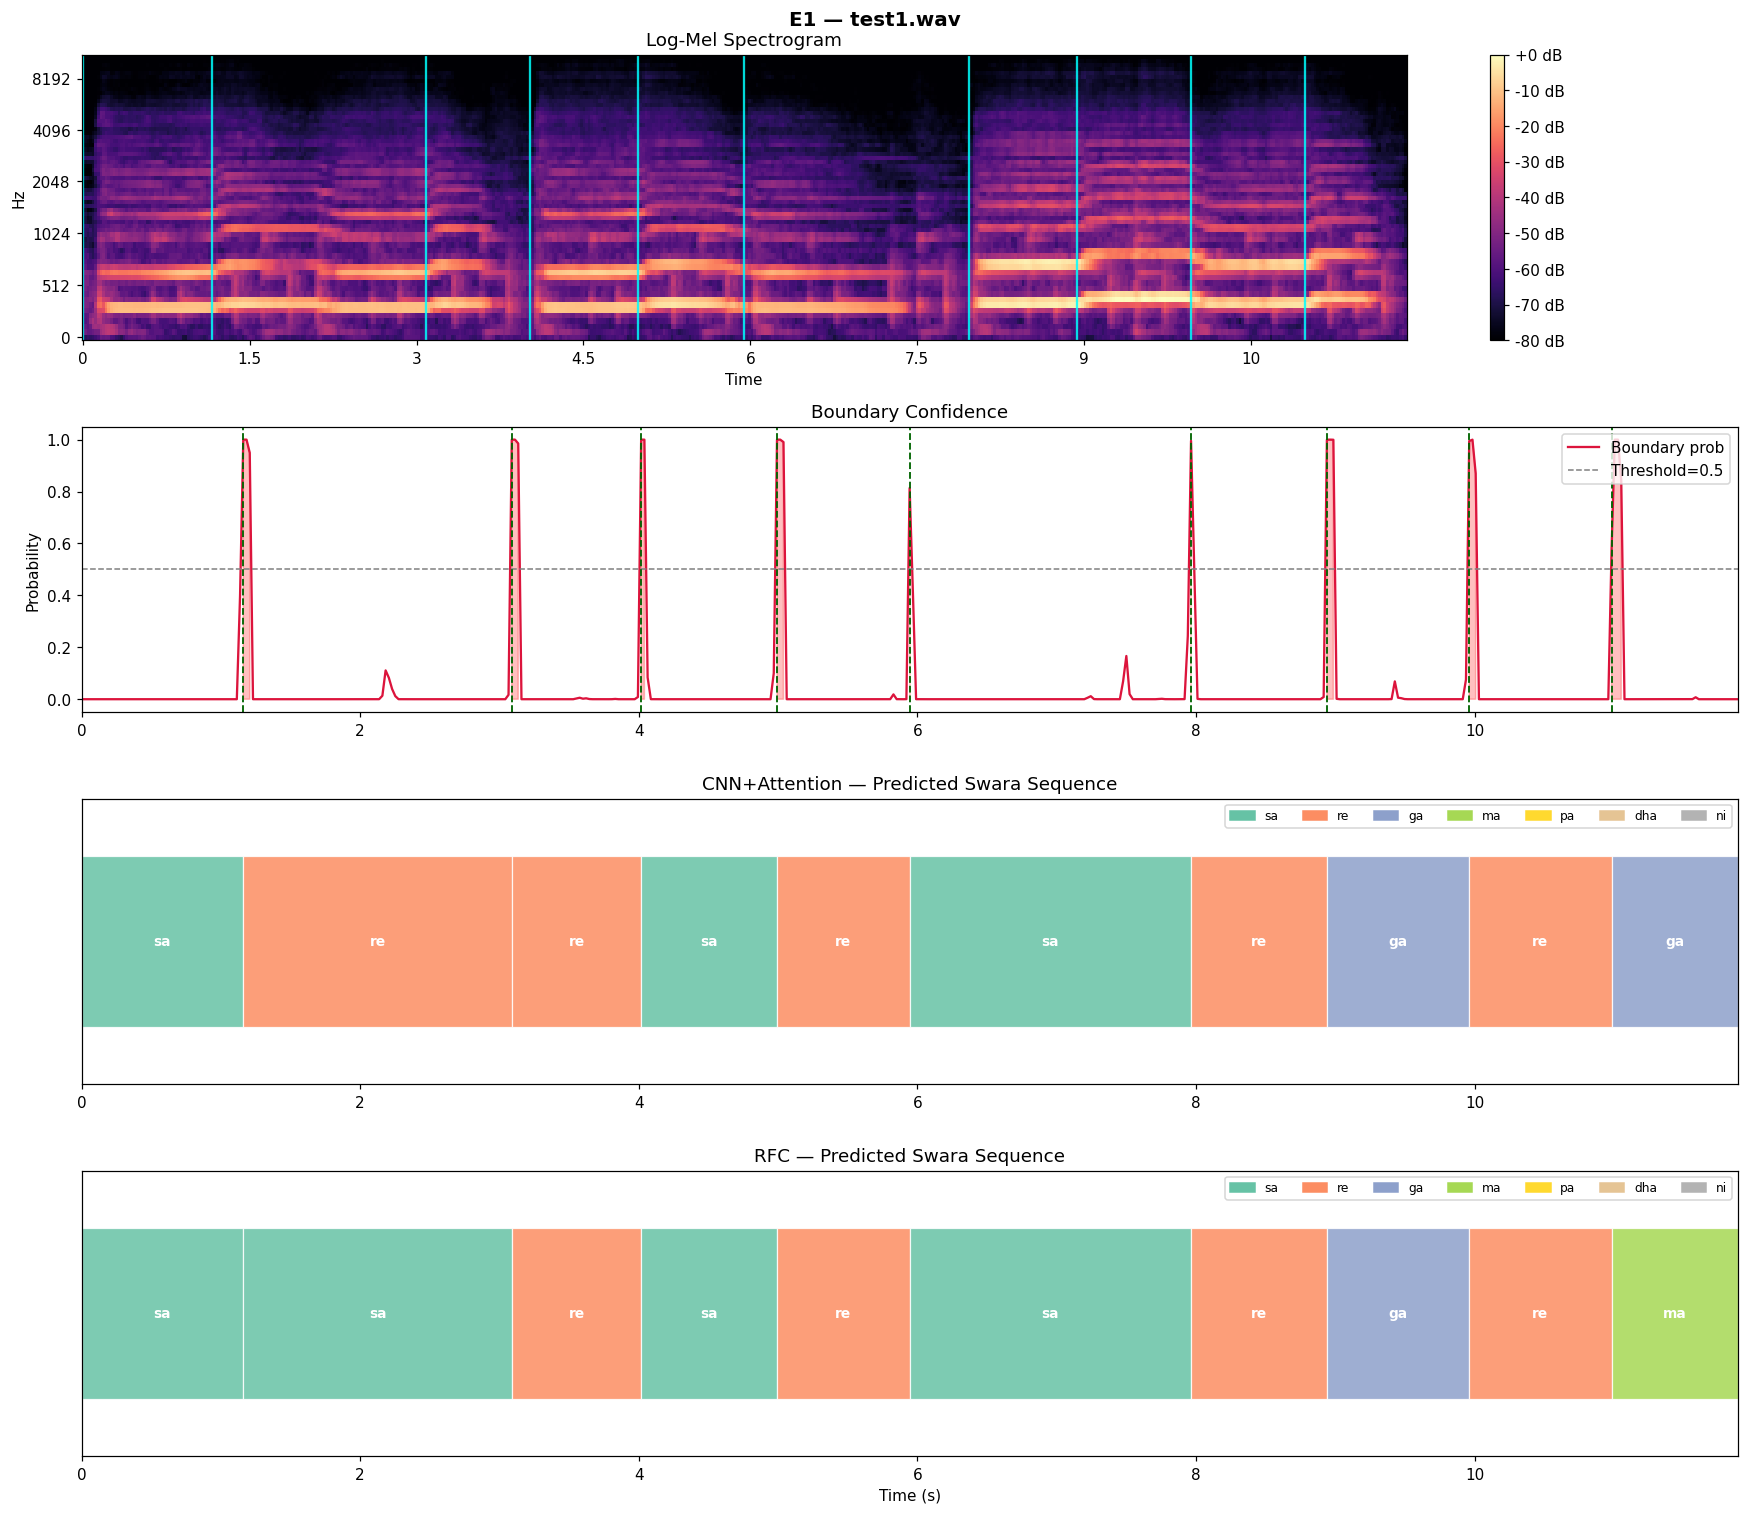

Processing files:   5%|▌         | 1/19 [00:02<00:43,  2.42s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test2.wav
  [Edge] Dropping last boundary at 3.088s
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 13.35it/s]

  Seg 01  [0.000s – 0.441s]  CNN=sa  RFC=sa
  Seg 02  [0.441s – 0.929s]  CNN=re  RFC=re
  Seg 03  [0.929s – 1.416s]  CNN=ga  RFC=ga



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 13.27it/s]


  Seg 04  [1.416s – 1.881s]  CNN=sa  RFC=sa
  Seg 05  [1.881s – 2.345s]  CNN=re  RFC=re
  Seg 06  [2.345s – 2.879s]  CNN=ga  RFC=ga


Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 13.22it/s]


  Seg 07  [2.879s – 3.367s]  CNN=ma  RFC=ma

CNN+Attention : sa → re → ga → sa → re → ga → ma
RFC           : sa → re → ga → sa → re → ga → ma


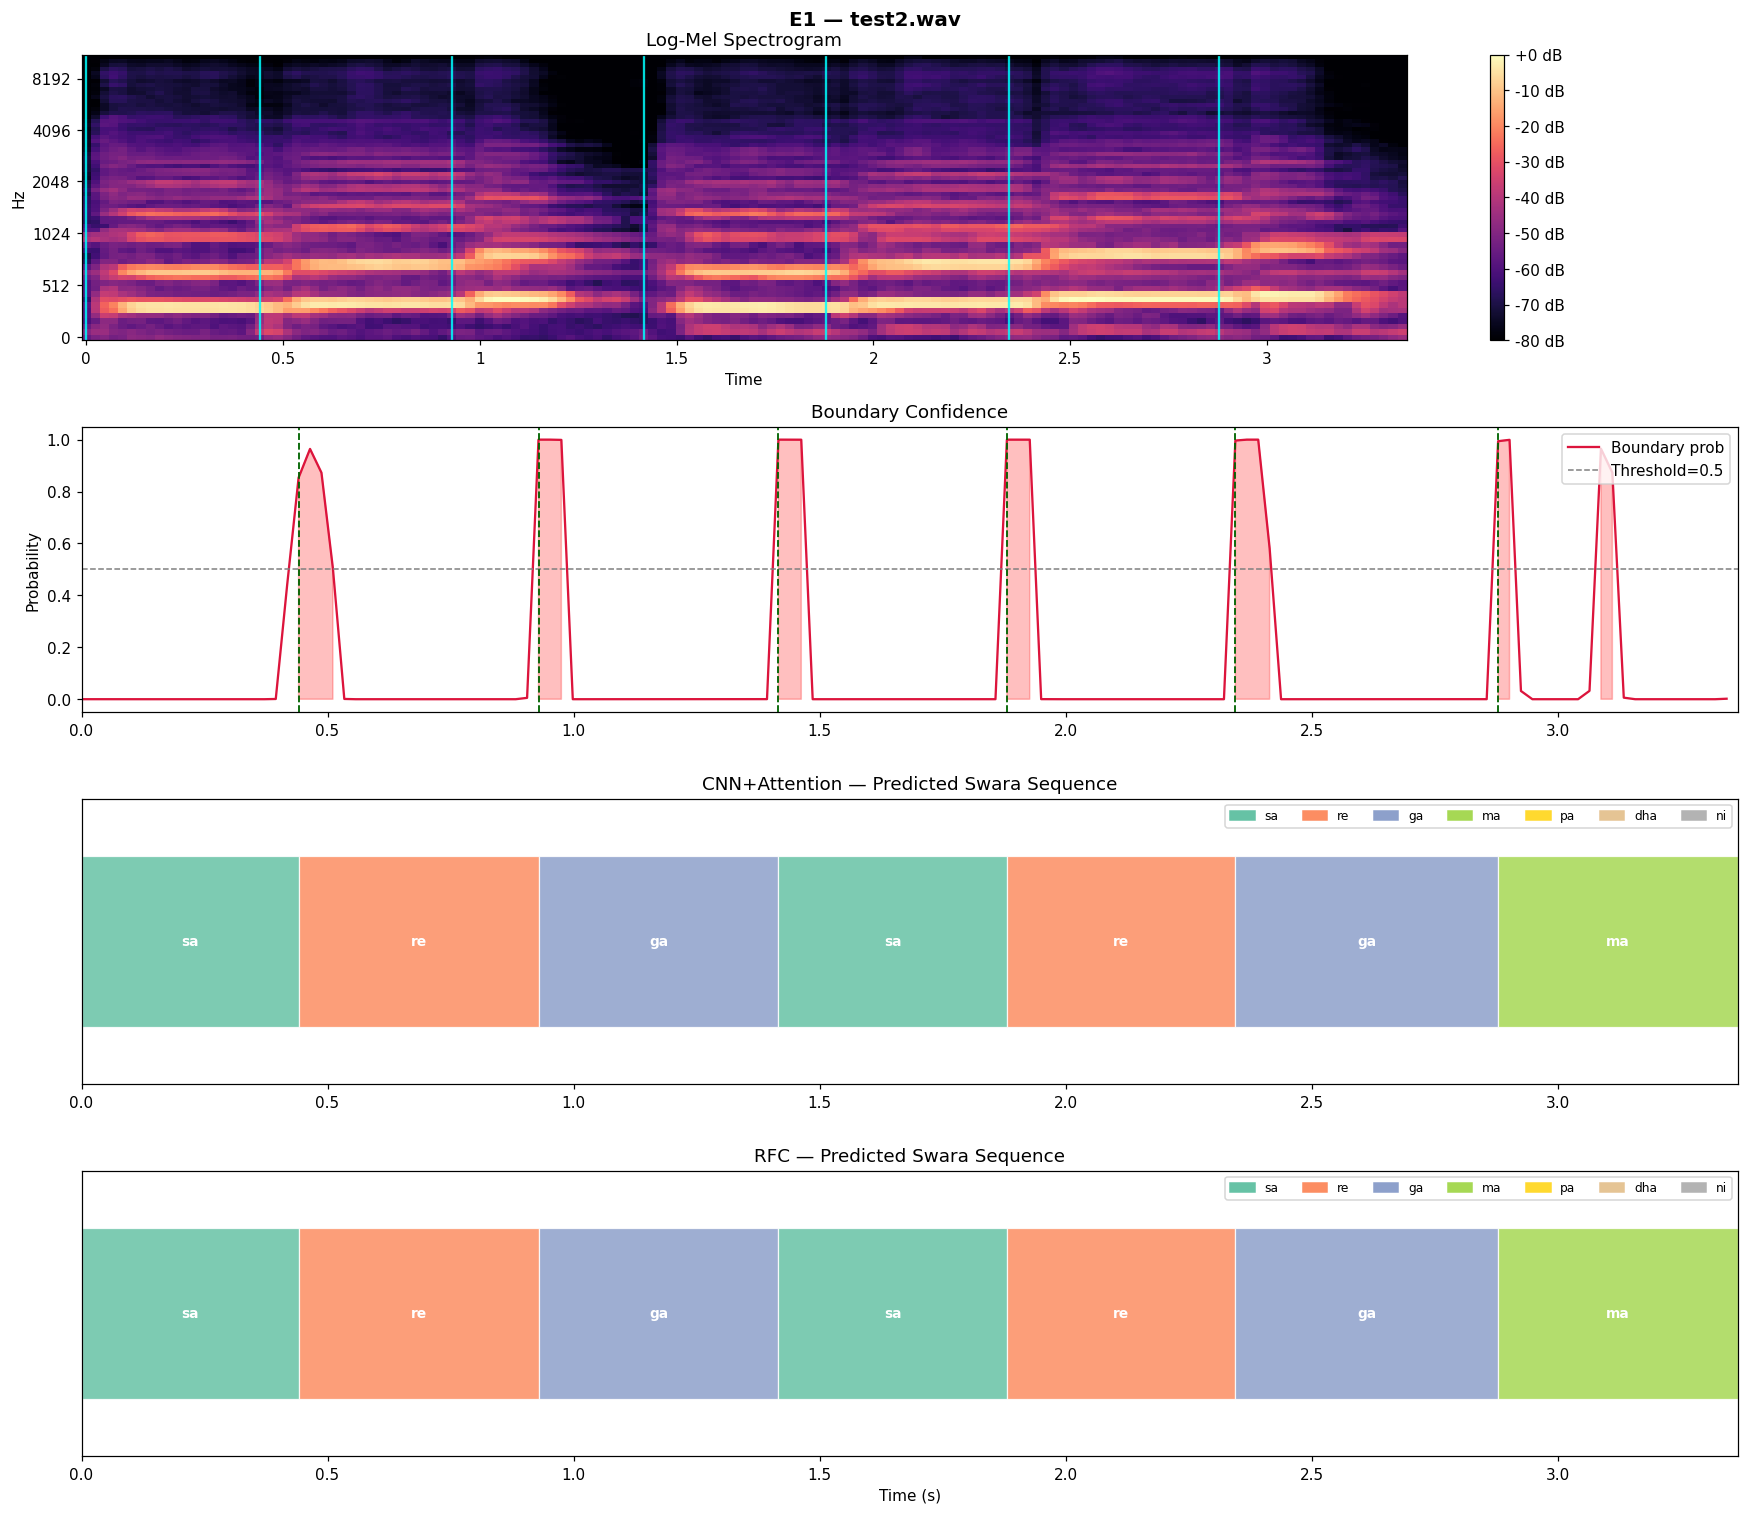

Processing files:  11%|█         | 2/19 [00:04<00:40,  2.37s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test3.wav
  [Edge] Dropping last boundary at 3.158s
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:   0%|          | 0/7 [00:00<?, ?it/s]

  Seg 01  [0.000s – 0.441s]  CNN=re  RFC=re



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 10.67it/s]

  Seg 02  [0.441s – 0.906s]  CNN=ga  RFC=re
  Seg 03  [0.906s – 1.463s]  CNN=ma  RFC=ma


... (4 outputs left out)


Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00,  7.68it/s]

  Seg 06  [2.392s – 2.902s]  CNN=ma  RFC=ma


Classifying segments: 100%|██████████| 7/7 [00:00<00:00,  8.53it/s]

  Seg 07  [2.902s – 3.386s]  CNN=re  RFC=ma

CNN+Attention : re → ga → ma → re → ga → ma → re
RFC           : re → re → ma → re → re → ma → ma


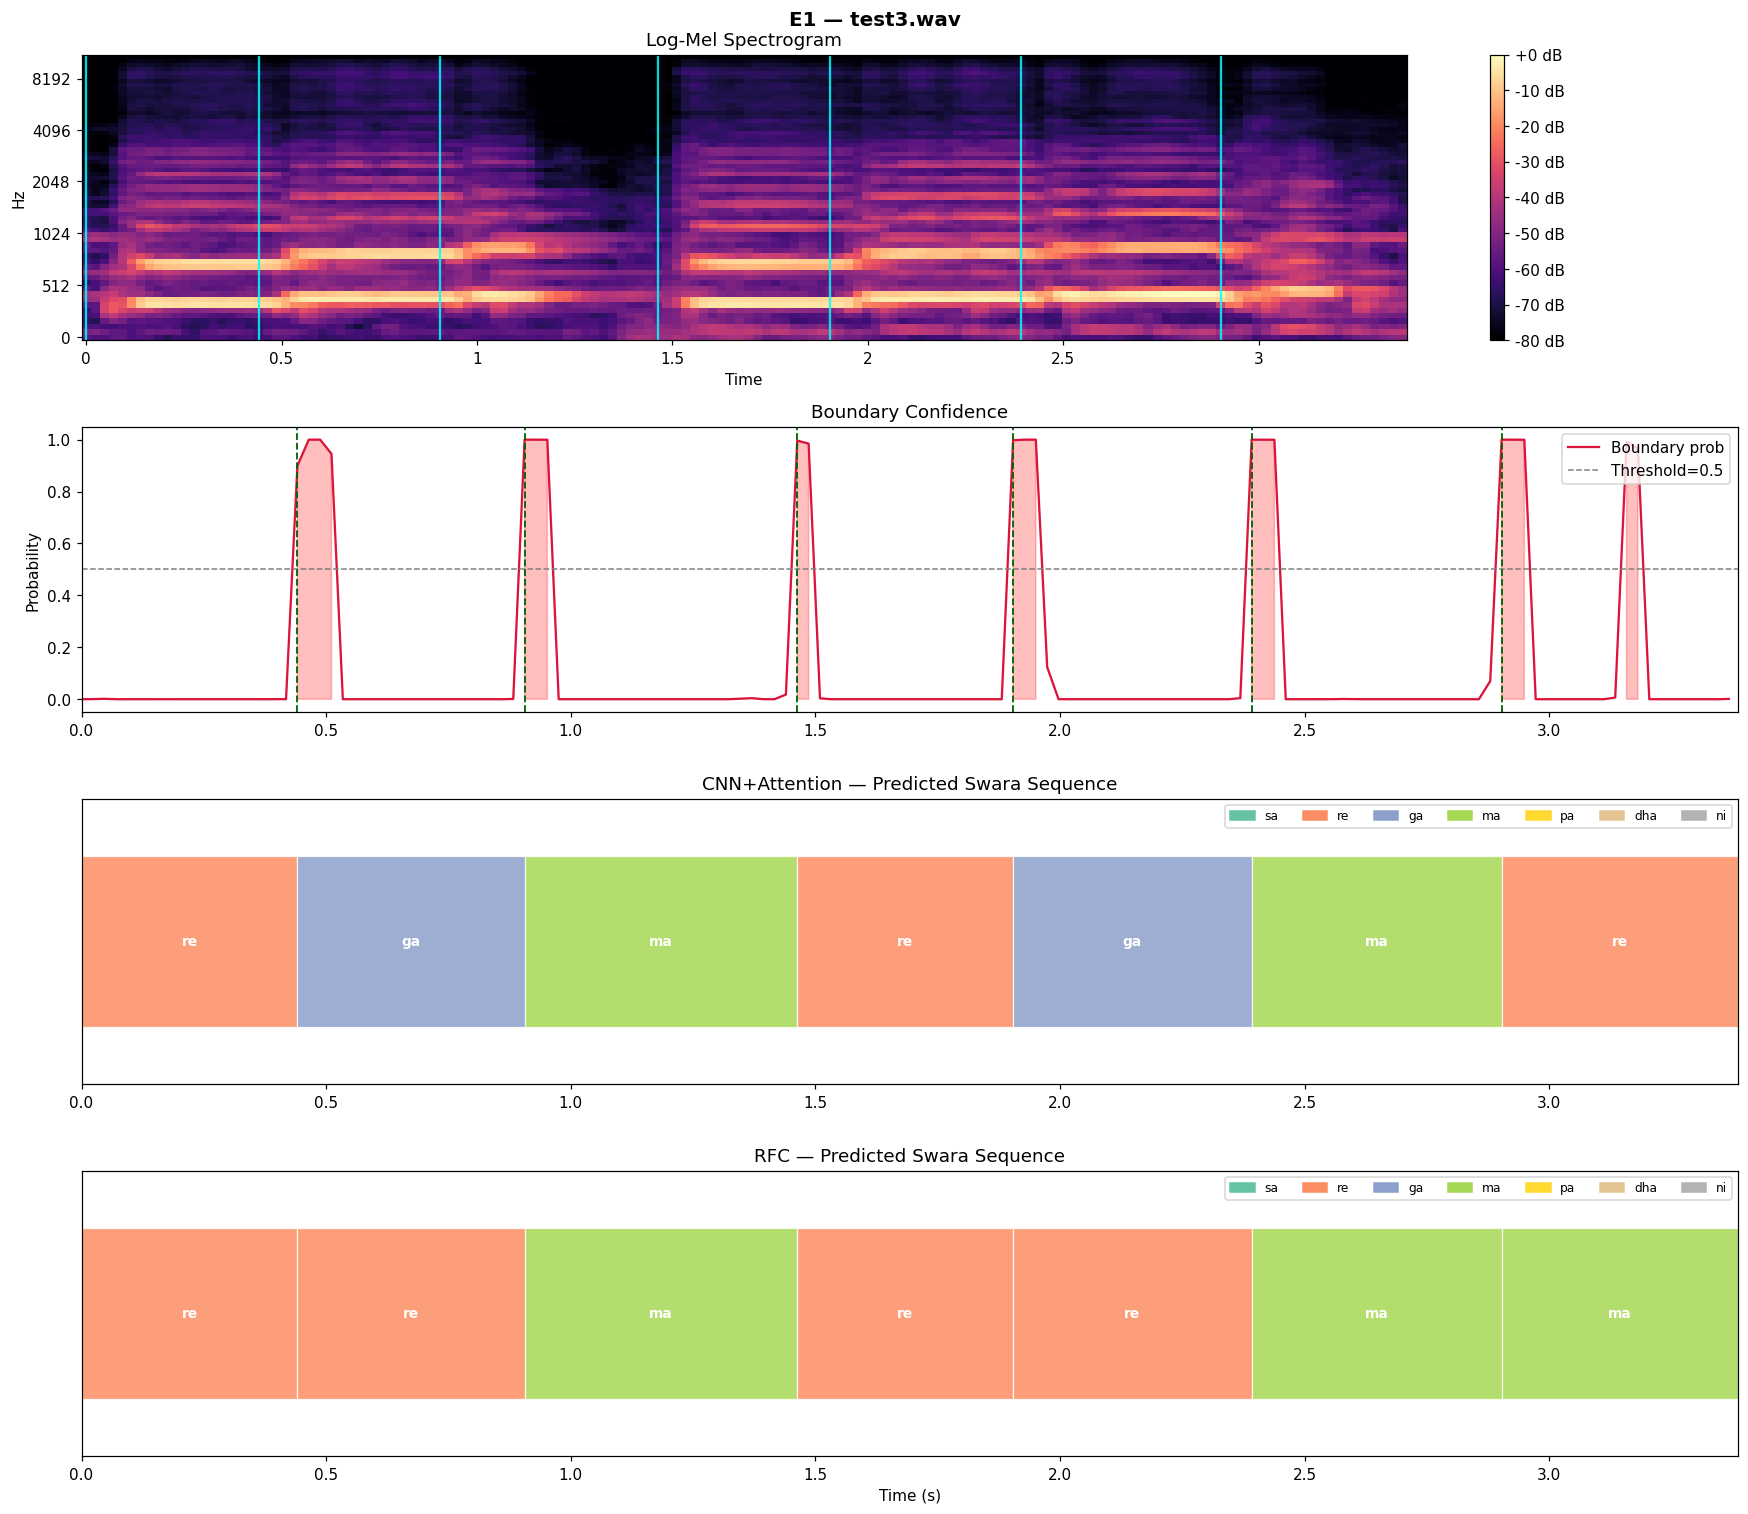

Processing files:  16%|█▌        | 3/19 [00:07<00:43,  2.70s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test4.wav
Boundaries detected: 5
Classifying 6 segments...



Classifying segments:   0%|          | 0/6 [00:00<?, ?it/s]

  Seg 01  [0.000s – 0.488s]  CNN=ga  RFC=ga



Classifying segments:  33%|███▎      | 2/6 [00:00<00:00,  8.36it/s]

  Seg 02  [0.488s – 0.998s]  CNN=ma  RFC=ma


... (4 outputs left out)


Classifying segments:  83%|████████▎ | 5/6 [00:00<00:00,  7.43it/s]

  Seg 05  [2.461s – 2.949s]  CNN=pa  RFC=pa



Classifying segments: 100%|██████████| 6/6 [00:00<00:00,  7.65it/s]

  Seg 06  [2.949s – 3.437s]  CNN=dha  RFC=dha

CNN+Attention : ga → ma → ga → ma → pa → dha
RFC           : ga → ma → ga → ma → pa → dha


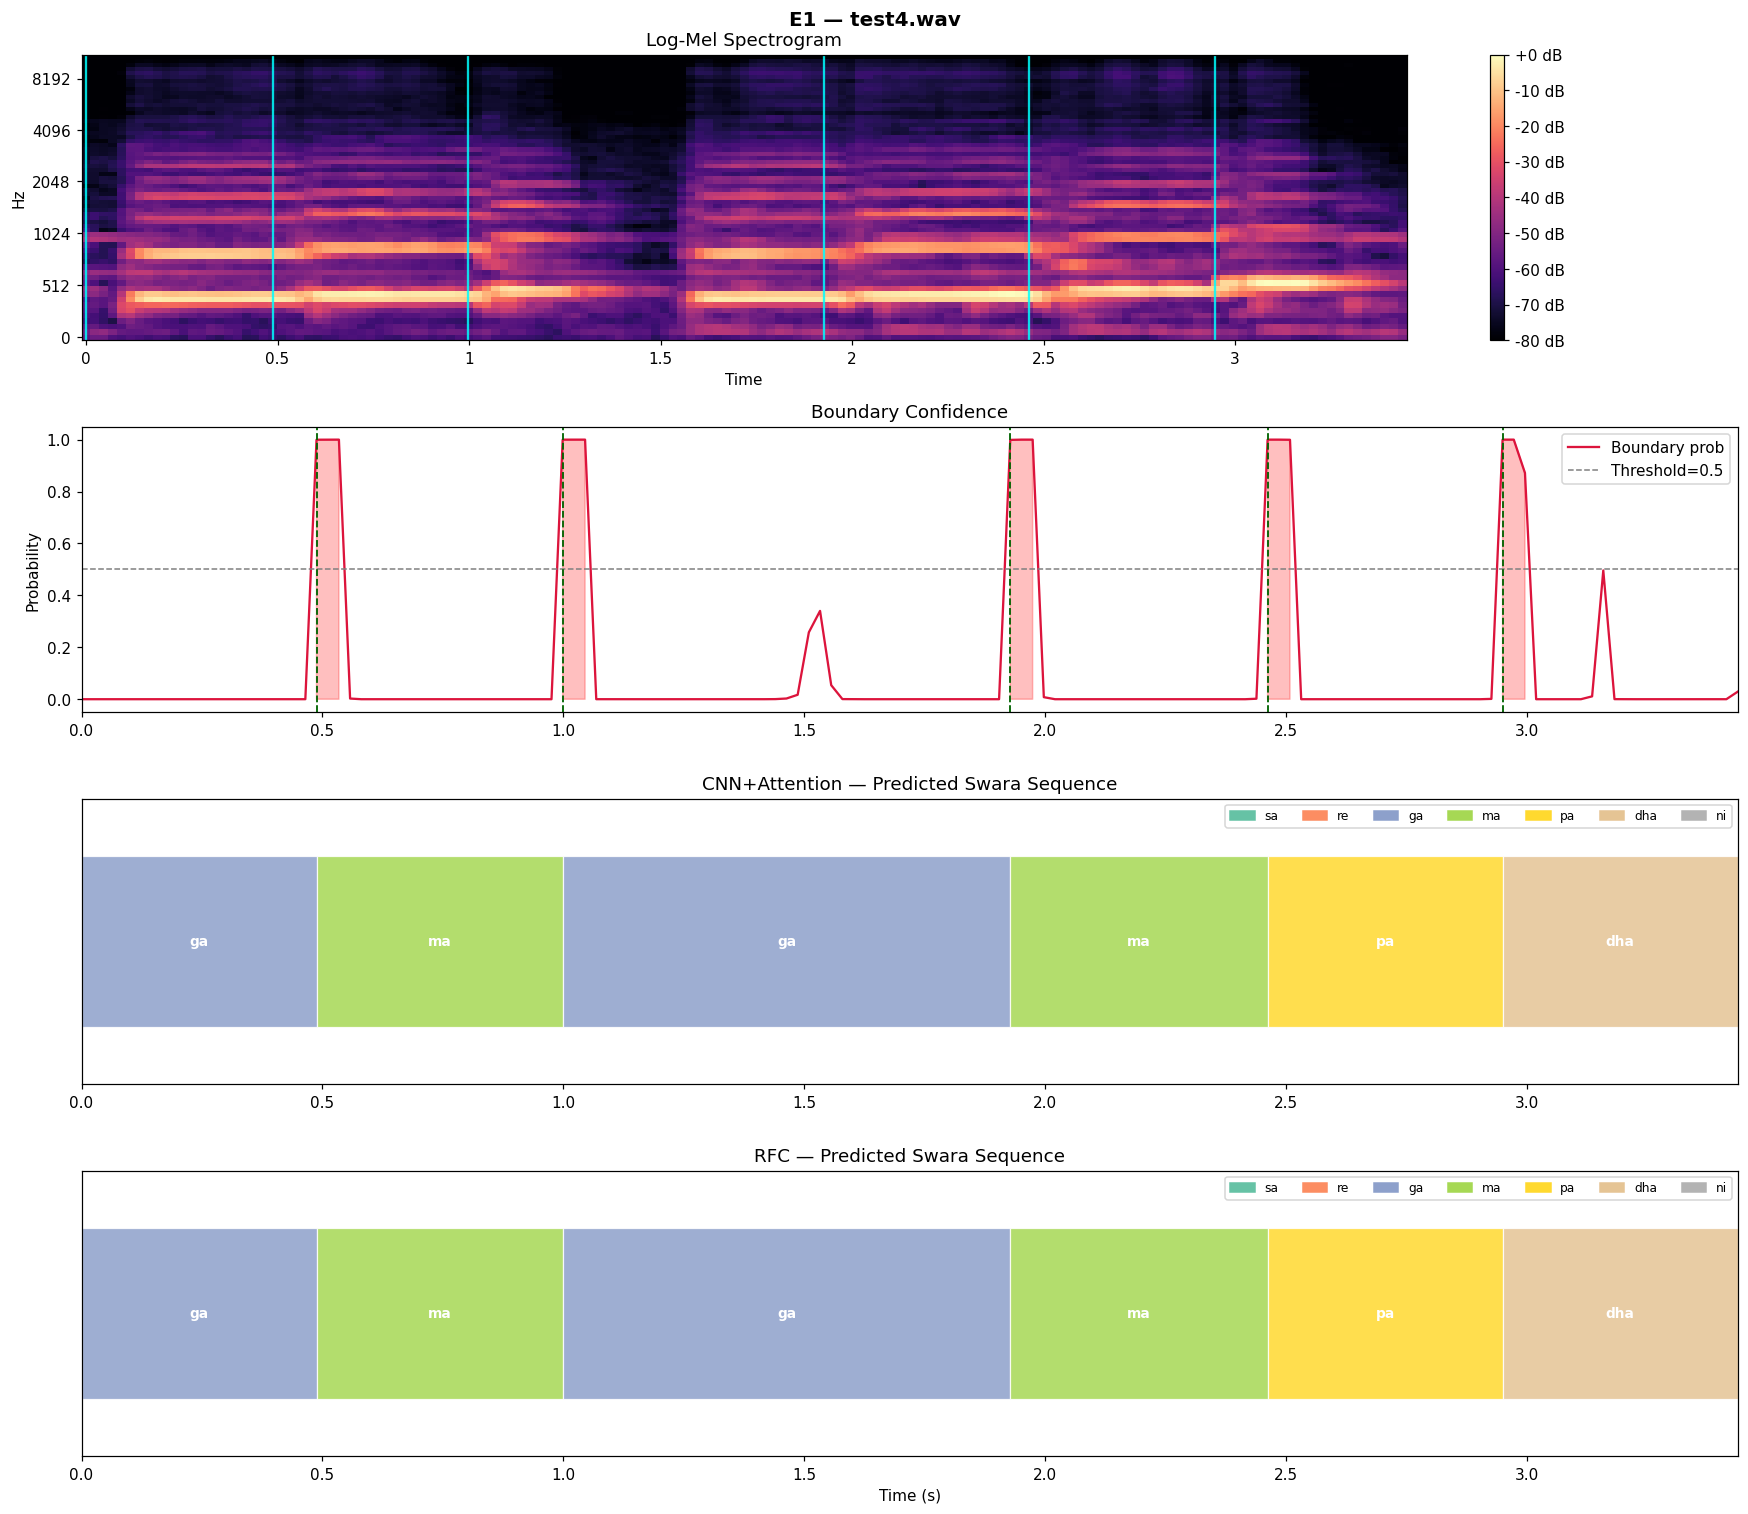

Processing files:  21%|██        | 4/19 [00:10<00:40,  2.71s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test5.wav
  [Edge] Dropping last boundary at 3.158s
Boundaries detected: 7
  [Edge] Dropping short segment [0.000–0.116]s
Classifying 7 segments...



Classifying segments:  14%|█▍        | 1/7 [00:00<00:00,  9.61it/s]

  Seg 01  [0.116s – 0.511s]  CNN=ma  RFC=ma



Classifying segments:  43%|████▎     | 3/7 [00:00<00:00, 12.84it/s]

  Seg 02  [0.511s – 0.998s]  CNN=pa  RFC=pa
  Seg 03  [0.998s – 1.533s]  CNN=dha  RFC=dha
  Seg 04  [1.533s – 1.997s]  CNN=ma  RFC=ma



Classifying segments:  71%|███████▏  | 5/7 [00:00<00:00, 12.22it/s]

  Seg 05  [1.997s – 2.461s]  CNN=pa  RFC=pa
  Seg 06  [2.461s – 2.949s]  CNN=dha  RFC=dha



Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 12.04it/s]

  Seg 07  [2.949s – 3.428s]  CNN=ni  RFC=ni

CNN+Attention : ma → pa → dha → ma → pa → dha → ni
RFC           : ma → pa → dha → ma → pa → dha → ni


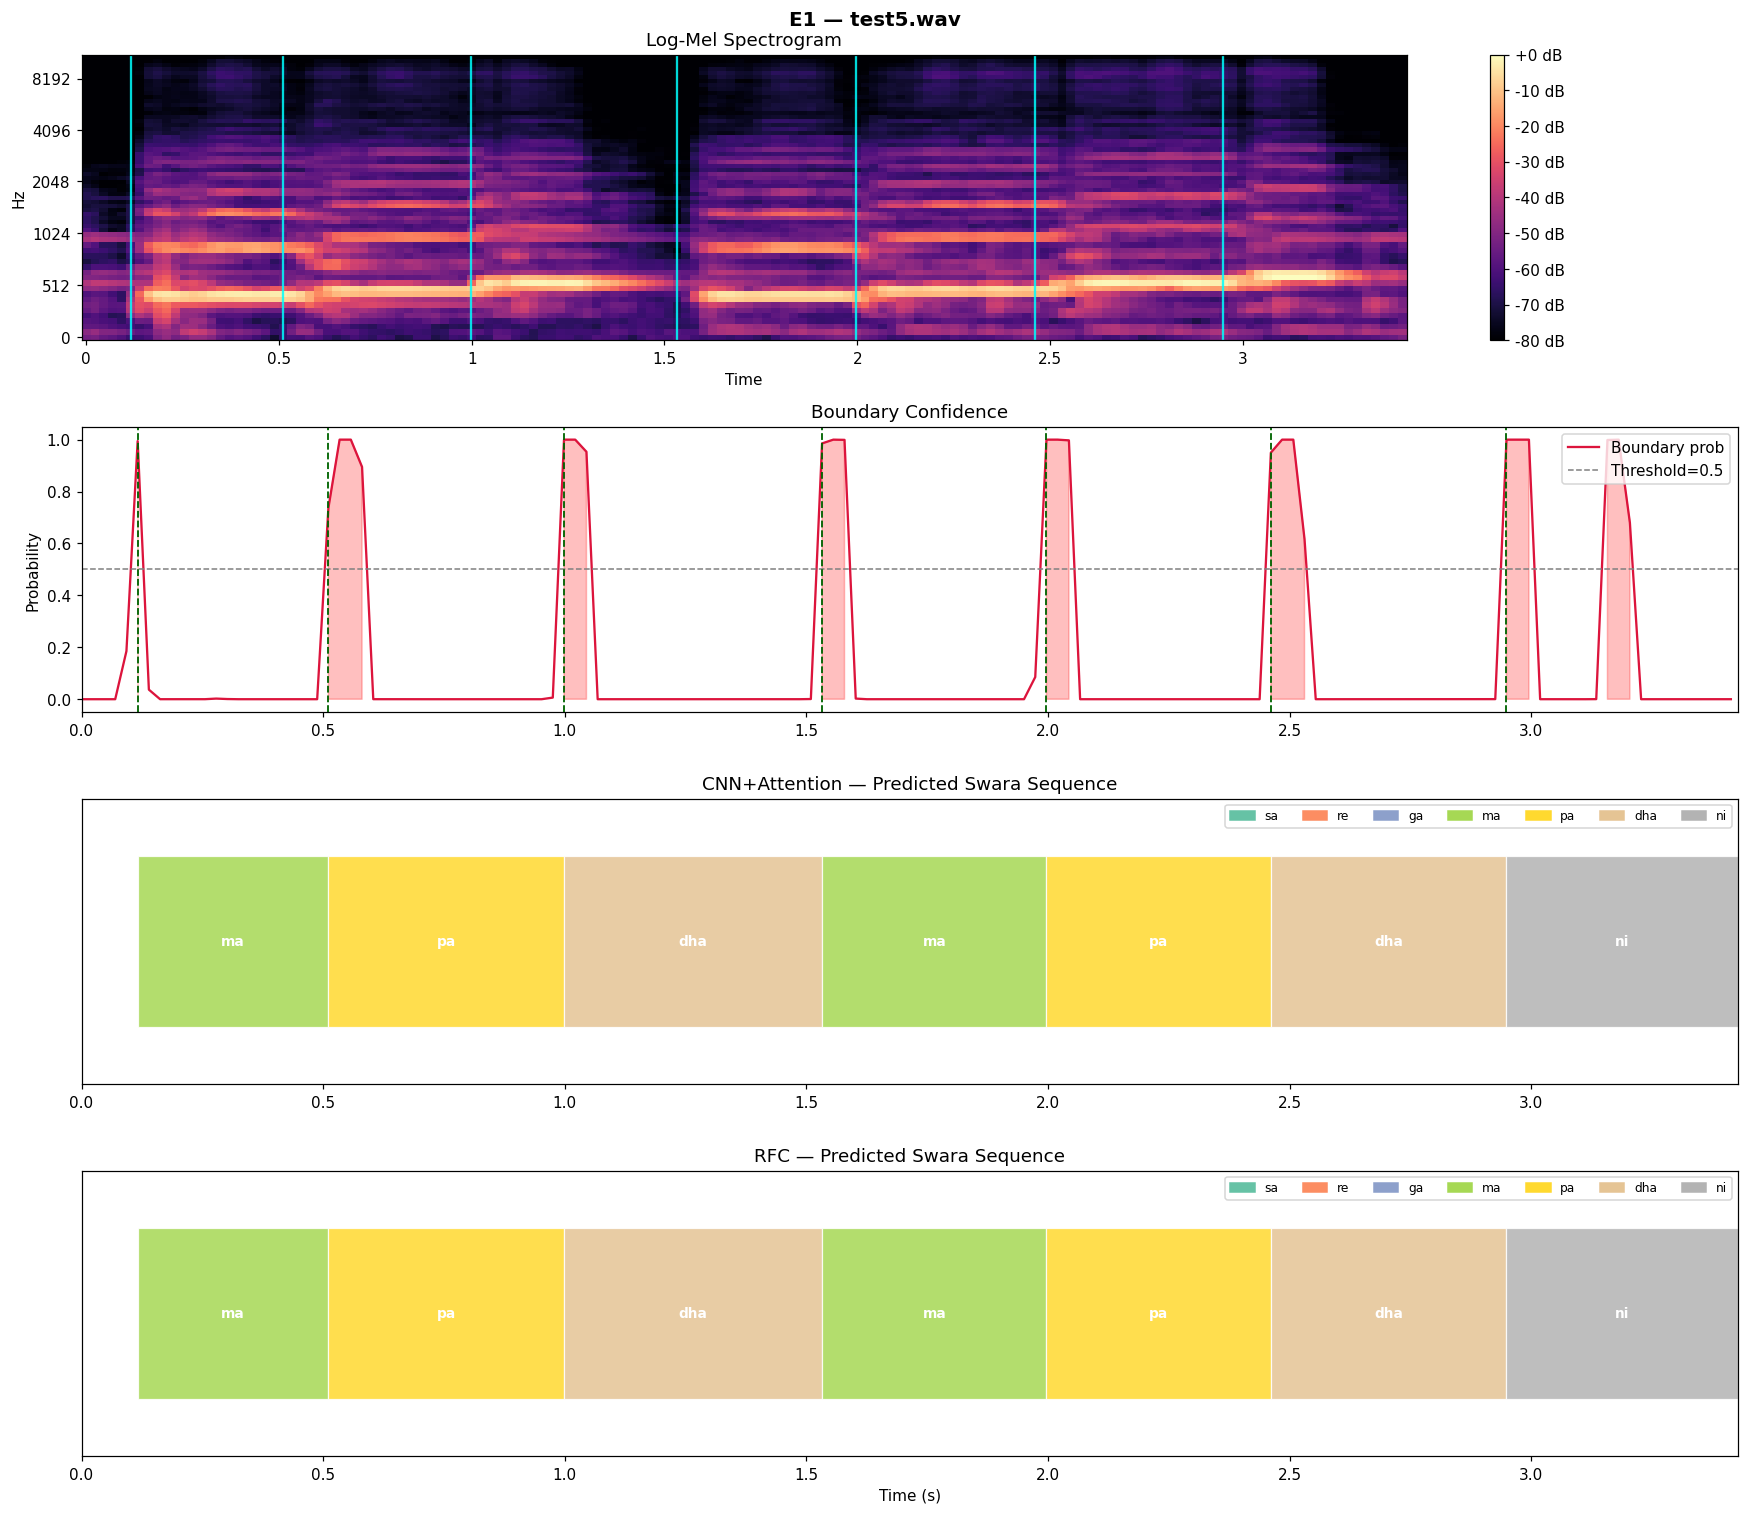

Processing files:  26%|██▋       | 5/19 [00:12<00:35,  2.52s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test6.wav
Boundaries detected: 8
  [Edge] Dropping short segment [0.000–0.070]s
Classifying 8 segments...



Classifying segments:  12%|█▎        | 1/8 [00:00<00:00,  9.68it/s]

  Seg 01  [0.070s – 0.488s]  CNN=pa  RFC=pa



Classifying segments:  25%|██▌       | 2/8 [00:00<00:00,  9.38it/s]

  Seg 02  [0.488s – 0.975s]  CNN=dha  RFC=dha
  Seg 03  [0.975s – 1.509s]  CNN=dha  RFC=dha


... (2 outputs left out)


Classifying segments:  75%|███████▌  | 6/8 [00:00<00:00, 12.84it/s]

  Seg 05  [1.974s – 2.415s]  CNN=dha  RFC=ma
  Seg 06  [2.415s – 2.670s]  CNN=dha  RFC=sa
  Seg 07  [2.670s – 2.926s]  CNN=ni  RFC=sa



Classifying segments: 100%|██████████| 8/8 [00:00<00:00, 12.22it/s]


  Seg 08  [2.926s – 3.456s]  CNN=sa  RFC=sa

CNN+Attention : pa → dha → dha → pa → dha → dha → ni → sa
RFC           : pa → dha → dha → pa → ma → sa → sa → sa


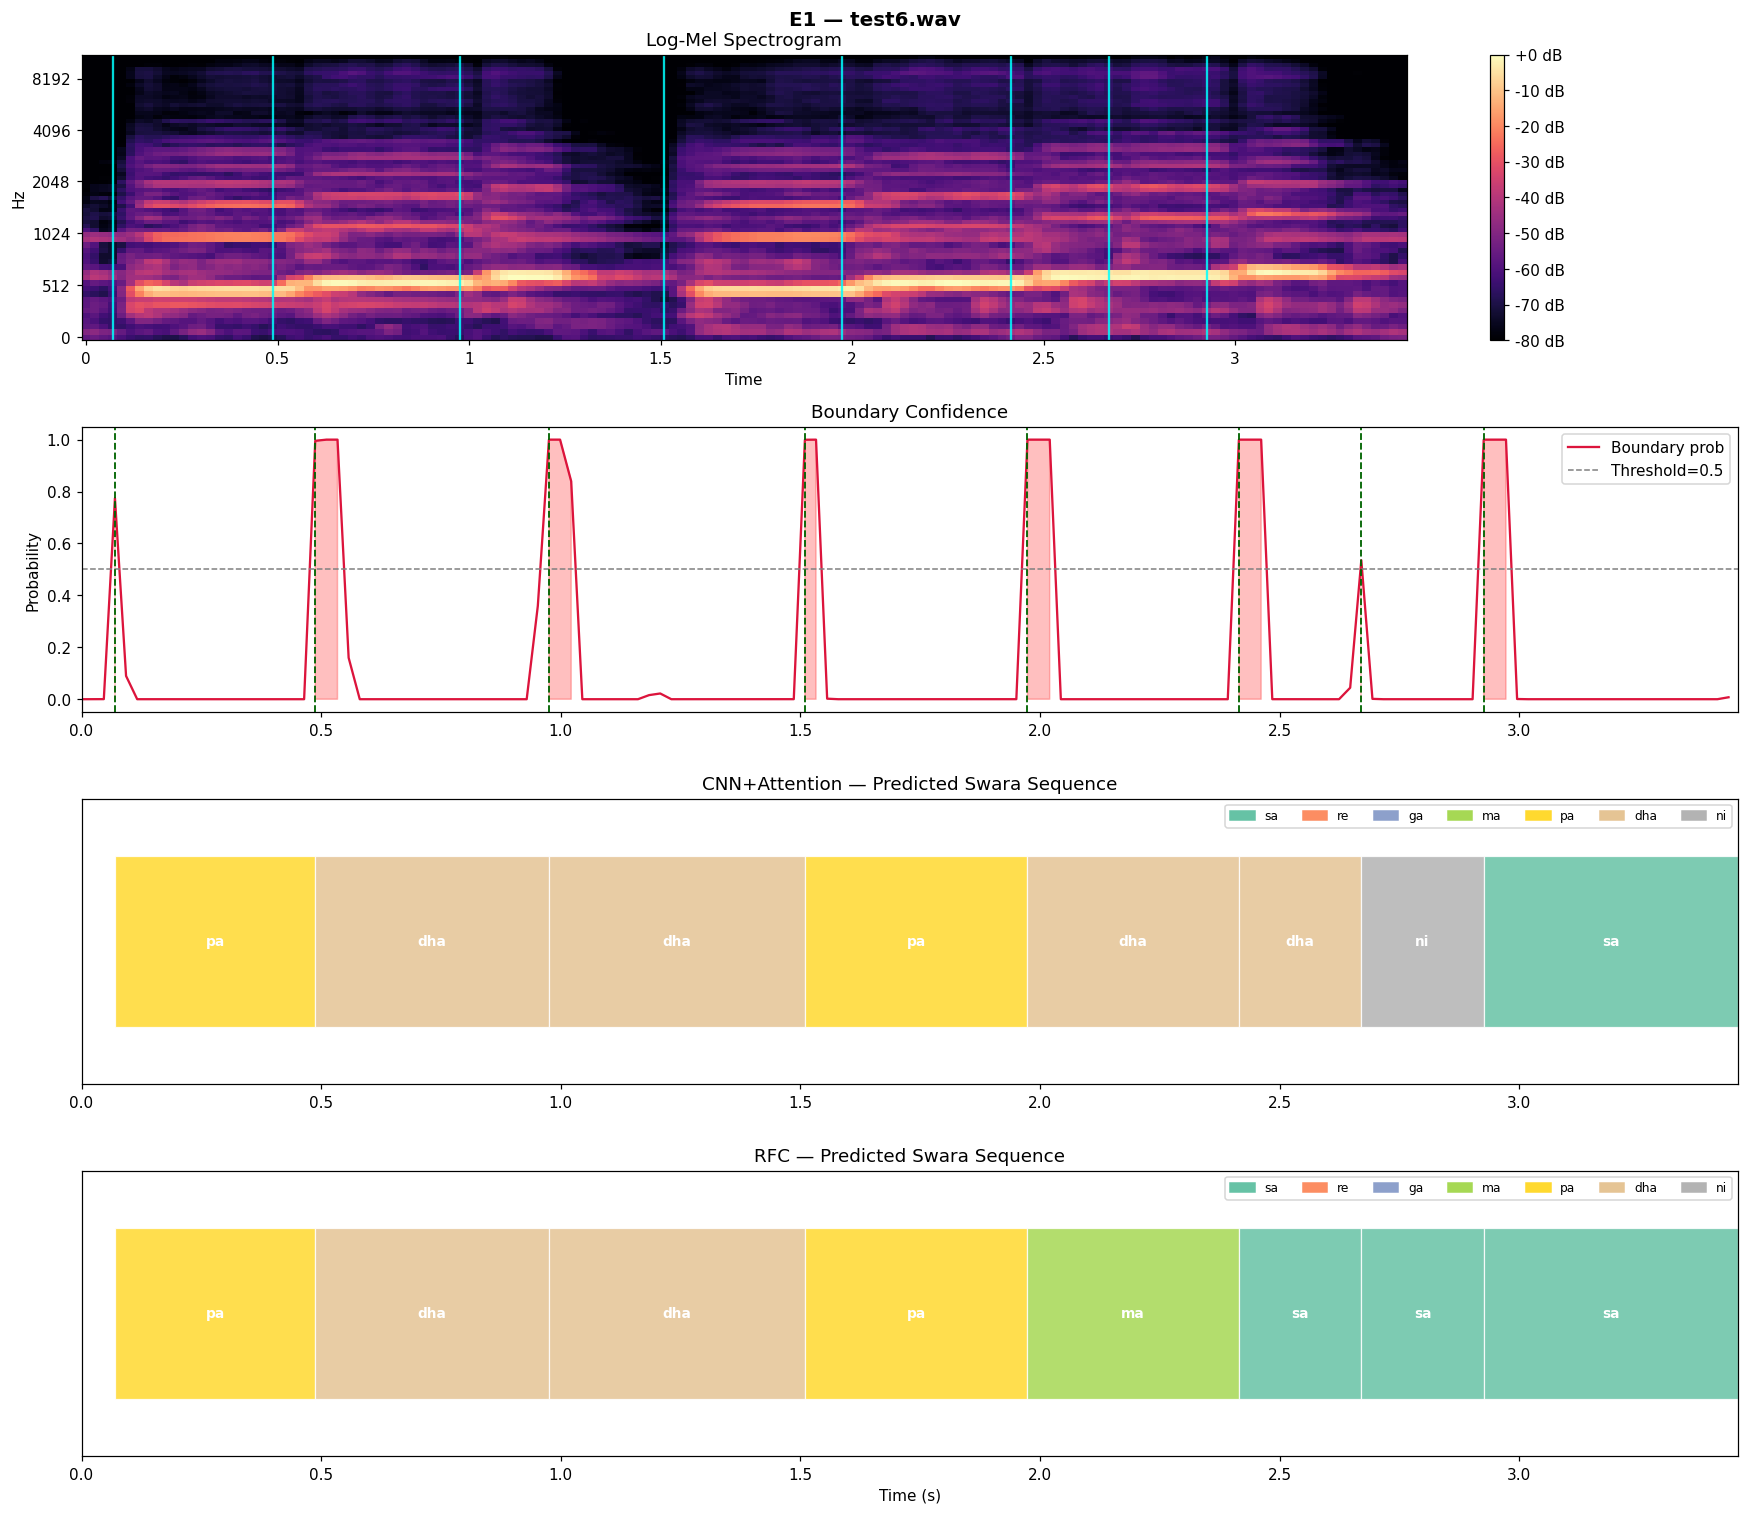

Processing files:  32%|███▏      | 6/19 [00:15<00:31,  2.44s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test7.wav
  [Edge] Dropping last boundary at 3.158s
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  14%|█▍        | 1/7 [00:00<00:00,  9.49it/s]

  Seg 01  [0.000s – 0.488s]  CNN=dha  RFC=dha



Classifying segments:  43%|████▎     | 3/7 [00:00<00:00, 11.81it/s]

  Seg 02  [0.488s – 0.929s]  CNN=ni  RFC=ni
  Seg 03  [0.929s – 1.486s]  CNN=sa  RFC=sa



Classifying segments:  71%|███████▏  | 5/7 [00:00<00:00, 11.07it/s]

  Seg 04  [1.486s – 1.927s]  CNN=dha  RFC=dha
  Seg 05  [1.927s – 2.392s]  CNN=ni  RFC=ni
  Seg 06  [2.392s – 2.902s]  CNN=sa  RFC=sa



Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 10.63it/s]

  Seg 07  [2.902s – 3.400s]  CNN=ma  RFC=re

CNN+Attention : dha → ni → sa → dha → ni → sa → ma
RFC           : dha → ni → sa → dha → ni → sa → re


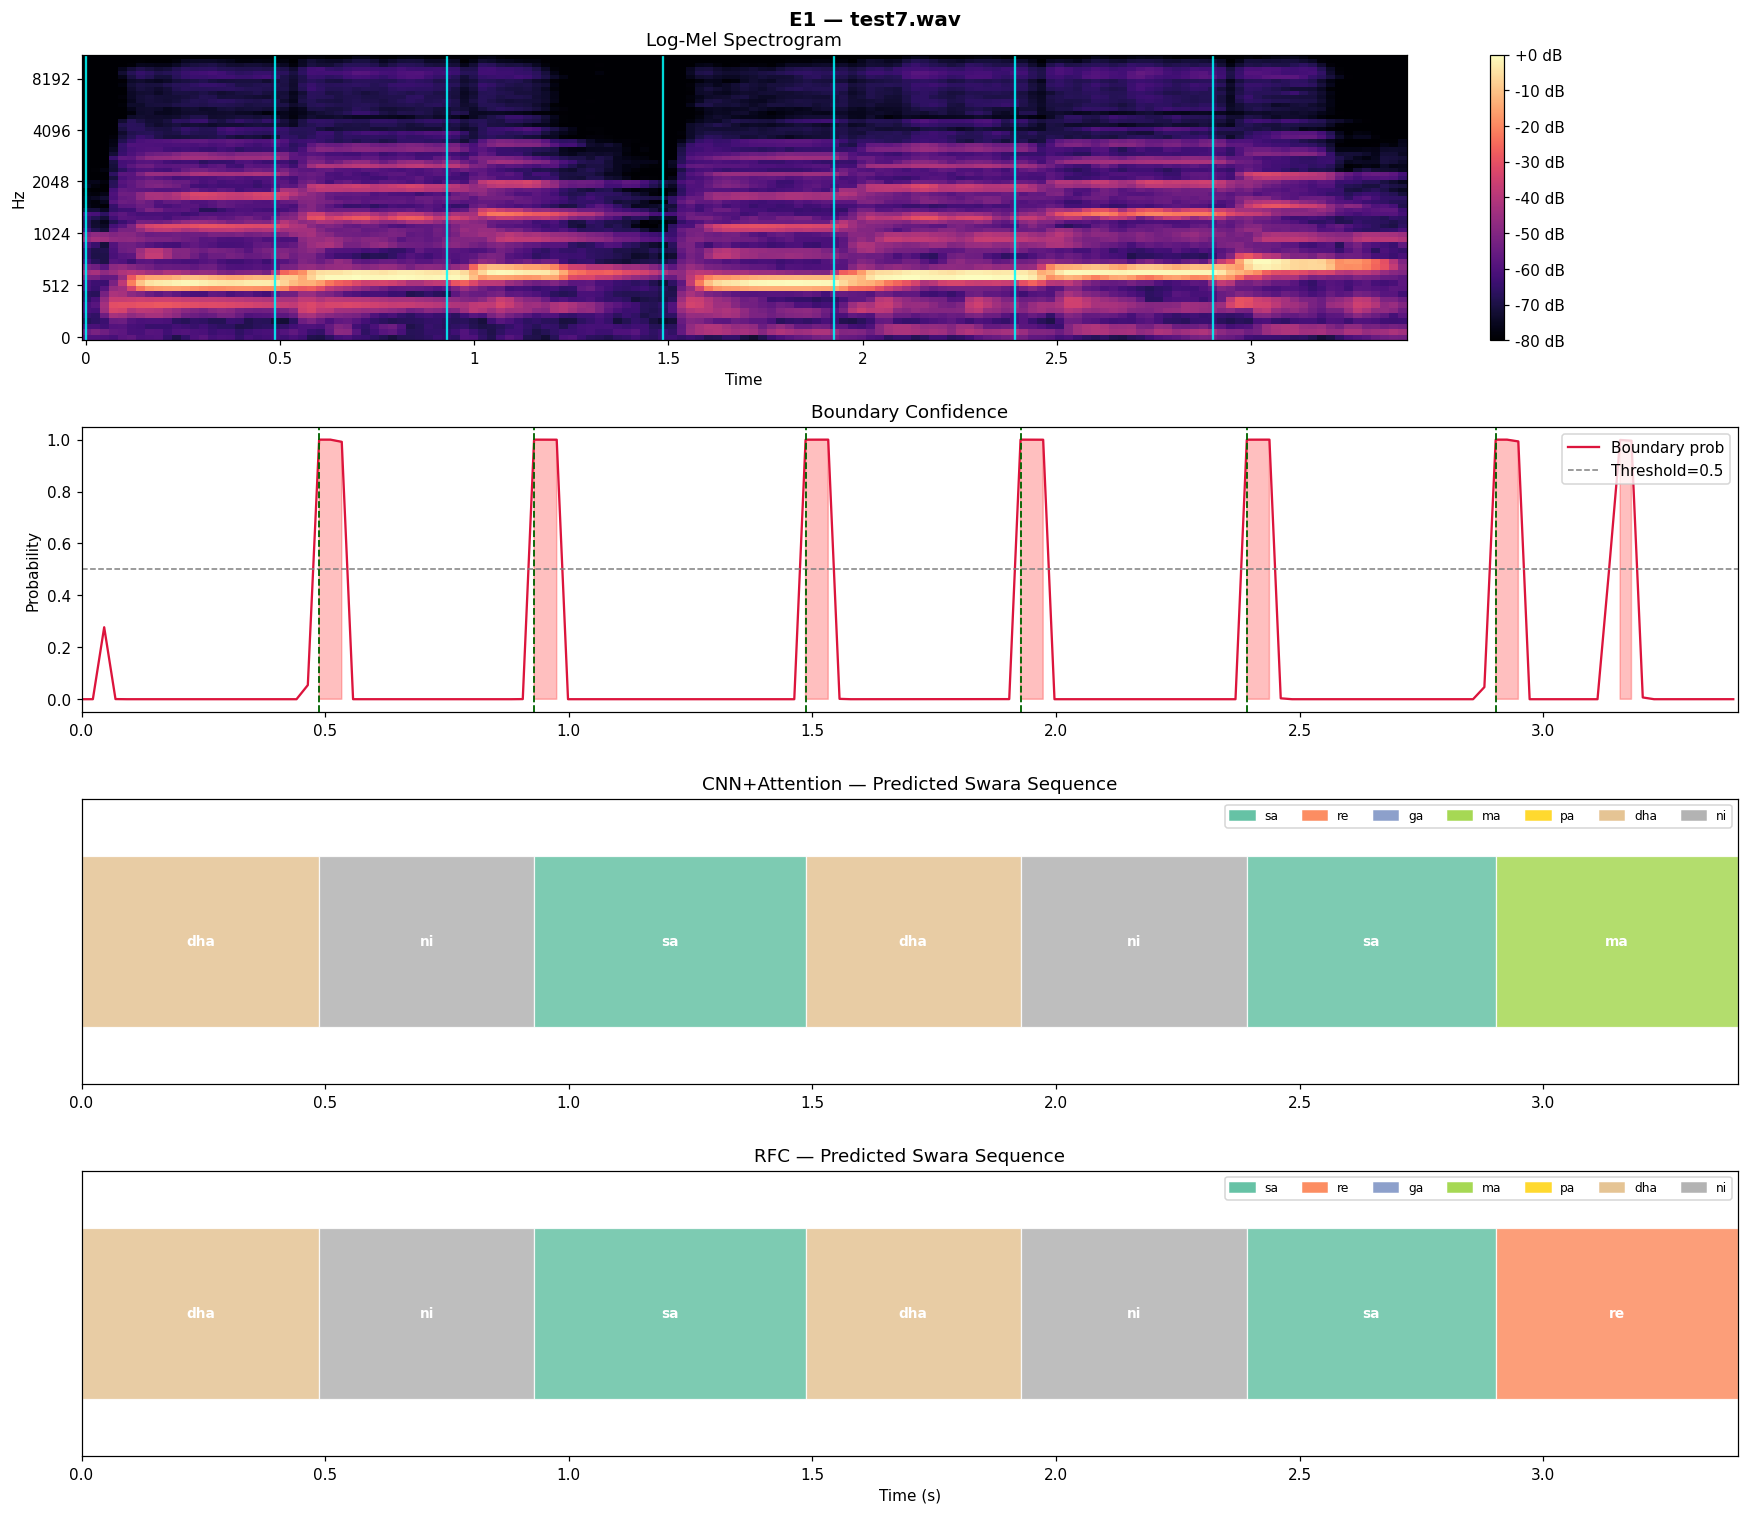

Processing files:  37%|███▋      | 7/19 [00:17<00:28,  2.37s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test8.wav
Boundaries detected: 7
  [Edge] Dropping short segment [0.000–0.093]s
Classifying 7 segments...



Classifying segments:   0%|          | 0/7 [00:00<?, ?it/s]

  Seg 01  [0.093s – 0.488s]  CNN=ni  RFC=sa



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 10.64it/s]

  Seg 02  [0.488s – 0.952s]  CNN=sa  RFC=sa



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00, 10.50it/s]

  Seg 03  [0.952s – 1.509s]  CNN=sa  RFC=re
  Seg 04  [1.509s – 1.927s]  CNN=ni  RFC=ni
  Seg 05  [1.927s – 2.392s]  CNN=sa  RFC=sa



Classifying segments: 100%|██████████| 7/7 [00:00<00:00, 10.39it/s]

  Seg 06  [2.392s – 2.879s]  CNN=ma  RFC=ni
  Seg 07  [2.879s – 3.428s]  CNN=ma  RFC=dha

CNN+Attention : ni → sa → sa → ni → sa → ma → ma
RFC           : sa → sa → re → ni → sa → ni → dha


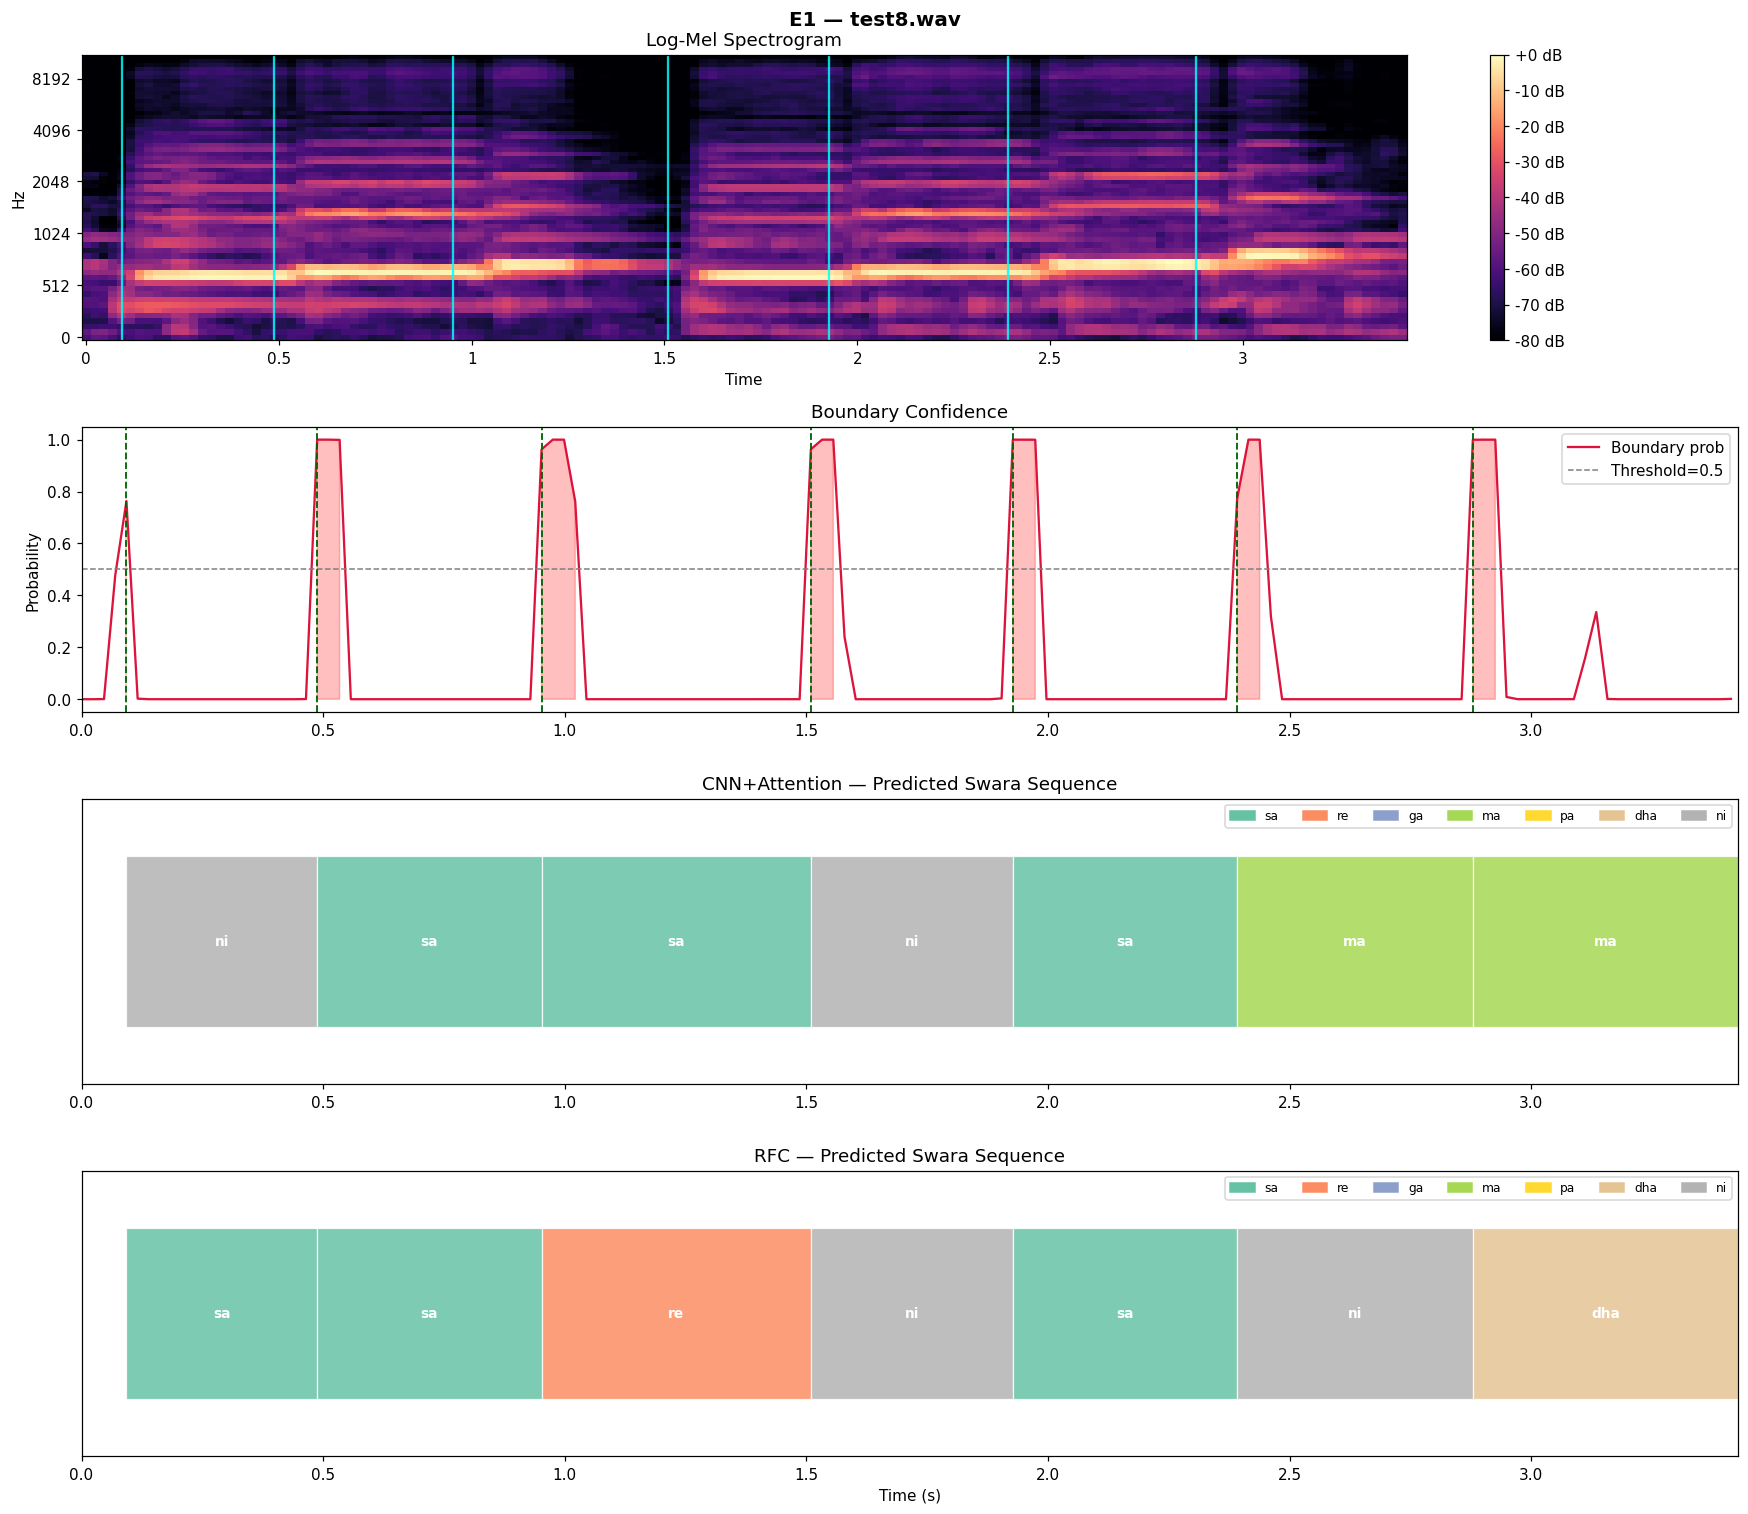

Processing files:  42%|████▏     | 8/19 [00:19<00:25,  2.31s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test9.wav
  [Edge] Dropping last boundary at 3.158s
Boundaries detected: 6
  [Edge] Dropping short segment [0.000–0.093]s
Classifying 6 segments...



Classifying segments:  17%|█▋        | 1/6 [00:00<00:00,  6.37it/s]

  Seg 01  [0.093s – 0.511s]  CNN=ga  RFC=dha



Classifying segments:  50%|█████     | 3/6 [00:00<00:00,  9.82it/s]

  Seg 02  [0.511s – 0.975s]  CNN=dha  RFC=ni
  Seg 03  [0.975s – 1.533s]  CNN=sa  RFC=sa



Classifying segments:  67%|██████▋   | 4/6 [00:00<00:00,  9.80it/s]

  Seg 04  [1.533s – 1.950s]  CNN=ga  RFC=ni
  Seg 05  [1.950s – 2.415s]  CNN=sa  RFC=ni



Classifying segments: 100%|██████████| 6/6 [00:00<00:00,  8.85it/s]

  Seg 06  [2.415s – 3.386s]  CNN=sa  RFC=sa

CNN+Attention : ga → dha → sa → ga → sa → sa
RFC           : dha → ni → sa → ni → ni → sa


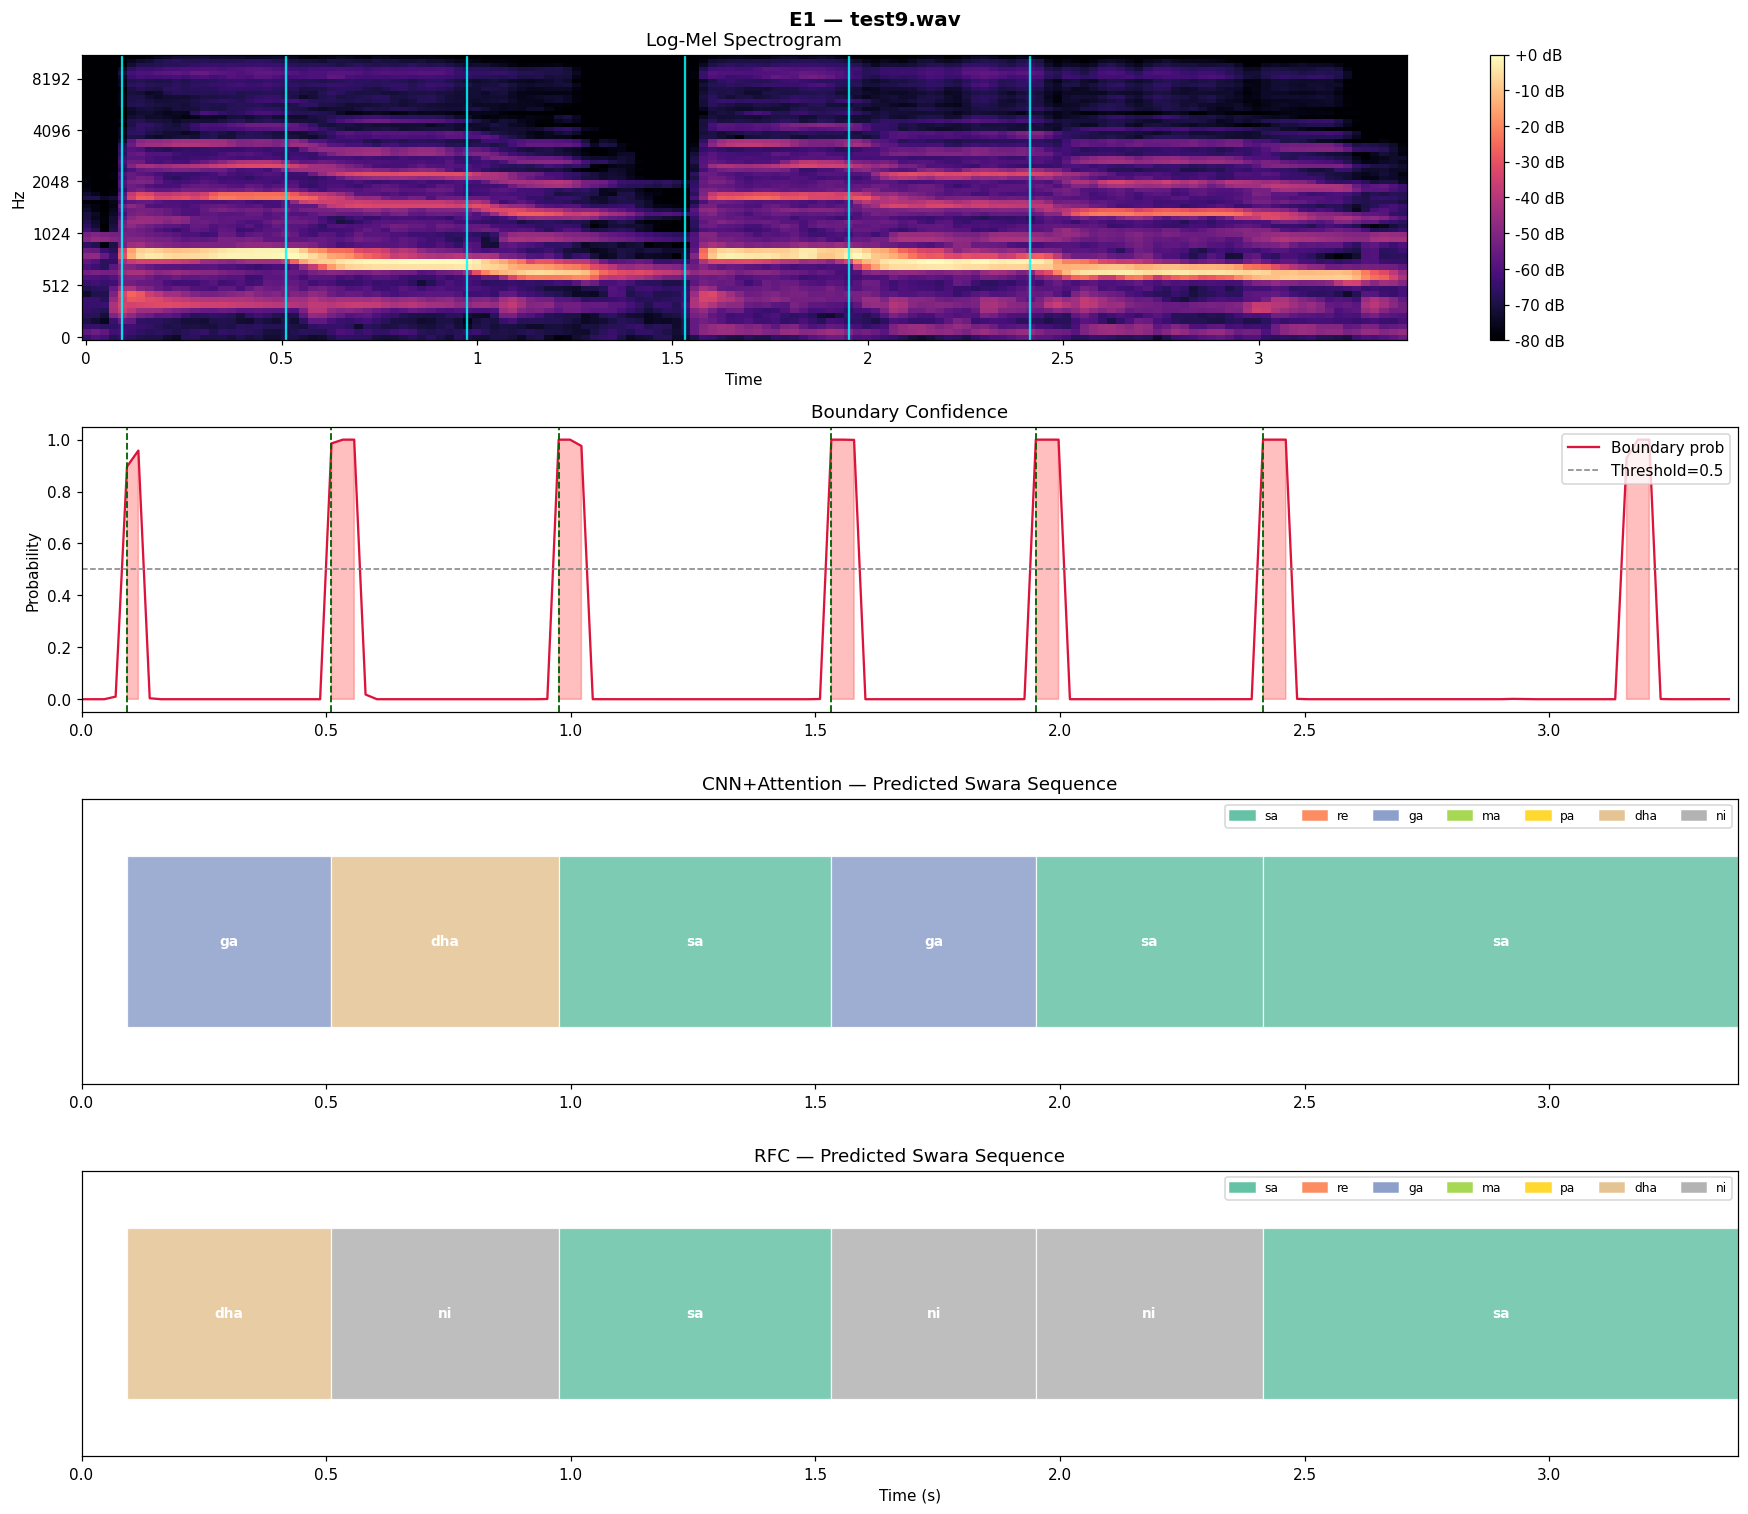

Processing files:  47%|████▋     | 9/19 [00:22<00:25,  2.53s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test10.wav
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  14%|█▍        | 1/7 [00:00<00:00,  8.31it/s]

  Seg 01  [0.000s – 0.534s]  CNN=re  RFC=re



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00,  7.94it/s]

  Seg 02  [0.534s – 1.022s]  CNN=sa  RFC=sa


... (6 outputs left out)


Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00,  6.48it/s]

  Seg 06  [2.461s – 2.949s]  CNN=ni  RFC=ni



Classifying segments: 100%|██████████| 7/7 [00:01<00:00,  7.00it/s]

  Seg 07  [2.949s – 3.489s]  CNN=dha  RFC=dha

CNN+Attention : re → sa → dha → ma → sa → ni → dha
RFC           : re → sa → sa → re → sa → ni → dha


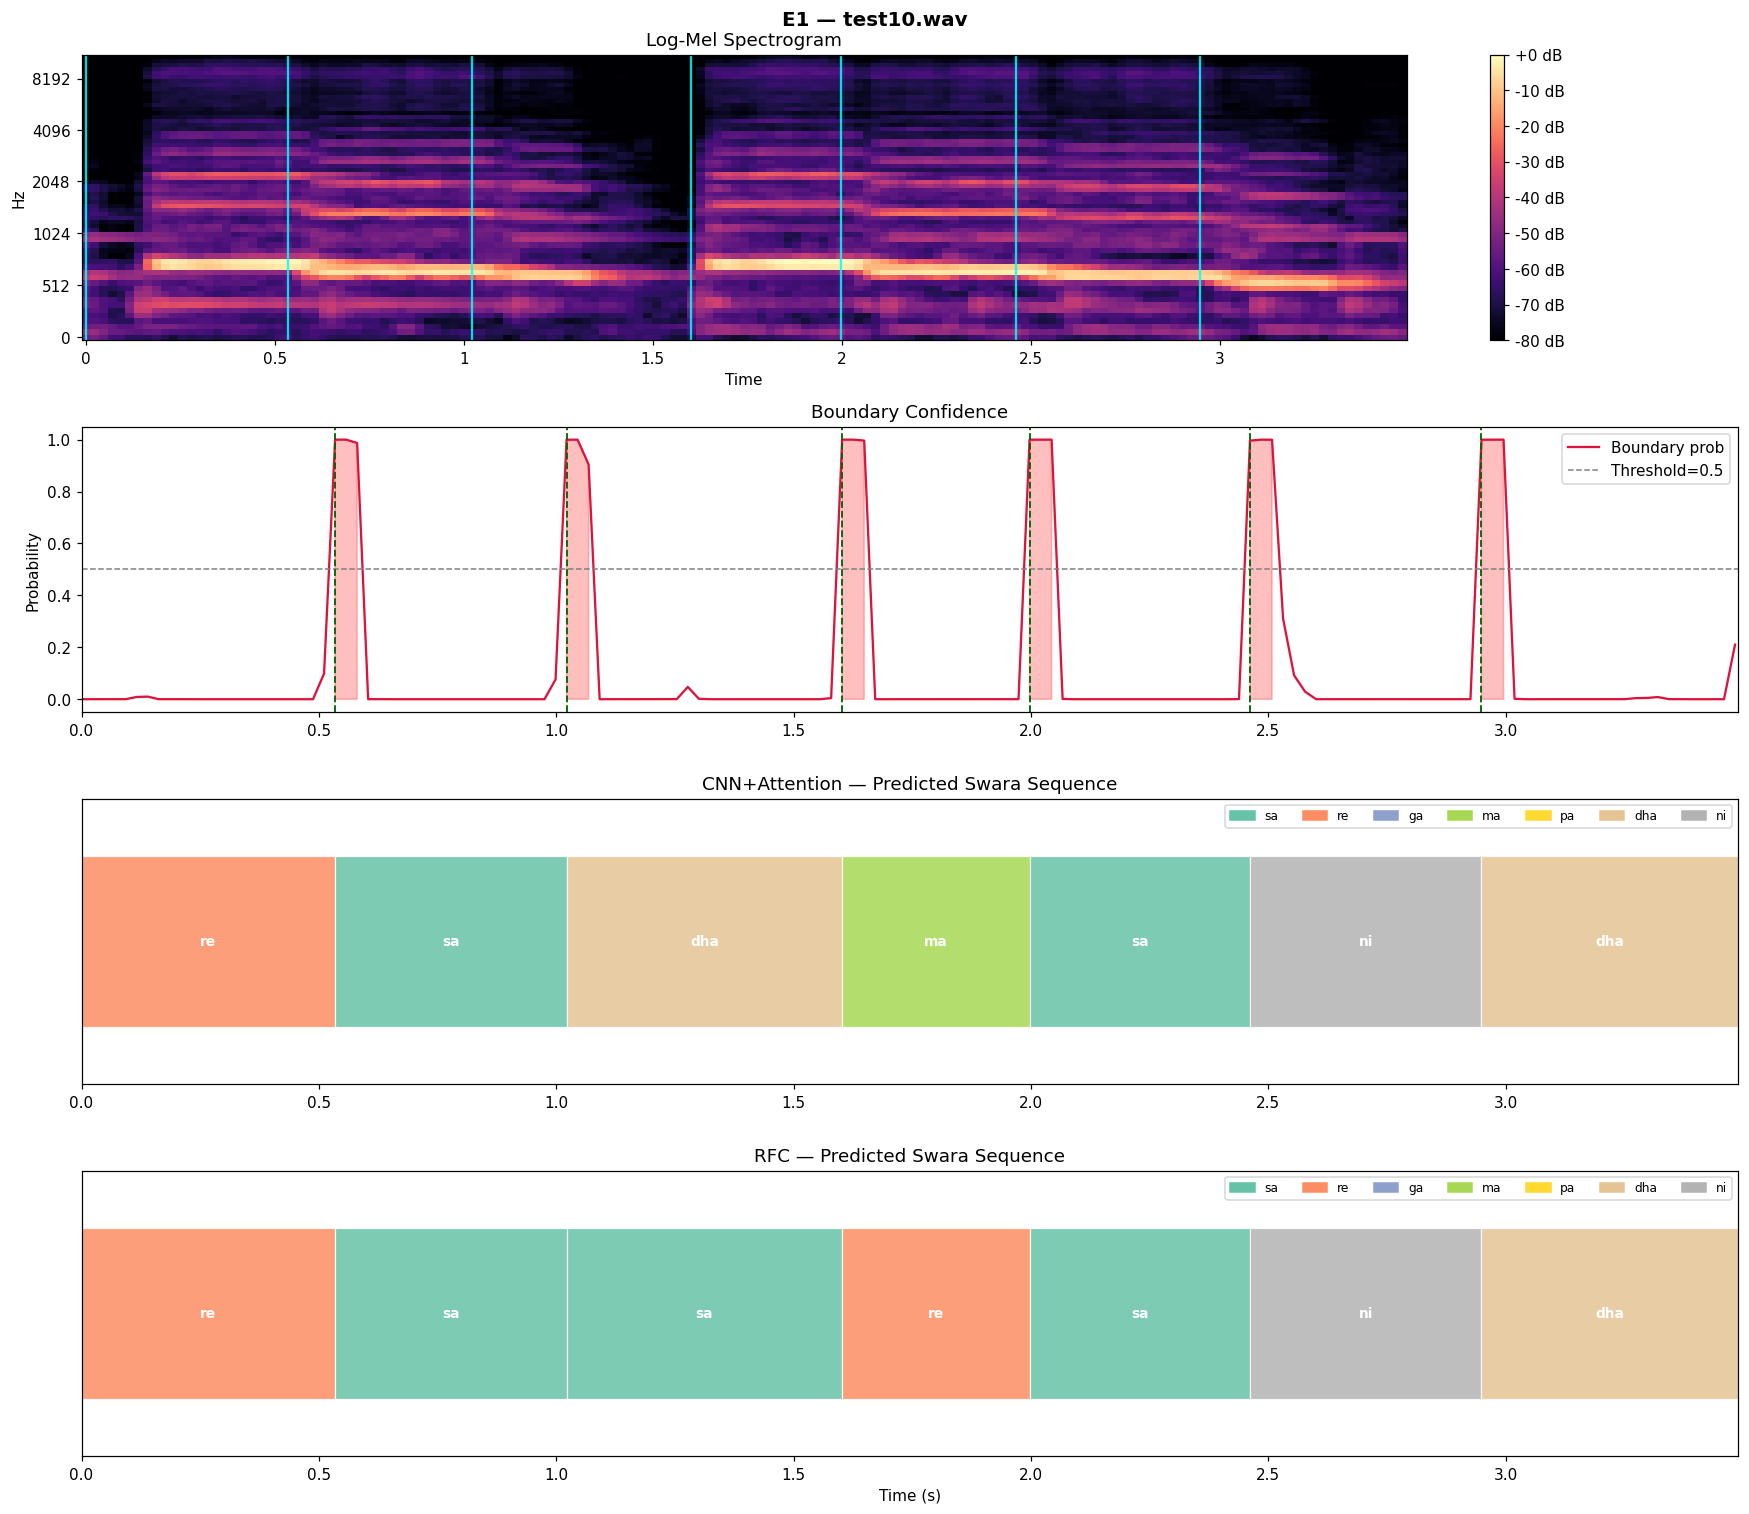

Processing files:  53%|█████▎    | 10/19 [00:26<00:25,  2.89s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test11.wav
Boundaries detected: 5
Classifying 6 segments...



Classifying segments:  17%|█▋        | 1/6 [00:00<00:00,  9.20it/s]

  Seg 01  [0.000s – 0.488s]  CNN=sa  RFC=sa



Classifying segments:  33%|███▎      | 2/6 [00:00<00:00,  8.11it/s]

  Seg 02  [0.488s – 1.022s]  CNN=ni  RFC=ni


... (4 outputs left out)


Classifying segments:  83%|████████▎ | 5/6 [00:00<00:00,  7.82it/s]

  Seg 05  [2.438s – 2.926s]  CNN=dha  RFC=dha



Classifying segments: 100%|██████████| 6/6 [00:00<00:00,  7.91it/s]

  Seg 06  [2.926s – 3.404s]  CNN=re  RFC=pa

CNN+Attention : sa → ni → dha → sa → dha → re
RFC           : sa → ni → dha → sa → dha → pa


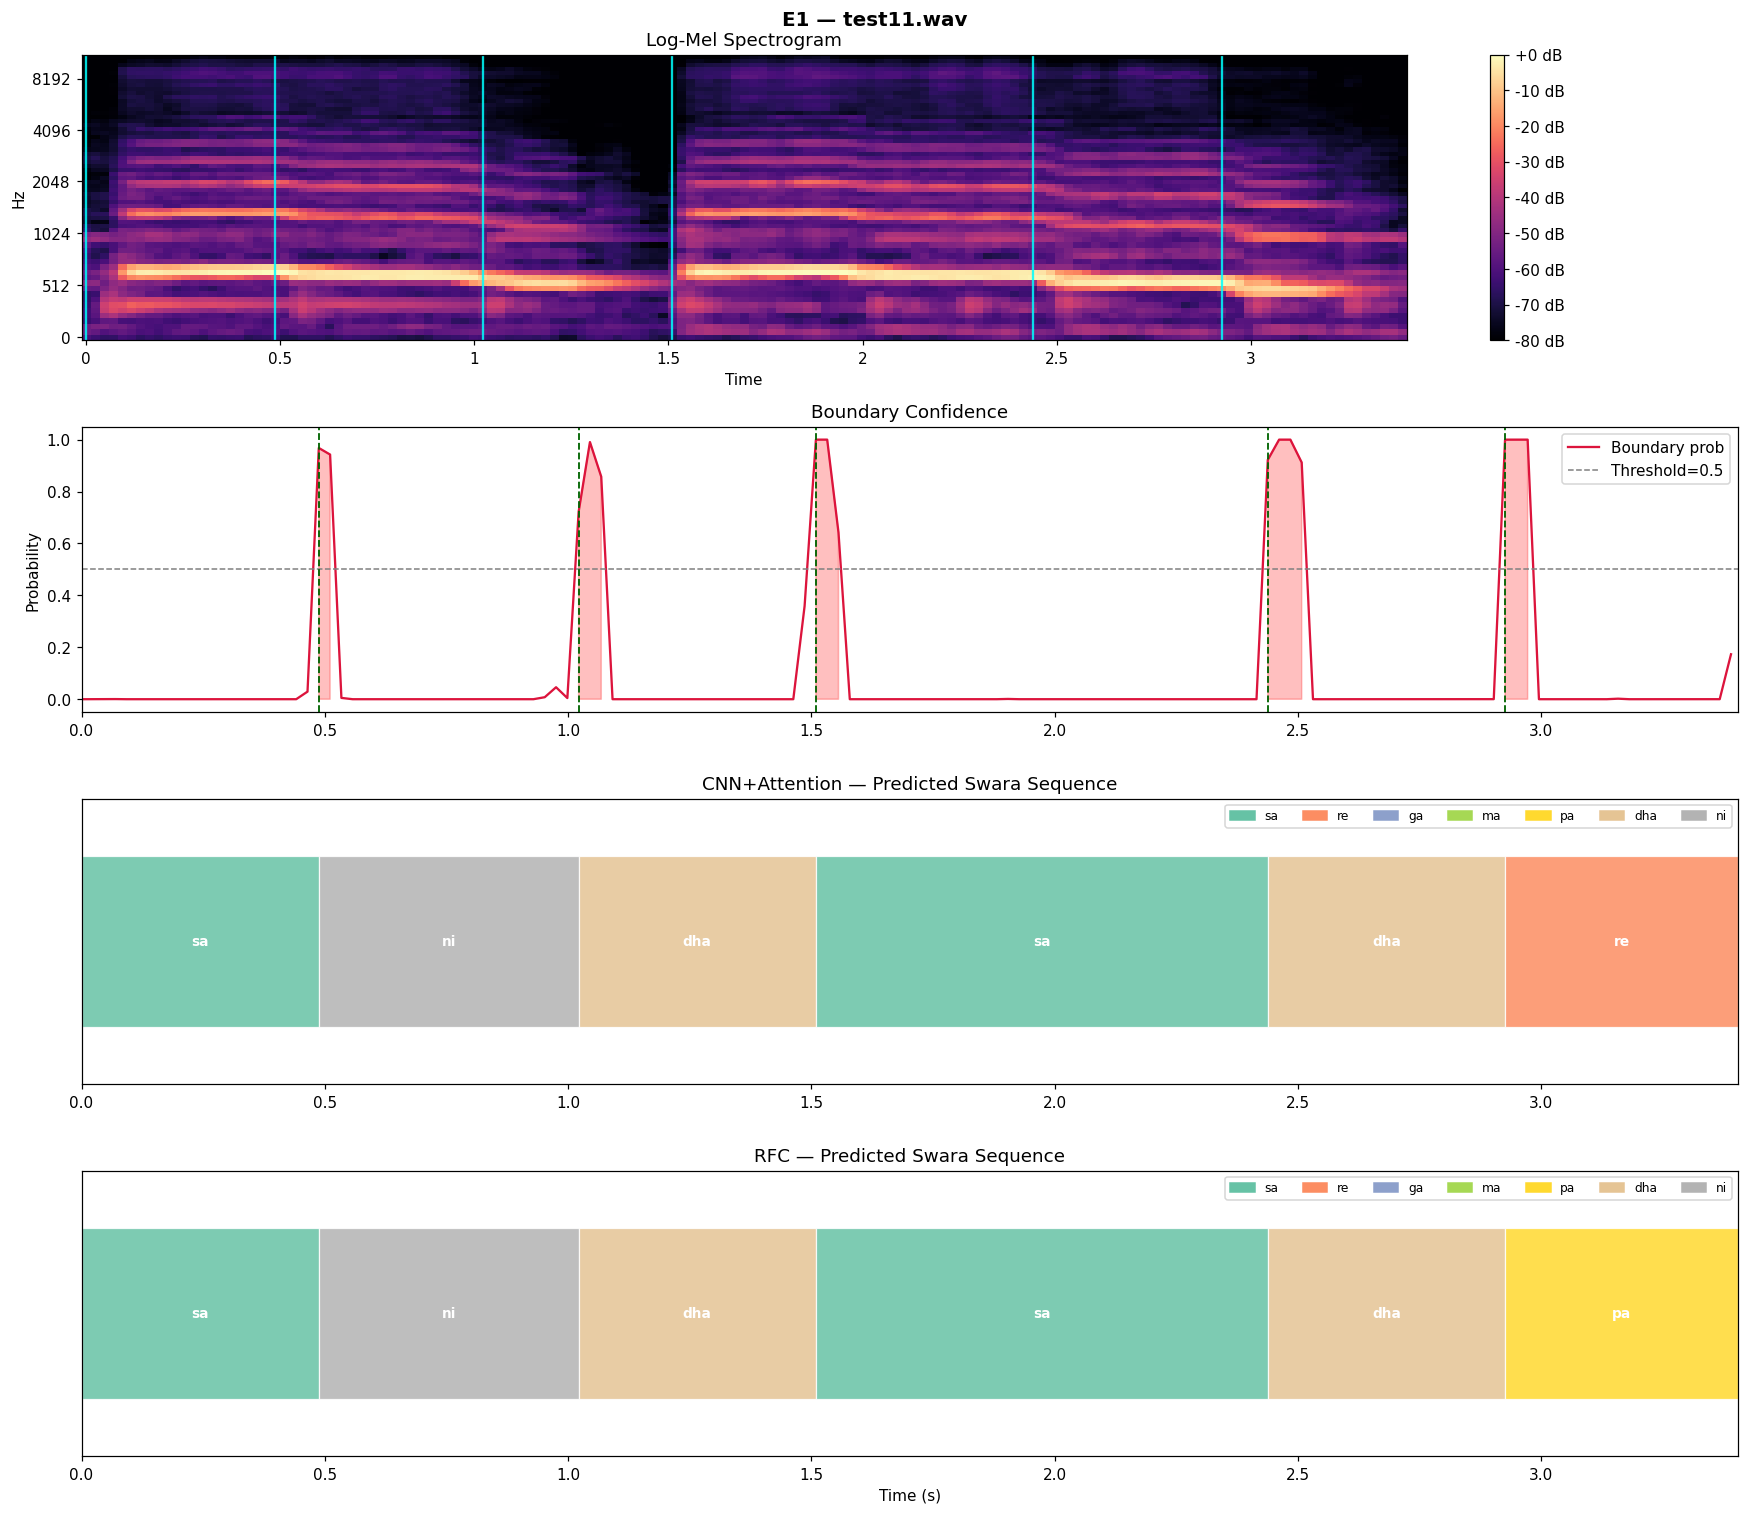

Processing files:  58%|█████▊    | 11/19 [00:28<00:21,  2.75s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test12.wav
  [Edge] Dropping last boundary at 3.204s
Boundaries detected: 8
  [Edge] Dropping short segment [0.000–0.070]s
  [Edge] Dropping short segment [1.974–2.136]s
Classifying 7 segments...



Classifying segments:  14%|█▍        | 1/7 [00:00<00:00,  8.58it/s]

  Seg 01  [0.070s – 0.511s]  CNN=ni  RFC=sa



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00,  7.25it/s]

  Seg 02  [0.511s – 0.975s]  CNN=dha  RFC=dha


... (4 outputs left out)


Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00,  8.60it/s]

  Seg 06  [2.461s – 2.902s]  CNN=pa  RFC=pa



Classifying segments: 100%|██████████| 7/7 [00:00<00:00,  8.34it/s]

  Seg 07  [2.902s – 3.348s]  CNN=ma  RFC=ma

CNN+Attention : ni → dha → pa → ni → dha → pa → ma
RFC           : sa → dha → pa → ni → dha → pa → ma


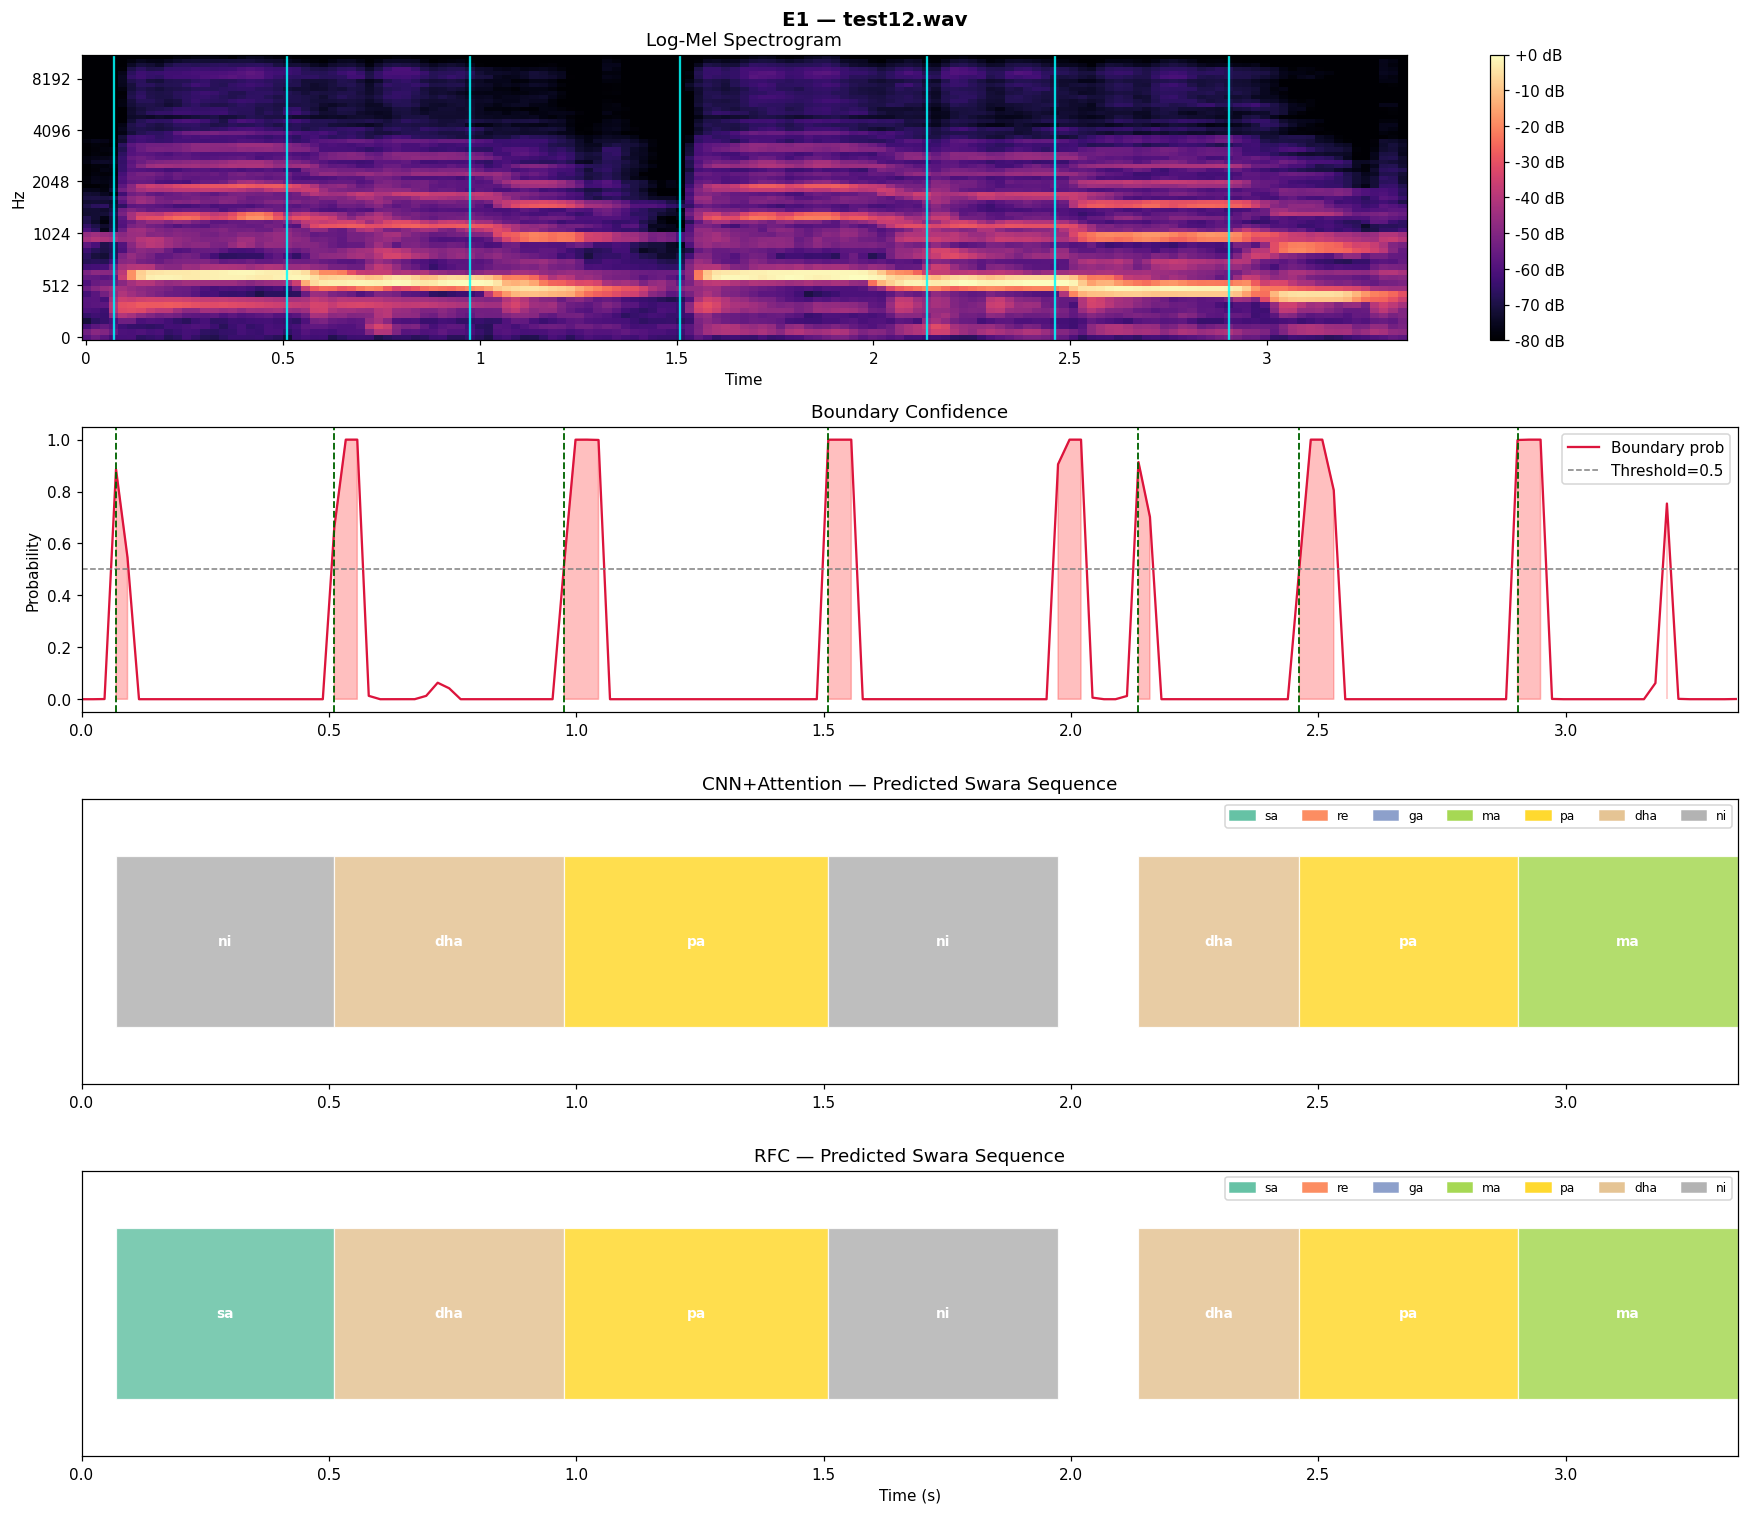

Processing files:  63%|██████▎   | 12/19 [00:31<00:18,  2.68s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test13.wav
  [Edge] Dropping last boundary at 3.204s
Boundaries detected: 8
  [Edge] Dropping short segment [0.000–0.093]s
  [Edge] Dropping short segment [1.997–2.183]s
Classifying 7 segments...



Classifying segments:  14%|█▍        | 1/7 [00:00<00:00,  6.76it/s]

  Seg 01  [0.093s – 0.534s]  CNN=dha  RFC=dha



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00,  7.72it/s]

  Seg 02  [0.534s – 0.975s]  CNN=pa  RFC=pa


... (4 outputs left out)


Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00,  8.62it/s]

  Seg 06  [2.485s – 2.972s]  CNN=ma  RFC=ma



Classifying segments: 100%|██████████| 7/7 [00:00<00:00,  8.11it/s]

  Seg 07  [2.972s – 3.414s]  CNN=ga  RFC=ma

CNN+Attention : dha → pa → ma → dha → ga → ma → ga
RFC           : dha → pa → ma → dha → pa → ma → ma


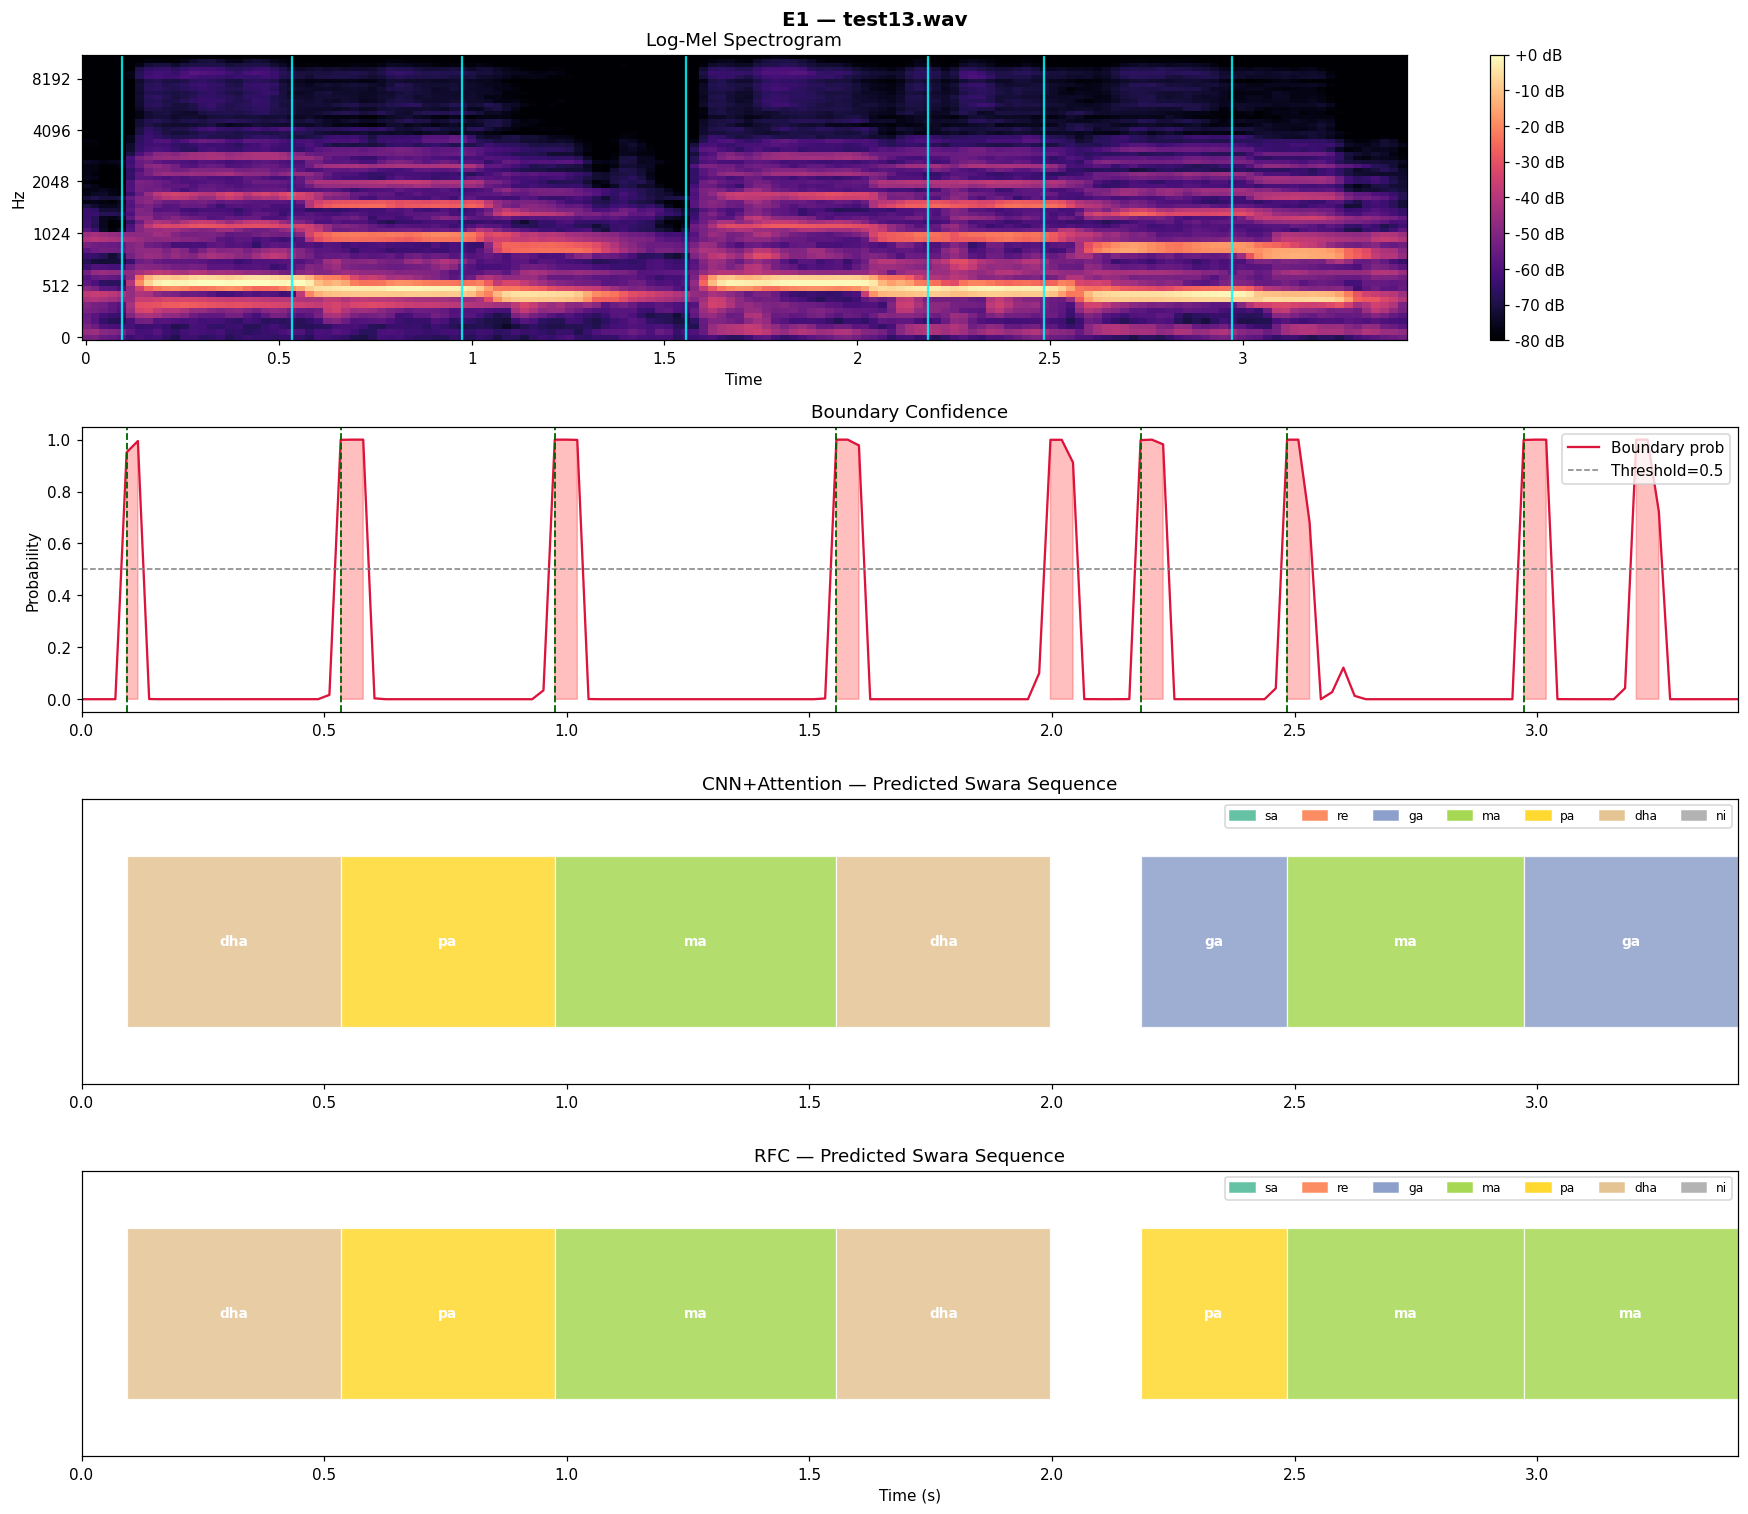

Processing files:  68%|██████▊   | 13/19 [00:33<00:15,  2.63s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test14.wav
  [Edge] Dropping last boundary at 3.228s
Boundaries detected: 7
  [Edge] Dropping short segment [0.000–0.070]s
Classifying 7 segments...



Classifying segments:  14%|█▍        | 1/7 [00:00<00:00,  7.61it/s]

  Seg 01  [0.070s – 0.488s]  CNN=pa  RFC=pa



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00,  7.85it/s]

  Seg 02  [0.488s – 0.975s]  CNN=ma  RFC=ma


... (6 outputs left out)


Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00,  7.78it/s]

  Seg 06  [2.461s – 2.926s]  CNN=ga  RFC=ma



Classifying segments: 100%|██████████| 7/7 [00:00<00:00,  7.76it/s]

  Seg 07  [2.926s – 3.423s]  CNN=re  RFC=re

CNN+Attention : pa → ma → ma → pa → ma → ga → re
RFC           : pa → ma → ma → pa → ma → ma → re


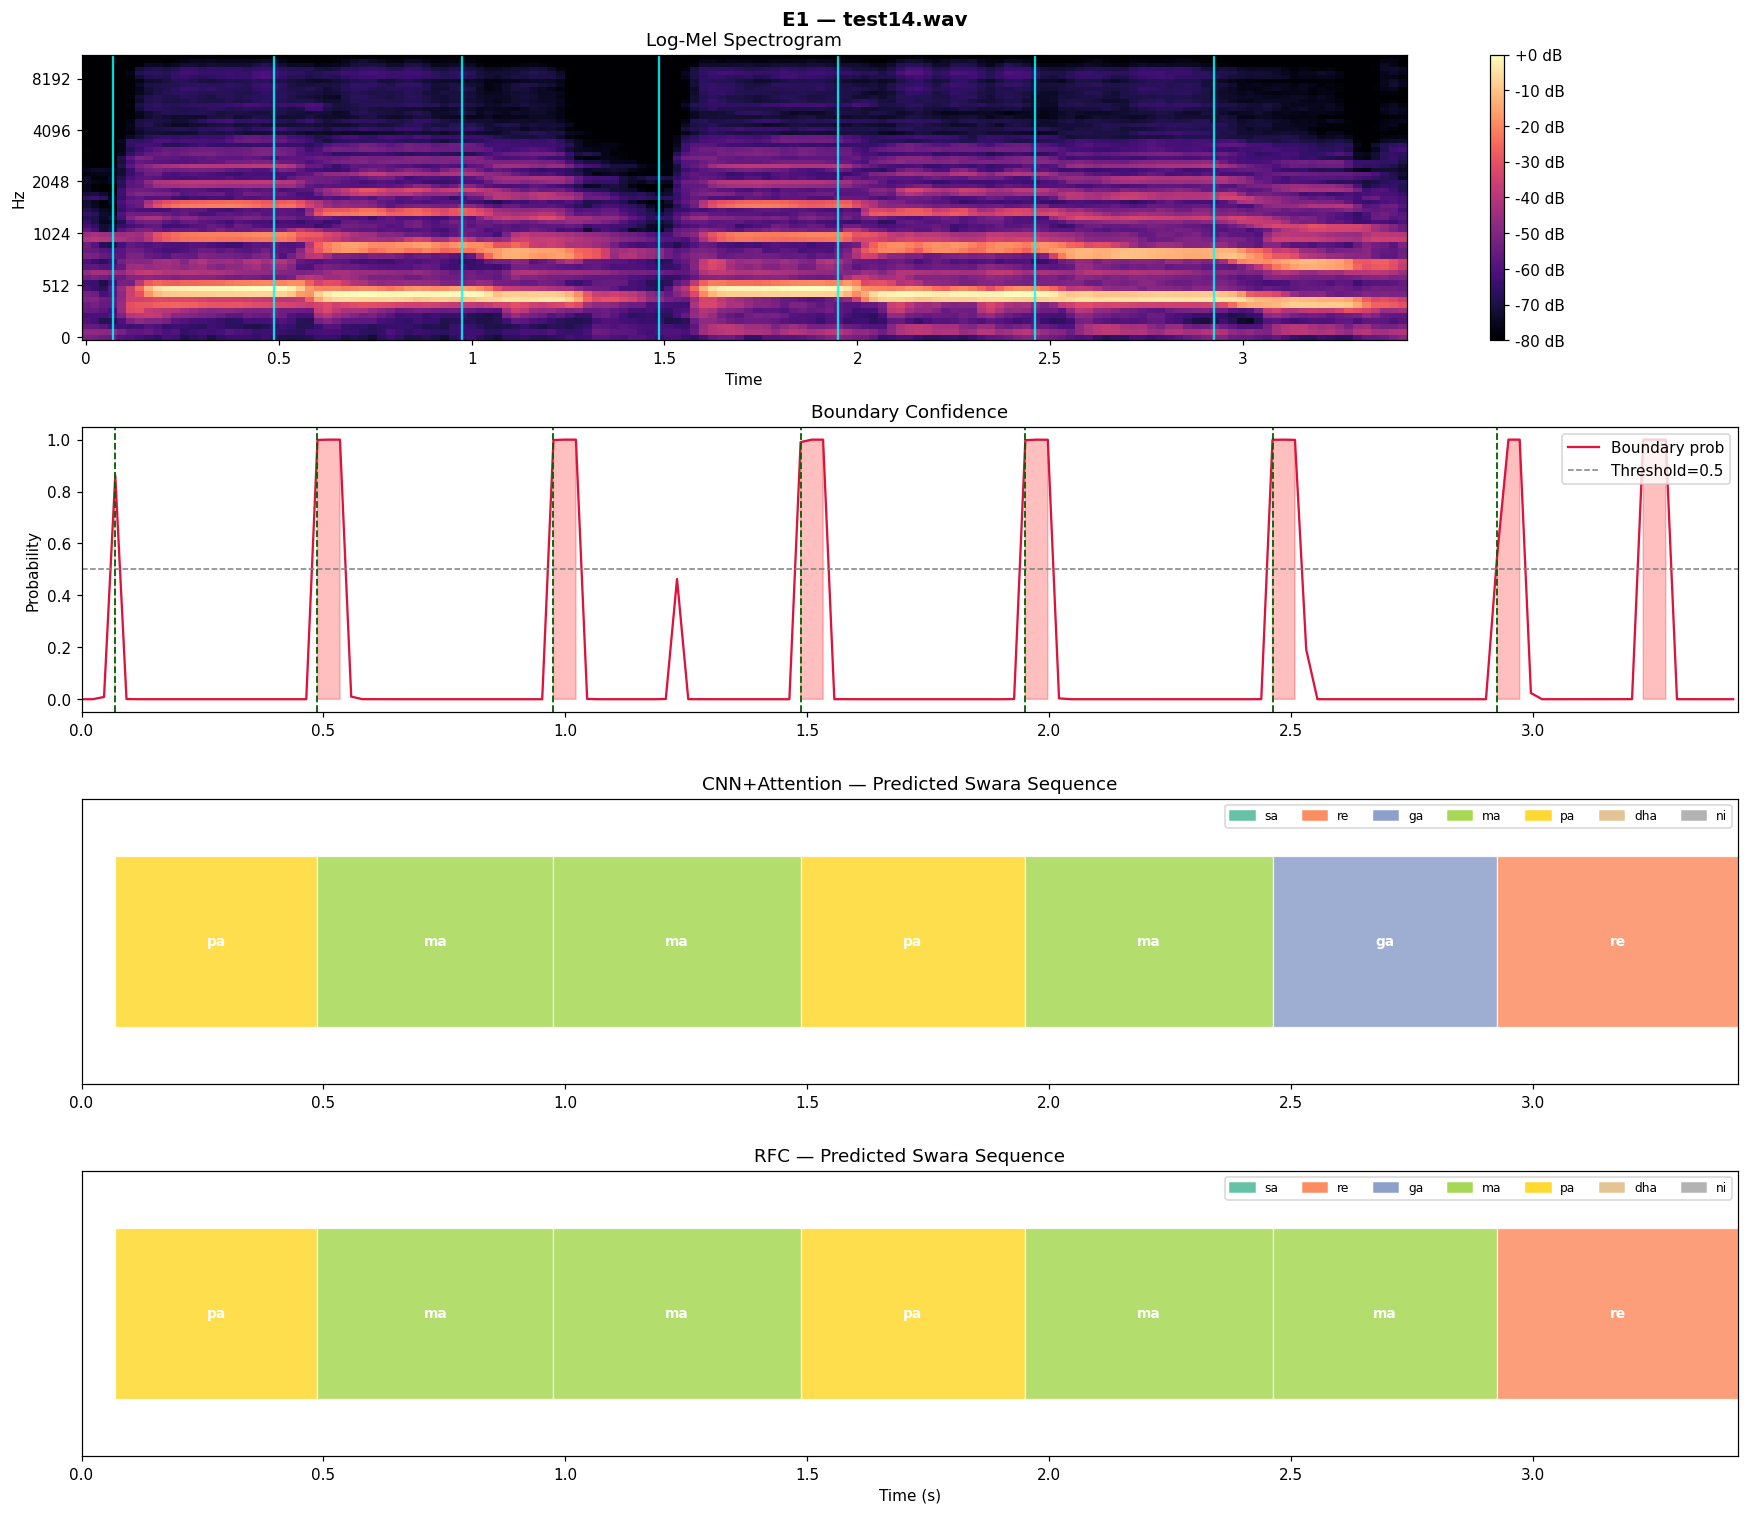

Processing files:  74%|███████▎  | 14/19 [00:36<00:13,  2.74s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test15.wav
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  14%|█▍        | 1/7 [00:00<00:00,  9.80it/s]

  Seg 01  [0.000s – 0.488s]  CNN=ma  RFC=ma



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00,  6.28it/s]

  Seg 02  [0.488s – 0.929s]  CNN=ga  RFC=ma


... (6 outputs left out)


Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00,  6.70it/s]

  Seg 06  [2.438s – 2.949s]  CNN=re  RFC=re



Classifying segments: 100%|██████████| 7/7 [00:00<00:00,  7.09it/s]

  Seg 07  [2.949s – 3.414s]  CNN=sa  RFC=sa

CNN+Attention : ma → ga → re → ma → ga → re → sa
RFC           : ma → ma → re → ma → ga → re → sa


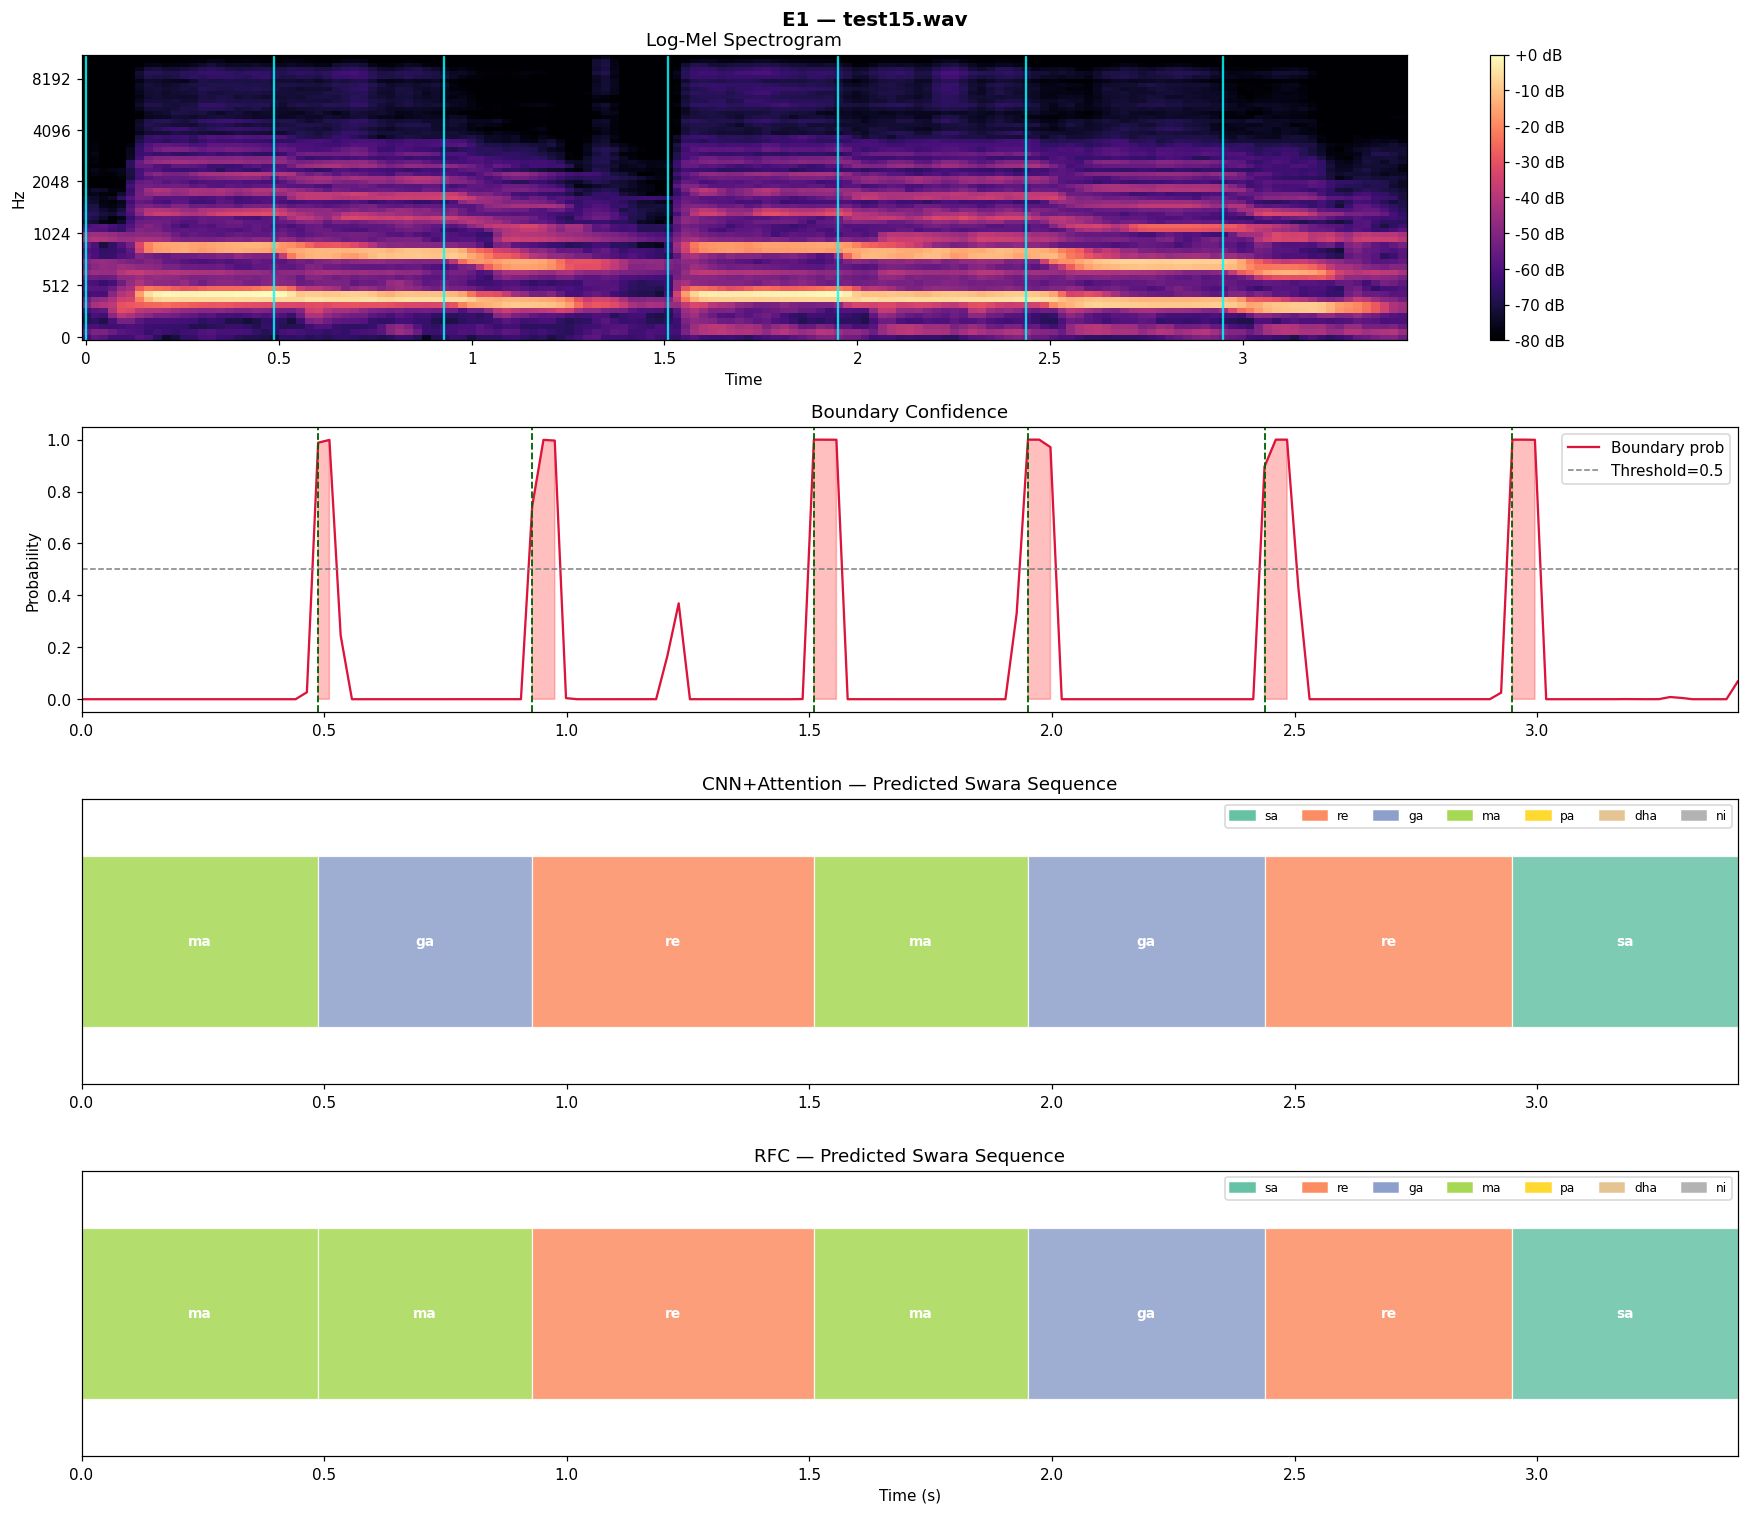

Processing files:  79%|███████▉  | 15/19 [00:40<00:12,  3.01s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test16.wav
  [Edge] Dropping last boundary at 3.111s
Boundaries detected: 8
  [Edge] Dropping short segment [0.000–0.070]s
Classifying 8 segments...



Classifying segments:   0%|          | 0/8 [00:00<?, ?it/s]

  Seg 01  [0.070s – 0.488s]  CNN=sa  RFC=sa



Classifying segments:  25%|██▌       | 2/8 [00:00<00:00,  7.99it/s]

  Seg 02  [0.488s – 0.975s]  CNN=re  RFC=re


... (4 outputs left out)


Classifying segments:  75%|███████▌  | 6/8 [00:00<00:00,  6.64it/s]

  Seg 05  [1.486s – 1.950s]  CNN=sa  RFC=sa
  Seg 06  [1.950s – 2.415s]  CNN=re  RFC=re



Classifying segments: 100%|██████████| 8/8 [00:01<00:00,  6.91it/s]

  Seg 07  [2.415s – 2.926s]  CNN=ga  RFC=ga
  Seg 08  [2.926s – 3.386s]  CNN=ma  RFC=ma

CNN+Attention : sa → re → ni → ga → sa → re → ga → ma
RFC           : sa → re → re → ma → sa → re → ga → ma


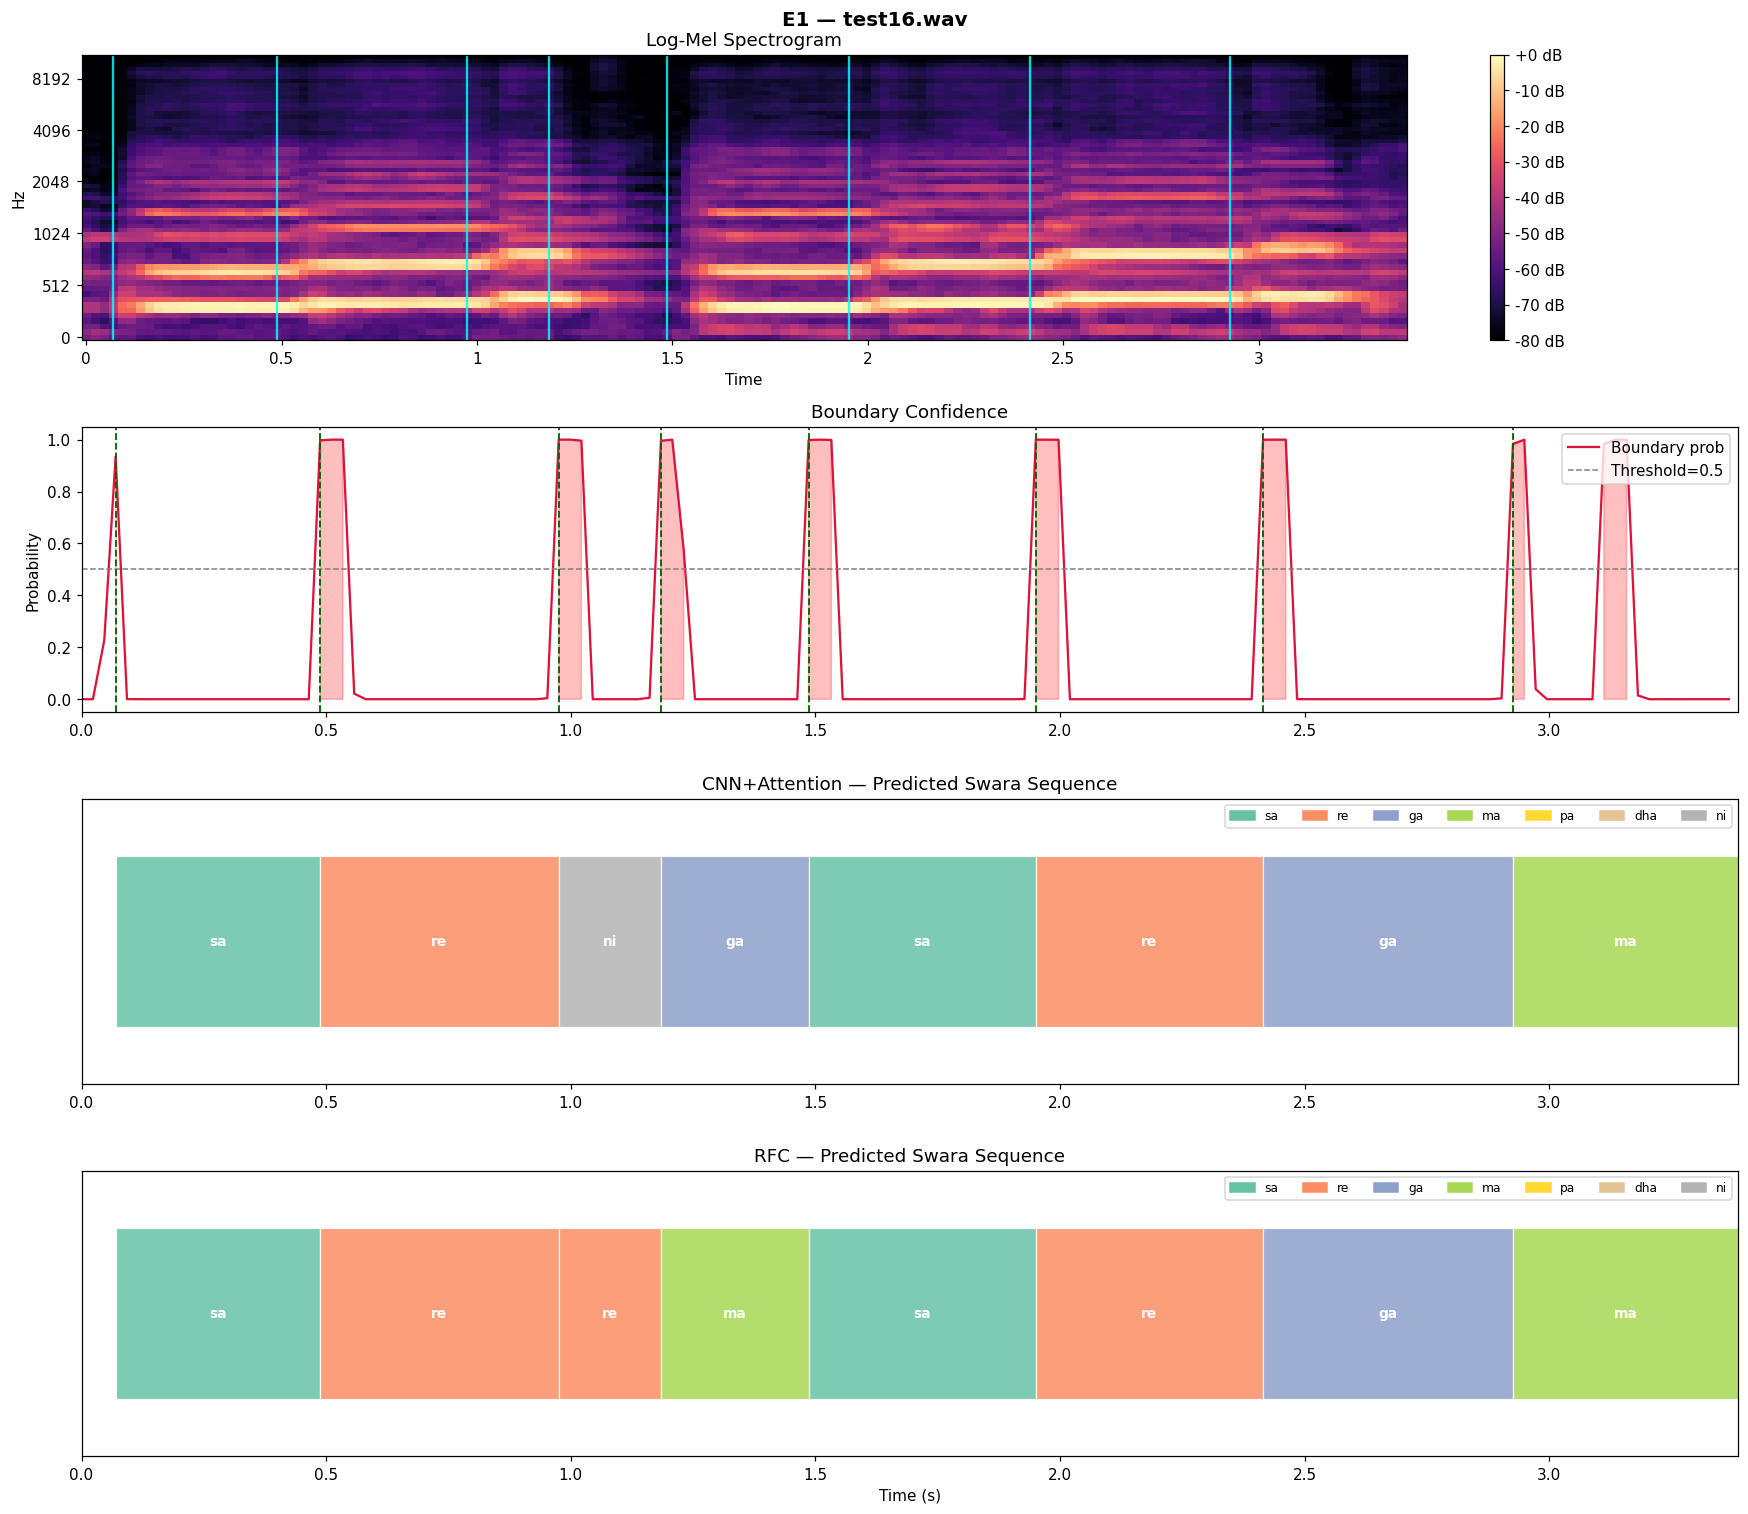

Processing files:  84%|████████▍ | 16/19 [00:43<00:09,  3.15s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test17.wav
  [Edge] Dropping last boundary at 3.228s
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00, 11.89it/s]

  Seg 01  [0.000s – 0.511s]  CNN=re  RFC=re
  Seg 02  [0.511s – 0.998s]  CNN=ga  RFC=re



Classifying segments:  57%|█████▋    | 4/7 [00:00<00:00,  9.78it/s]

  Seg 03  [0.998s – 1.533s]  CNN=ma  RFC=ma
  Seg 04  [1.533s – 1.974s]  CNN=re  RFC=re



Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00,  8.98it/s]

  Seg 05  [1.974s – 2.461s]  CNN=ga  RFC=re
  Seg 06  [2.461s – 2.995s]  CNN=ma  RFC=re



Classifying segments: 100%|██████████| 7/7 [00:00<00:00,  9.04it/s]


  Seg 07  [2.995s – 3.475s]  CNN=re  RFC=pa

CNN+Attention : re → ga → ma → re → ga → ma → re
RFC           : re → re → ma → re → re → re → pa


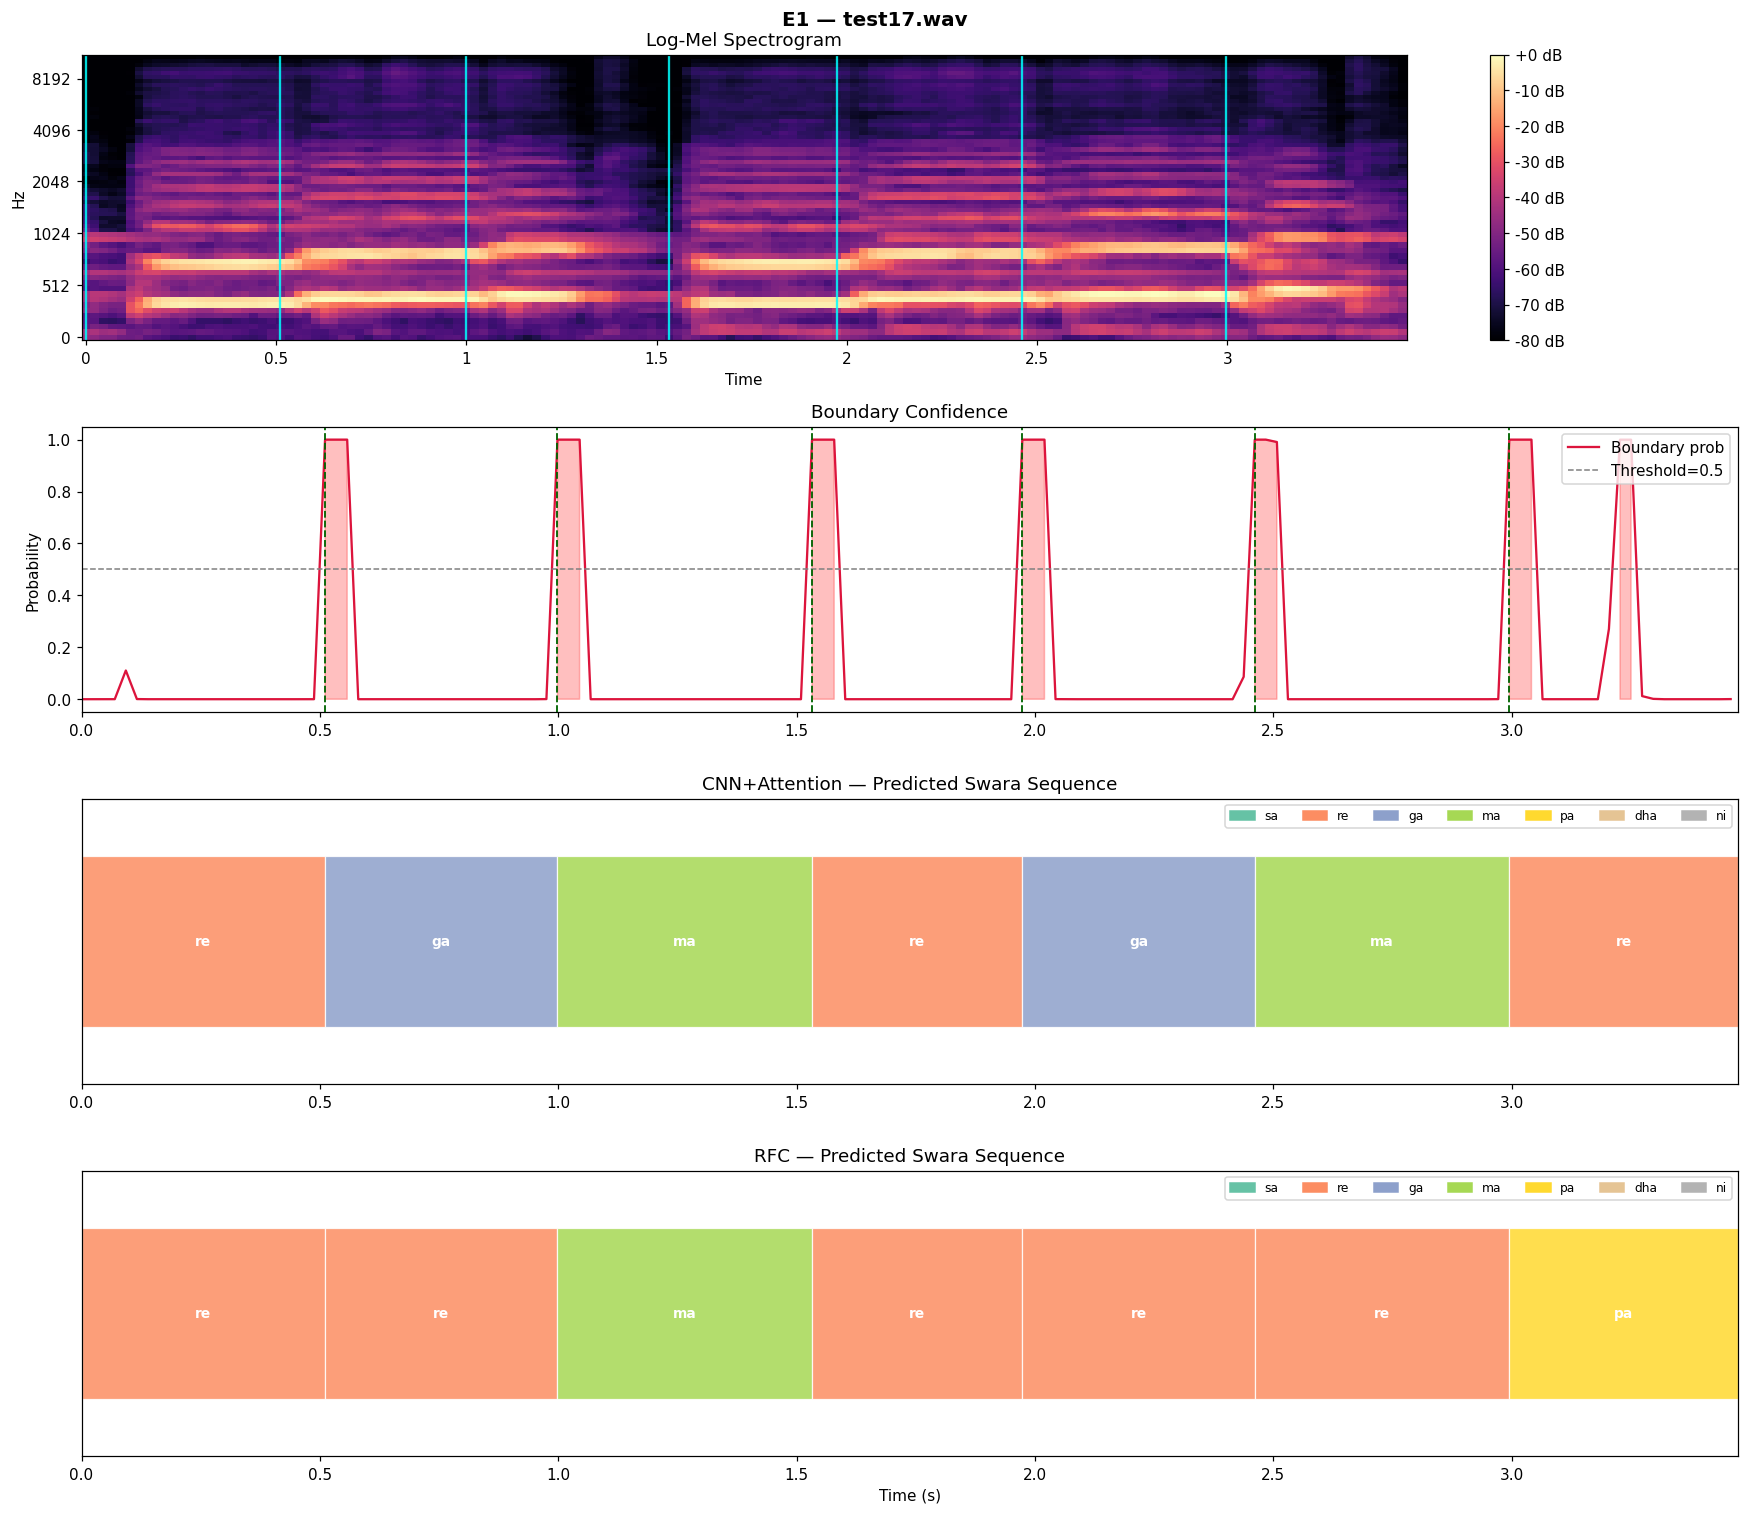

Processing files:  89%|████████▉ | 17/19 [00:46<00:05,  2.96s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test18.wav
  [Edge] Dropping last boundary at 3.181s
Boundaries detected: 7
Classifying 8 segments...



Classifying segments:   0%|          | 0/8 [00:00<?, ?it/s]

  Seg 01  [0.000s – 0.557s]  CNN=ga  RFC=ga



Classifying segments:  25%|██▌       | 2/8 [00:00<00:00,  8.81it/s]

  Seg 02  [0.557s – 1.022s]  CNN=ma  RFC=ma
  Seg 03  [1.022s – 1.533s]  CNN=ni  RFC=pa


... (6 outputs left out)


Classifying segments: 100%|██████████| 8/8 [00:00<00:00,  9.44it/s]

  Seg 08  [2.995s – 3.470s]  CNN=dha  RFC=dha


Classifying segments: 100%|██████████| 8/8 [00:00<00:00,  9.21it/s]



CNN+Attention : ga → ma → ni → ga → ma → dha → ga → dha
RFC           : ga → ma → pa → ga → re → ma → ga → dha


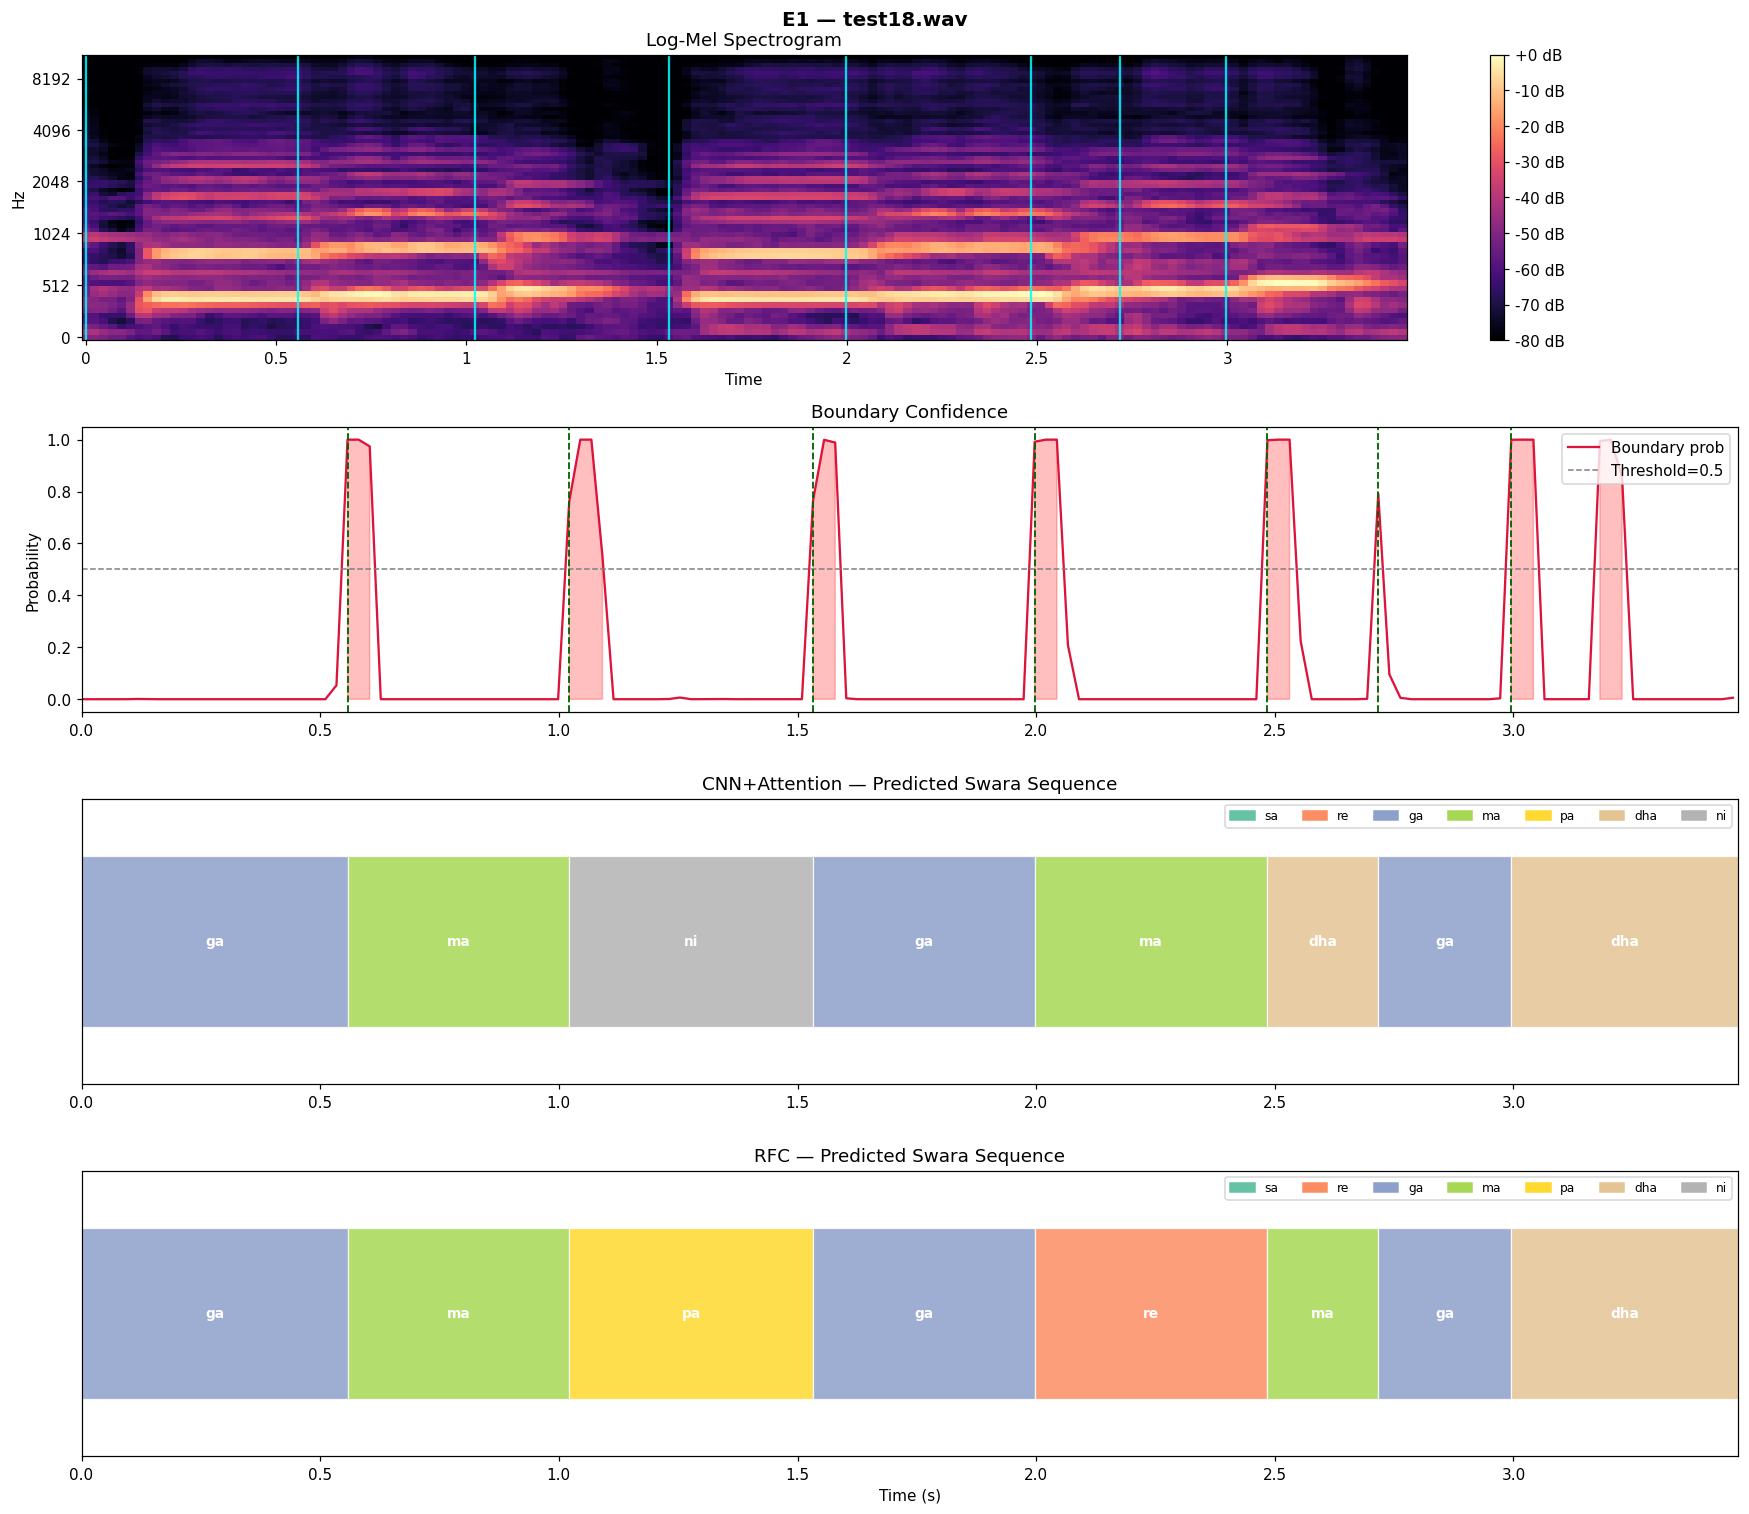

Processing files:  95%|█████████▍| 18/19 [00:48<00:02,  2.89s/it]

Saved visualization → /content/E1_pipeline_output.png

Processing: test19.wav
  [Edge] Dropping last boundary at 3.088s
Boundaries detected: 6
Classifying 7 segments...



Classifying segments:  14%|█▍        | 1/7 [00:00<00:00,  7.69it/s]

  Seg 01  [0.000s – 0.488s]  CNN=ma  RFC=ma



Classifying segments:  29%|██▊       | 2/7 [00:00<00:00,  7.15it/s]

  Seg 02  [0.488s – 0.975s]  CNN=pa  RFC=pa


... (6 outputs left out)


Classifying segments:  86%|████████▌ | 6/7 [00:00<00:00,  7.67it/s]

  Seg 06  [2.415s – 2.879s]  CNN=dha  RFC=dha



Classifying segments: 100%|██████████| 7/7 [00:00<00:00,  7.45it/s]

  Seg 07  [2.879s – 3.357s]  CNN=dha  RFC=ni

CNN+Attention : ma → pa → dha → ma → pa → dha → dha
RFC           : ma → pa → dha → ma → pa → dha → ni


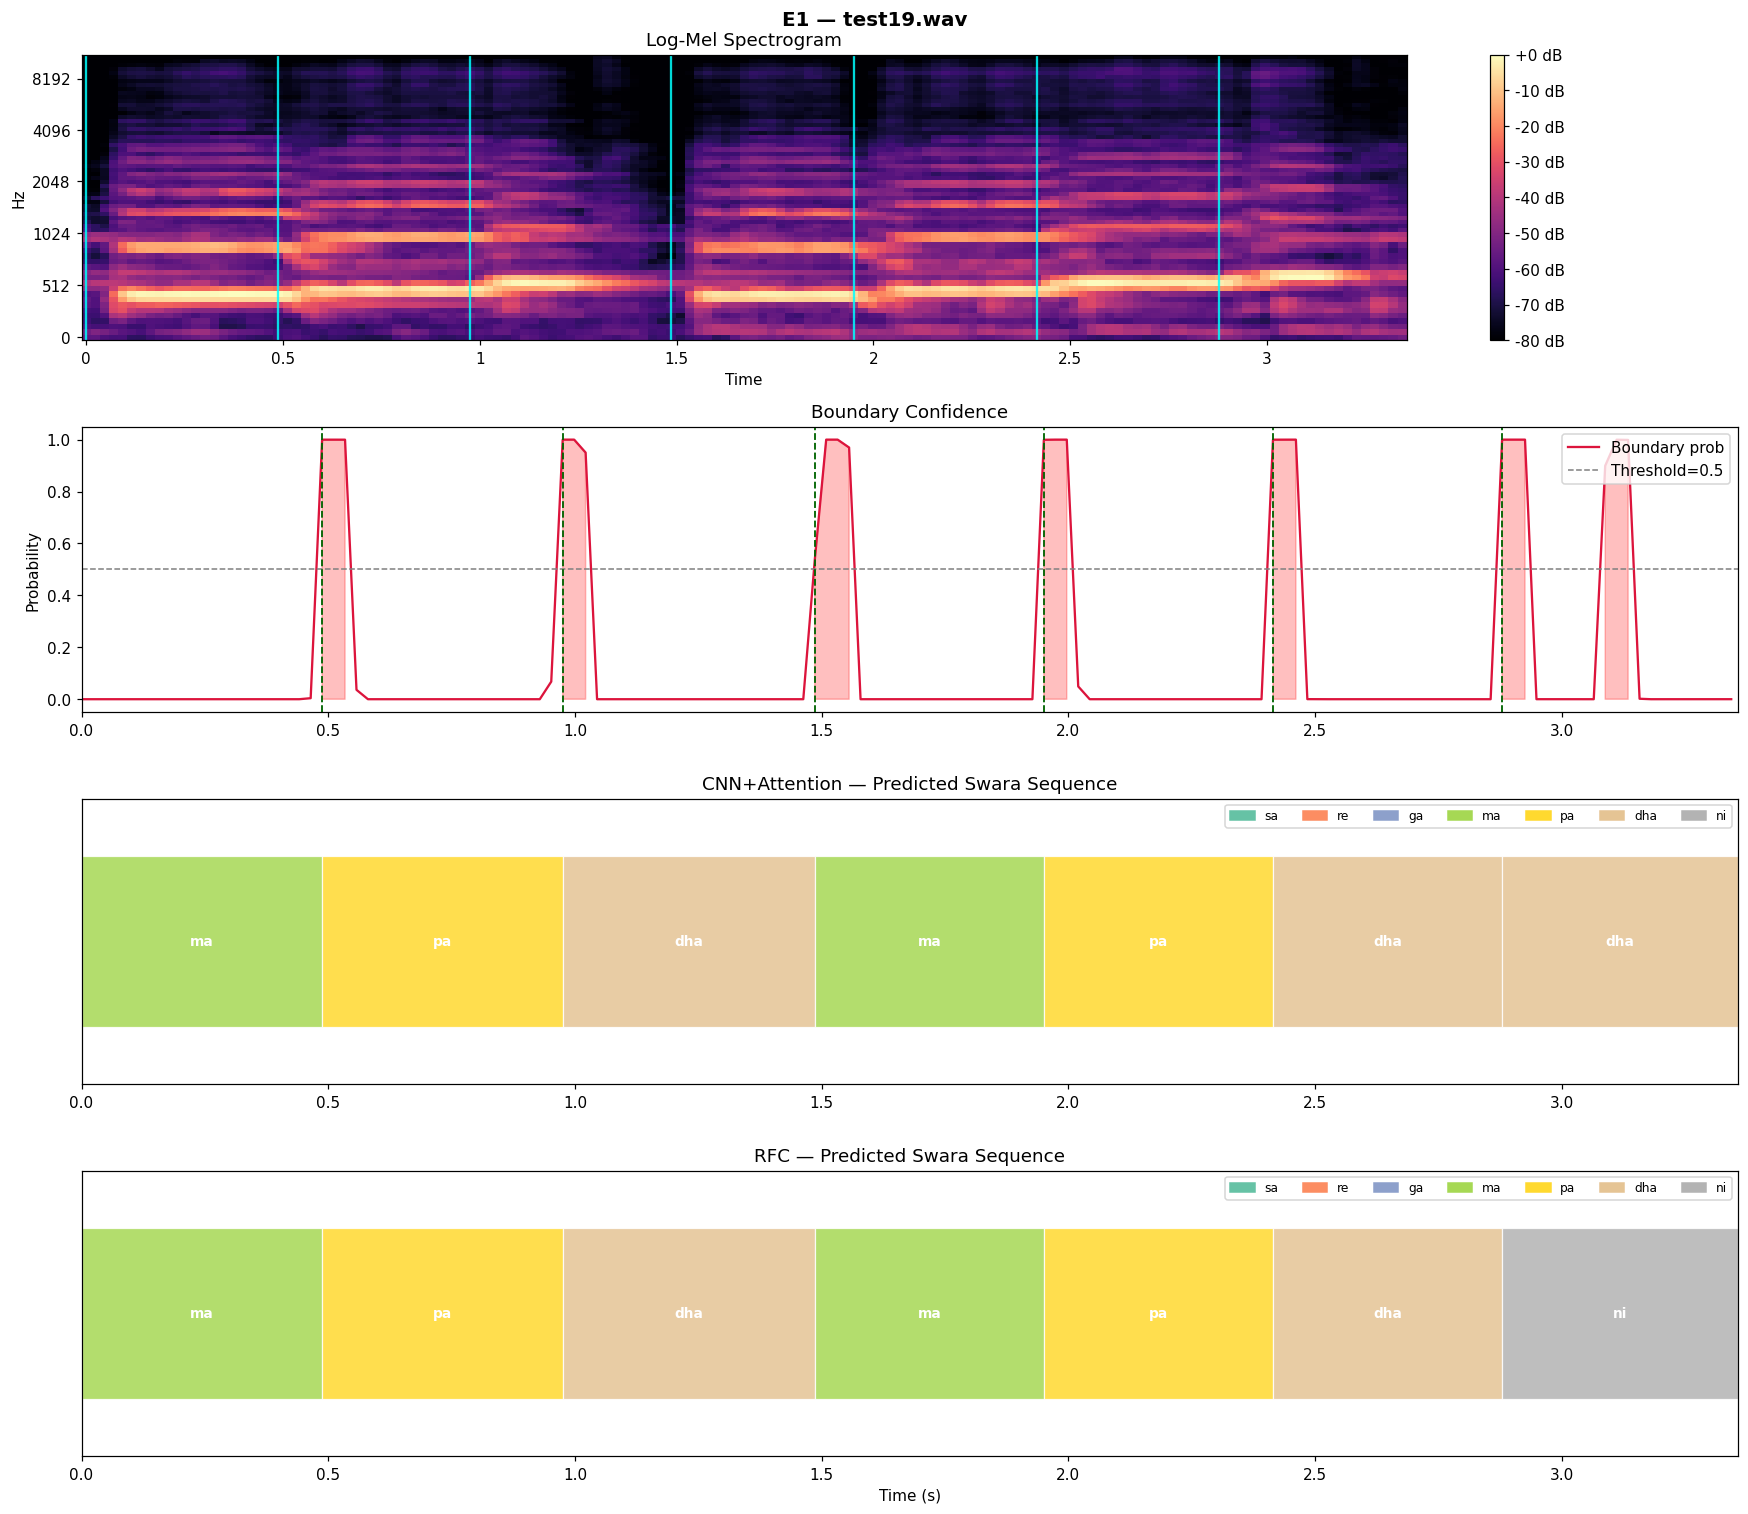

Processing files: 100%|██████████| 19/19 [00:52<00:00,  2.75s/it]

Saved visualization → /content/E1_pipeline_output.png

experiment  clip_name  n_segments                                    cnn_sequence                                    rfc_sequence
        E1  test1.wav          10 sa → re → re → sa → re → sa → re → ga → re → ga sa → sa → re → sa → re → sa → re → ga → re → ma
        E1  test2.wav           7                sa → re → ga → sa → re → ga → ma                sa → re → ga → sa → re → ga → ma
        E1  test3.wav           7                re → ga → ma → re → ga → ma → re                re → re → ma → re → re → ma → ma
        E1  test4.wav           6                    ga → ma → ga → ma → pa → dha                    ga → ma → ga → ma → pa → dha
        E1  test5.wav           7              ma → pa → dha → ma → pa → dha → ni              ma → pa → dha → ma → pa → dha → ni
        E1  test6.wav           8       pa → dha → dha → pa → dha → dha → ni → sa         pa → dha → dha → pa → ma → sa → sa → sa
        E1  test7.wav           7  

In [16]:
from google.colab import files as colab_files

print("Upload one or more test flute .wav files:")
uploaded = colab_files.upload()

rows = []
for audio_file in tqdm(uploaded.keys(), desc="Processing files"):
    print(f"\n{'='*60}\nProcessing: {audio_file}\n{'='*60}")
    try:
        cnn_seq, rfc_seq, segs = run_pipeline(audio_file)
        rows.append({
            "experiment":   EXPERIMENT,
            "clip_name":    audio_file,
            "n_segments":   len(segs),
            "cnn_sequence": " → ".join(cnn_seq),
            "rfc_sequence": " → ".join(rfc_seq),
        })
    except Exception as e:
        print(f"  ERROR: {e}")
        rows.append({"experiment": EXPERIMENT, "clip_name": audio_file,
                     "n_segments": 0, "cnn_sequence": "ERROR", "rfc_sequence": "ERROR"})

results_df = pd.DataFrame(rows)
print("\n" + "="*60)
print(results_df.to_string(index=False))

csv_path = os.path.join(SAVE_DIR, f"{EXPERIMENT}_results.csv")
results_df.to_csv(csv_path, index=False)
print(f"\nSaved → {csv_path}")
